# Analyse exploratoire (EDA) — Compagnon Immobilier

**Projet :** Compagnon Immobilier · **Date :** 20/10/2026

Ce notebook rassemble l'analyse exploratoire de l'équipe, organisée en trois parties et une synthèse :

- **A. La cible** : construction du prix médian au m² à partir de DVF+, règles d'exclusion, nombre de ventes nécessaire pour une médiane fiable.
- **B. Relations à l'intérieur de chaque source**, regroupées par dimension : revenus des habitants, parc de logement et vacance, délinquance, équipements, annonces immobilières.
- **C. Relations avec la cible**, par dimension : caractéristiques des biens vendus, revenus, temps et financement, parc de logement et vacance, délinquance, équipements.
- **Synthèse** : constats par type de données, tableau des variables candidates pour la modélisation, prérequis à l'intégration et points à traiter au preprocessing.

Les prix de 2025, année réservée au test, ne sont regardés dans aucune analyse.

### Avant de lancer

- **Fichiers préparés** (`01_preparation`, dans `data/processed/`) : `dvf_plus_residentiel.parquet` (bloc 2, ou source `dvf_residentiel`), `dvf_plus_echantillon_apprentissage.parquet` (bloc 3), `liaison_commune_bv2022.parquet` (bloc 1), `cible_commune_annee.parquet` (bloc 4), `filosofi_commune_2014_2021.parquet` (bloc 5), `logement_commune_2022.parquet` (bloc 7), `lovac_commune_annee.parquet` (bloc 9).
- **Sources brutes** (`00_telechargement`, dans `data/raw/`) : `logement`, `lovac`, `delinquance`, `taux`, et les annonces `ech_annonces_ventes_68.csv` et `ech_annonces_locations_68.csv`.
- **Accès à internet** : les cartes utilisent les contours des départements et des communes du dépôt GitHub `gregoiredavid/france-geojson`.
- **Bibliothèques** en plus de la préparation : `geopandas` (cartes) et `scikit-learn` (régressions de C2 et C3).
- **Mémoire** : la population DVF+ (plus de 8 millions de ventes) est chargée en A et en C5 ; prévoir plusieurs Go de mémoire vive.

Les analyses ont été écrites par plusieurs membres de l'équipe : leur contenu est repris tel quel ; seuls les chemins, la lecture des fichiers préparés et quelques erreurs de code ont été corrigés.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from IPython.display import display

# config.py se trouve à la racine du projet, dossier parent de ce notebook
sys.path.insert(0, str(Path.cwd().parent))
from config import DATA_RAW, DATA_OUT

pd.set_option("display.max_columns", None)


# Tailles d'effet utilisées dans tout le notebook
def eta2_kruskal(groupes):
    """Kruskal-Wallis + taille d'effet eta² (part de la variabilité des rangs expliquée par les groupes)."""
    H, p = stats.kruskal(*groupes)
    k, n = len(groupes), sum(len(g) for g in groupes)
    return H, p, (H - k + 1) / (n - k)


def r_mannwhitney(a, b):
    """Mann-Whitney + taille d'effet r rang-bisérial (de -1 à 1).
    r > 0 : les valeurs de a ont tendance à être plus élevées que celles de b.
    (1 + r) / 2 = probabilité qu'une valeur tirée dans a dépasse une valeur tirée dans b."""
    U, p = stats.mannwhitneyu(a, b)
    return U, p, 2 * U / (len(a) * len(b)) - 1

# A. La cible

**Contributeurs :** Cécile NAUDET · **Date :** octobre 2026

**Objectif :** construire la variable cible du projet à partir de DVF+ et la décrire.

| Élément | Choix |
|---|---|
| Source | DVF+ (Cerema), table mutation, filtrée par le bloc 2 de la préparation. Voir l'audit. |
| Périmètre | Ventes d'un seul logement ancien (une maison ou un appartement), dans une seule commune, en France métropolitaine. VEFA et DOM exclus. L'Alsace-Moselle n'est pas couverte par DVF+. |
| Période étudiée | 2014-2023. L'année 2025 est réservée au test et n'est pas regardée. L'année 2024 est mise de côté en attendant la décision du groupe. |
| Cible | Prix médian au m² par commune et par année, accompagné du nombre de ventes. |
| Données utilisées | La population complète (8 181 968 ventes) pour construire la cible. L'échantillon d'apprentissage (835 288 ventes) pour étudier les relations entre variables (C1). |

**Chargements de la population**

In [2]:
# Population DVF+ filtrée (bloc 2 de la préparation)
cols = ["idmutation", "coddep", "l_codinsee", "anneemut", "datemut",
        "libtypbien", "valeurfonc", "sbati"]
pop = pd.read_parquet(DATA_OUT / "dvf_plus_residentiel.parquet", columns=cols)

# On ne garde que les années hors test
pop = pop[pop["anneemut"] <= 2023]

print(pop.shape)
print(round(pop.memory_usage(deep=True).sum() / 1e9, 2), "Go en mémoire")
pop.head()

(8181968, 8)
0.83 Go en mémoire


,idmutation,coddep,l_codinsee,anneemut,datemut,libtypbien,valeurfonc,sbati
0,16,01,01378,2014,2014-05-20,UNE MAISON,222300.0,88.0
1,476,01,01160,2014,2014-02-28,UNE MAISON,1084000.0,212.0
2,8975,01,01022,2014,2014-09-29,UNE MAISON,139000.0,90.0
3,9113,01,01210,2014,2014-12-11,UN APPARTEMENT,75700.0,41.0
4,9498,01,01185,2014,2014-04-11,UNE MAISON,58000.0,39.0


### A1. Construction de la cible

**Variables :** `valeurfonc` (prix de vente, en €), `sbati` (surface bâtie, en m²), `libtypbien` (maison ou appartement), `l_codinsee` (code de la commune), `anneemut` (année de la vente).

**Pourquoi regarder cela :** la cible est un prix médian au m² par commune et par année. Avant de la calculer, il faut vérifier que le prix au m² de chaque vente est plausible. Une valeur foncière nulle ou une surface erronée peut fausser la médiane, surtout dans les petites communes où il y a peu de ventes.

**Méthode :**
1. calculer le prix au m² de chaque vente ;
2. repérer les valeurs manquantes, nulles et extrêmes, par type de bien ;
3. examiner quelques cas extrêmes pour fixer des règles d'exclusion ;
4. calculer la table commune × année : prix médian au m² et nombre de ventes.

#### 1. Calcul du prix au m² de chaque vente

In [3]:
# Variables construites
pop["prix_m2"] = pop["valeurfonc"] / pop["sbati"]
pop["type_bien"] = pop["libtypbien"].map({"UNE MAISON": "maison",
                                          "UN APPARTEMENT": "appartement"})

# Distribution du prix au m² par type, avec les centiles extrêmes
pop.groupby("type_bien")["prix_m2"].describe(
    percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
).round(0)

,count,mean,std,min,1%,5%,50%,95%,99%,max
type_bien,,,,,,,,,,
appartement,3490738.0,3707.0,12246.0,0.0,441.0,948.0,2910.0,9639.0,13336.0,19545455.0
maison,4688611.0,2286.0,17652.0,0.0,213.0,543.0,1888.0,5034.0,8409.0,25781250.0


**Constat :**
- Le prix médian au m² est de 2 910 € pour les appartements et de 1 888 € pour les maisons.
- La distribution est très asymétrique : la moyenne dépasse nettement la médiane, et les maximums sont impossibles (19,5 millions d'euros au m² pour un appartement, 25,8 millions pour une maison).
- Entre le 1er et le 99e centile, le prix au m² va de 441 à 13 336 € pour les appartements, et de 213 à 8 409 € pour les maisons.

#### 2. Valeurs manquantes, nulles ou extrêmes

In [4]:
# Cas qui empêchent de calculer un prix au m² correct
print("valeurfonc manquante :", pop["valeurfonc"].isna().sum())
print("valeurfonc = 0       :", (pop["valeurfonc"] == 0).sum())
print("sbati = 0            :", (pop["sbati"] == 0).sum())

# Indicatrice : True si la valeur foncière est à 0
pop["vf_nulle"] = pop["valeurfonc"] == 0

# Nombre de ventes à 0 € par année
pop.groupby("anneemut")["vf_nulle"].sum()

valeurfonc manquante : 2619
valeurfonc = 0       : 550
sbati = 0            : 0


anneemut
2014    299
2015    234
2016     17
2017      0
2018      0
2019      0
2020      0
2021      0
2022      0
2023      0
Name: vf_nulle, dtype: int64

In [5]:
# Valeurs foncières manquantes par année (même idée que pour les valeurs à 0)
print(pop["valeurfonc"].isna().groupby(pop["anneemut"]).sum())

# Prix au m² très bas (hors valeurs à 0) et très hauts
bas = pop[(pop["prix_m2"] > 0) & (pop["prix_m2"] < 100)]
haut = pop[pop["prix_m2"] > 20000]

print("\nPrix au m² entre 0 et 100 € :", len(bas))
print(bas["type_bien"].value_counts())
print("\nPrix au m² au-dessus de 20 000 € :", len(haut))
print(haut["type_bien"].value_counts())
print(haut["coddep"].value_counts().head(5))

display(bas.sample(8, random_state=42))
display(haut.sample(8, random_state=42))

anneemut
2014      4
2015     45
2016    298
2017    299
2018    217
2019    349
2020    367
2021    399
2022    333
2023    308
Name: valeurfonc, dtype: int64

Prix au m² entre 0 et 100 € : 28786
type_bien
maison         17348
appartement    11438
Name: count, dtype: int64

Prix au m² au-dessus de 20 000 € : 7743
type_bien
appartement    4229
maison         3514
Name: count, dtype: int64
coddep
75    3453
06     892
83     702
92     432
33     398
Name: count, dtype: int64


,idmutation,coddep,l_codinsee,anneemut,datemut,libtypbien,valeurfonc,sbati,prix_m2,type_bien,vf_nulle
7875528,8785559,79,79074,2021,2021-11-17,UNE MAISON,3000.0,76.0,39.473684,maison,False
1068521,13315983,13,13059,2023,2023-07-18,UNE MAISON,1.0,105.0,0.009524,maison,False
3141673,9806268,34,34183,2021,2021-06-30,UNE MAISON,8500.0,165.0,51.515152,maison,False
4283290,65388,45,45232,2014,2014-02-27,UNE MAISON,1014.0,101.0,10.039604,maison,False
2092897,1720007,28,28168,2015,2015-07-02,UN APPARTEMENT,1.0,59.0,0.016949,appartement,False
5616028,11646590,61,61098,2022,2022-12-29,UNE MAISON,5000.0,55.0,90.909091,maison,False
4539956,9620862,49,49180,2021,2021-11-29,UNE MAISON,7060.0,96.0,73.541667,maison,False
6913164,615108,75,75111,2014,2014-03-24,UN APPARTEMENT,1000.0,35.0,28.571429,appartement,False


,idmutation,coddep,l_codinsee,anneemut,datemut,libtypbien,valeurfonc,sbati,prix_m2,type_bien,vf_nulle
7147493,11487421,75,75108,2022,2022-04-01,UN APPARTEMENT,1095000.0,48.0,22812.500000,appartement,False
483332,12430807,06,06104,2023,2023-09-06,UNE MAISON,5400000.0,160.0,33750.000000,maison,False
2905981,10481471,33,33236,2022,2022-12-20,UNE MAISON,2400000.0,87.0,27586.206897,maison,False
7075743,7653921,75,75101,2020,2020-02-04,UN APPARTEMENT,5900000.0,152.0,38815.789474,appartement,False
8141457,4883955,83,83119,2017,2017-12-21,UNE MAISON,2350000.0,61.0,38524.590164,maison,False
7082141,7999303,75,75118,2020,2020-07-17,UN APPARTEMENT,380000.0,16.0,23750.000000,appartement,False
7128147,10575234,75,75107,2022,2022-12-15,UN APPARTEMENT,5400000.0,220.0,24545.454545,appartement,False
384290,6607514,06,06029,2019,2019-09-25,UNE MAISON,10500000.0,378.0,27777.777778,maison,False


**Résultat :** Les 550 ventes à 0 € se concentrent entre 2014 et 2016 (299 en 2014, 234 en 2015, 17 en 2016), et il n'y en a aucune à partir de 2017. 

**Interprétation :** Ce ne sont donc pas des ventes symboliques, qu'on retrouverait chaque année, mais probablement un défaut d'enregistrement des premières années de la base. La documentation du Cerema ne l'explique pas : c'est une hypothèse.

**Impact projet :** Ces ventes seront exclues. Elles ne représentent pas un prix de marché, et elur nombre trop faible pour pseser sur les résultats.

In [6]:
# Valeurs foncières manquantes par année
print(pop["valeurfonc"].isna().groupby(pop["anneemut"]).sum())

# Nombre de ventes touchées selon plusieurs seuils possibles
for s in [10, 50, 100]:
    print(f"prix au m² < {s} € :", ((pop["prix_m2"] > 0) & (pop["prix_m2"] < s)).sum())
for s in [20000, 30000, 50000]:
    print(f"prix au m² > {s} € :", (pop["prix_m2"] > s).sum())

# Exemples aux deux bouts
tres_bas = pop[(pop["prix_m2"] > 0) & (pop["prix_m2"] < 50)]
tres_haut = pop[pop["prix_m2"] > 30000]
print(tres_haut["coddep"].value_counts().head(5))

display(tres_bas.sample(8, random_state=42))
display(tres_haut.sample(8, random_state=42))

anneemut
2014      4
2015     45
2016    298
2017    299
2018    217
2019    349
2020    367
2021    399
2022    333
2023    308
Name: valeurfonc, dtype: int64
prix au m² < 10 € : 7955
prix au m² < 50 € : 17607
prix au m² < 100 € : 28786
prix au m² > 20000 € : 7743
prix au m² > 30000 € : 2021
prix au m² > 50000 € : 540
coddep
75    542
06    261
83    260
33    147
92     90
Name: count, dtype: int64


,idmutation,coddep,l_codinsee,anneemut,datemut,libtypbien,valeurfonc,sbati,prix_m2,type_bien,vf_nulle
7087417,8308910,75,75109,2020,2020-12-23,UN APPARTEMENT,1.0,107.0,0.009346,appartement,False
8681989,5896021,88,88195,2018,2018-10-30,UNE MAISON,800.0,50.0,16.000000,maison,False
4468584,8718821,48,48193,2021,2021-08-30,UNE MAISON,3052.0,65.0,46.953846,maison,False
188849,10392219,03,03206,2022,2022-06-01,UNE MAISON,3000.0,72.0,41.666667,maison,False
8610952,1227909,87,87085,2015,2015-10-05,UNE MAISON,16.0,103.0,0.155340,maison,False
559533,885339,07,07147,2014,2014-06-25,UNE MAISON,1.0,90.0,0.011111,maison,False
7091352,8529215,75,75104,2020,2020-09-22,UN APPARTEMENT,250.0,18.0,13.888889,appartement,False
318292,2642420,06,06088,2016,2016-11-21,UN APPARTEMENT,3330.0,102.0,32.647059,appartement,False


,idmutation,coddep,l_codinsee,anneemut,datemut,libtypbien,valeurfonc,sbati,prix_m2,type_bien,vf_nulle
4223905,12575362,44,44184,2023,2023-12-11,UNE MAISON,2707400.0,80.0,3.384250e+04,maison,False
7166818,12388450,75,75108,2023,2023-04-11,UN APPARTEMENT,4940000.0,148.0,3.337838e+04,appartement,False
5374412,11845710,59,59378,2022,2022-10-28,UNE MAISON,722590020.0,119.0,6.072185e+06,maison,False
2942804,12787486,33,33529,2023,2023-12-18,UNE MAISON,9350000.0,198.0,4.722222e+04,maison,False
2935227,12287634,33,33236,2023,2023-07-28,UNE MAISON,2000000.0,54.0,3.703704e+04,maison,False
7132564,10800160,75,75106,2022,2022-05-04,UN APPARTEMENT,465000.0,10.0,4.650000e+04,appartement,False
408799,8057990,06,06029,2020,2020-07-02,UN APPARTEMENT,3187537.0,99.0,3.219734e+04,appartement,False
7184823,13263365,75,75107,2023,2023-09-06,UN APPARTEMENT,4200000.0,139.0,3.021583e+04,appartement,False


**Résultat :**
- Les valeurs foncières à 0 € (550) se trouvent entre 2014 et 2016, et les valeurs manquantes (2 619) à partir de 2016. Le total des deux reste stable, autour de 300 par an : il s'agit probablement d'un changement de codage, une valeur absente étant notée 0 jusqu'en 2015, puis laissée vide. Les deux cas sont traités ensemble comme « valeur foncière absente ».
- Sous 50 € au m² (17 607 ventes), les exemples examinés ne correspondent pas à des prix de marché : valeurs de 1 € à quelques centaines d'euros pour un logement entier. Certains cas peuvent être des viagers (seul le bouquet est déclaré) ou des ventes de parts, que DVF+ ne permet pas de repérer.
- Au-dessus de 50 000 € au m² (540 ventes), on trouve des erreurs manifestes, par exemple 722 millions d'euros pour une maison de 119 m². Entre 30 000 et 50 000 €, les ventes examinées sont en majorité plausibles : Paris (7e, 8e), Lège-Cap-Ferret.

**Avis métier :** la fiche de la DGFiP sur les méthodes d'évaluation rappelle que tous les prix déclarés ne reflètent pas le marché : ventes entre proches, adjudications. Elle conseille aussi, quand le marché est peu actif, d'élargir la zone géographique ou la période d'observation. Les fourchettes retenues ont été comparées avec l'application DVF d'Etalab (explore.data.gouv.fr) : prix médian de 179 € au m² à Ninville (52), plus de 26 000 € au m² dans une section de Megève (74). Cette application s'appuie sur DVF et non sur DVF+, et ne couvre pas exactement la même période : elle donne un ordre de grandeur, pas une référence exacte.

**Interprétation :** des prix au m² très bas ou très élevés peuvent être réels. Une recherche complémentaire le confirme : médiane de 179 € au m² à Ninville (52), et plus de 26 000 € au m² dans une section de Megève. Les seuils sont donc choisis larges, pour ne retirer que les valeurs impossibles.

**Action :** trois règles d'exclusion, appliquées avant le calcul de la cible : valeur foncière absente, prix au m² inférieur à 50 €, prix au m² supérieur à 50 000 €.

**Biais / limites :** les seuils restent un choix. Les ventes entre proches et les viagers, dont le prix déclaré n'est pas un prix de marché, ne peuvent pas être repérés. Pour une maison, le prix au m² rapporte aussi la valeur du terrain à la seule surface bâtie.

#### Règles et Table cible

In [7]:
def regles_exclusion(d, afficher=False):
    """Applique les règles de A1 et ajoute le prix au m² et le type de bien.
    Garde les ventes avec une valeur foncière et un prix au m² entre 50 et 50 000 €."""
    prix_m2 = d["valeurfonc"] / d["sbati"]
    r1 = d["valeurfonc"].notna() & (d["valeurfonc"] > 0)   # valeur foncière présente
    r2 = prix_m2 >= 50                                      # seuil bas
    r3 = prix_m2 <= 50000                                   # seuil haut

    if afficher:
        print("Ventes au départ           :", len(d))
        print("Valeur foncière présente   :", r1.sum())
        print("Prix au m² >= 50 €         :", (r1 & r2).sum())
        print("Prix au m² <= 50 000 €     :", (r1 & r2 & r3).sum())

    garde = r1 & r2 & r3
    sortie = d[garde].copy()
    sortie["prix_m2"] = prix_m2[garde]
    sortie["type_bien"] = sortie["libtypbien"].map({"UNE MAISON": "maison",
                                                    "UN APPARTEMENT": "appartement"})
    return sortie

# Application à la population, avec affichage de l'entonnoir
ventes = regles_exclusion(pop, afficher=True)
ventes["est_maison"] = ventes["type_bien"] == "maison"

# Table cible : une ligne par commune et par année, calculée ici en mémoire pour A2
# (la table cible du projet est produite par le bloc 4 de la préparation)
cible = (ventes.groupby(["l_codinsee", "anneemut"])
               .agg(coddep=("coddep", "first"),
                    nb_ventes=("prix_m2", "size"),
                    prix_m2_median=("prix_m2", "median"),
                    part_maisons=("est_maison", "mean"))
               .reset_index()
               .rename(columns={"l_codinsee": "code_commune", "anneemut": "annee"}))

print(cible.shape)
cible.head()

Ventes au départ           : 8181968
Valeur foncière présente   : 8178799
Prix au m² >= 50 €         : 8161192
Prix au m² <= 50 000 €     : 8160652
(307479, 6)


,code_commune,annee,coddep,nb_ventes,prix_m2_median,part_maisons
0,01001,2014,01,10,1892.775557,1.0
1,01001,2015,01,10,1781.550543,1.0
2,01001,2016,01,7,1807.228916,1.0
3,01001,2017,01,14,1826.949025,1.0
4,01001,2018,01,9,1932.857143,1.0


** Résultats **
- Entonnoir : 8 181 968 ventes → 8 178 799 avec une valeur foncière → 8 161 192 après le seuil bas → 8 160 652 après le seuil haut. Au total, 21 316 ventes sont exclues (0,26 %).
- La table cible compte 307 479 lignes commune × année, avec pour chacune le nombre de ventes, le prix médian au m² et la part de maisons. Aucun seuil de maille n'est encore appliqué.

### A2. Couverture de la cible et seuil de maille

**Variables :** `nb_ventes`, `prix_m2_median` (table cible).

**Pourquoi regarder cela :** une médiane calculée sur peu de ventes change beaucoup d'une année à l'autre, par simple hasard. Il faut choisir un nombre minimum de ventes pour qu'une commune soit retenue une année donnée. Plus ce seuil est haut, plus la cible est fiable, mais moins elle couvre de communes. Cette analyse prépare la décision du groupe du 14/10.

**Méthode :**
1. pour plusieurs seuils, mesurer ce qu'on garde : lignes commune × année, communes, ventes ;
2. mesurer comment la variation annuelle du prix médian se disperse selon le nombre de ventes.

#### 1. Seuil de maille

In [8]:
seuils = [1, 5, 10, 20, 30, 50]
total_ventes = cible["nb_ventes"].sum()
lignes = []

for s in seuils:
    ok = cible["nb_ventes"] >= s
    # Communes qui atteignent le seuil chacune des 10 années
    annees_ok = ok.groupby(cible["code_commune"]).sum()
    lignes.append({
        "seuil": s,
        "lignes gardées (%)": round(ok.mean() * 100, 1),
        "ventes couvertes (%)": round(cible.loc[ok, "nb_ventes"].sum() / total_ventes * 100, 1),
        "communes, au moins 1 an": cible.loc[ok, "code_commune"].nunique(),
        "communes, 10 ans sur 10": (annees_ok == 10).sum(),
    })

pd.DataFrame(lignes)

,seuil,lignes gardées (%),ventes couvertes (%),"communes, au moins 1 an","communes, 10 ans sur 10"
0,1,100.0,100.0,34863,22616
1,5,59.2,96.4,26813,10865
2,10,36.2,90.7,17012,6595
3,20,19.8,82.3,9077,3796
4,30,13.7,76.8,6102,2700
5,50,8.5,69.3,3682,1682


**Constat :**
- Plus le seuil est haut, plus on perd de communes. Mais on perd peu de ventes : avec un seuil de 10 ventes, on garde 36 % des lignes et 91 % des ventes.
- Les communes qui ont des ventes chaque année au-dessus du seuil sont 6 595 avec un seuil de 10, et 3 796 avec un seuil de 20.

**Méthode de vérification :** manipulation de données (écart interquartile par classe).

#### Dispersion de la variation annuelle selon le nombre de ventes

,count,25%,50%,75%,IQR
classe,,,,,
1-4,118587.0,-23.2,1.9,35.4,58.6
5-9,54191.0,-12.7,2.5,20.7,33.3
10-19,37966.0,-7.4,3.3,15.1,22.5
20-29,14473.0,-4.5,3.4,12.0,16.5
30-49,12787.0,-3.0,3.3,10.5,13.4
50+,21494.0,-0.8,3.4,7.8,8.6


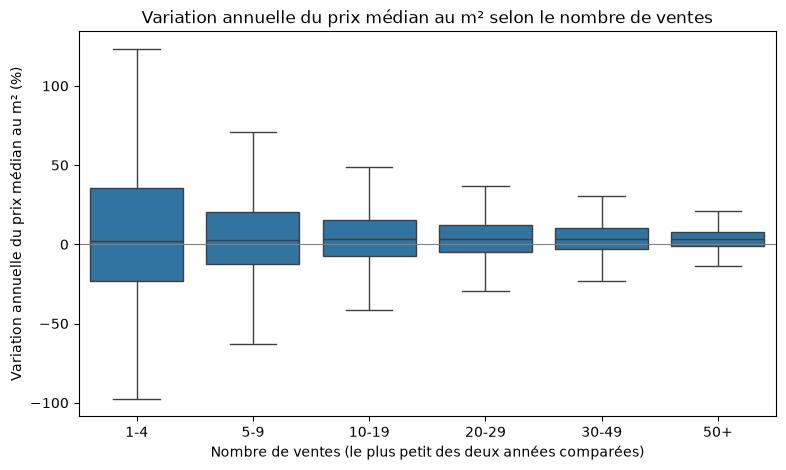

In [9]:
c = cible.sort_values(["code_commune", "annee"]).copy()

# Valeurs de l'année précédente, pour la même commune
c["annee_prec"] = c.groupby("code_commune")["annee"].shift(1)
c["prix_prec"] = c.groupby("code_commune")["prix_m2_median"].shift(1)
c["nb_prec"] = c.groupby("code_commune")["nb_ventes"].shift(1)

# On ne garde que deux années qui se suivent (pas de trou dans la série)
c = c[c["annee"] - c["annee_prec"] == 1].copy()
c["variation"] = (c["prix_m2_median"] / c["prix_prec"] - 1) * 100

# Classe selon le plus petit nombre de ventes des deux années comparées
c["nb_min"] = c[["nb_ventes", "nb_prec"]].min(axis=1)
c["classe"] = pd.cut(c["nb_min"], bins=[0, 4, 9, 19, 29, 49, np.inf],
                     labels=["1-4", "5-9", "10-19", "20-29", "30-49", "50+"])

# Dispersion de la variation dans chaque classe
resume = c.groupby("classe", observed=True)["variation"].describe(percentiles=[0.25, 0.5, 0.75])
resume["IQR"] = resume["75%"] - resume["25%"]
display(resume[["count", "25%", "50%", "75%", "IQR"]].round(1))

# Graphique
plt.figure(figsize=(9, 5))
sns.boxplot(data=c, x="classe", y="variation", showfliers=False)
plt.axhline(0, color="grey", lw=0.8)
plt.xlabel("Nombre de ventes (le plus petit des deux années comparées)")
plt.ylabel("Variation annuelle du prix médian au m² (%)")
plt.title("Variation annuelle du prix médian au m² selon le nombre de ventes")
plt.show()

**Résultat :** quand il y a peu de ventes, la variation annuelle du prix médian change beaucoup d'une année sur l'autre. C'est le cas d'une grande partie des communes : 46 % des comparaisons d'une année à l'autre portent sur moins de 5 ventes.

**Interprétation :** les prix augmentent d'environ 3 % par an. Avec 10 à 19 ventes, l'écart interquartile est de 22,5 points, donc bien plus grand que cette hausse. Dans les petites communes, la variation du prix médian dépend surtout des quelques biens vendus dans l'année, et pas du marché. On ne voit pas de seuil évident sur le graphique : il faudra choisir entre garder beaucoup de communes et avoir une cible fiable.

**Avis métier :** la DGFiP conseille, quand il y a peu de ventes, d'élargir la zone ou la période étudiée plutôt que de se baser sur quelques ventes.

**Impact projet :** la cible par commune et par année n'est fiable que pour une partie des communes. Le seuil choisi fixe le nombre de communes que le modèle pourra prédire.

**Action envisagée :** Etudier en groupe trois options : un seuil de 10 ventes, un seuil de 20 ventes, ou regrouper les petites communes (bassin de vie, ou médiane sur 2 ou 3 ans). La dernières méthode est celle préconisée par le DGFip mais demande un travail plus conséquent.

# B. Relations à l'intérieur de chaque source

Pour chaque dimension, on regarde comment les variables se rapprochent ou se distinguent les unes des autres (redondances), comment elles se répartissent sur le territoire et comment elles évoluent dans le temps. Ces analyses ne font pas intervenir la cible.

| Dimension | Sources | Contributeurs |
|---|---|---|
| B1. Revenus des habitants | Filosofi | Cécile NAUDET |
| B2. Parc de logement et vacance | Recensement 2022 (logement), LOVAC | Théophyle CHEVET |
| B3. Délinquance enregistrée | SSMSI, base communale | Cécile NAUDET |
| B4. Équipements | BPE 2015, 2020 et 2025 | Christian |
| B5. Annonces immobilières (axe 2) | Annonces de vente et de location du Haut-Rhin | Théophyle CHEVET |

## B1. Revenus des habitants (Filosofi)

**Contributeurs :** Cécile NAUDET · **Date :** 15/10/2026

**Objectif :** comprendre comment les variables de revenu se rapprochent ou se distinguent les unes des autres, puis étudier leur lien avec le prix au m².

| Élément | Choix |
|---|---|
| Source | Filosofi (Insee), revenus disponibles par commune. Voir la fiche d'audit. |
| Maille | Une ligne = une commune × une année. Paris, Lyon et Marseille par arrondissement. |
| Période | 2014-2021 (dernier millésime disponible), entièrement hors période de test (2025). |
| Cible | Prix médian au m² par commune et par année, issu de DVF+ (table cible). |
| Clé de rapprochement | `code_commune` + `annee`. |
| Points d'attention | Indicateurs détaillés publiés seulement pour les communes d'au moins 1 000 ménages ou 2 000 personnes ; codes communes à harmoniser entre millésimes. |

In [11]:
# Filosofi assemblé par le bloc 5 de la préparation (une ligne = commune × année)
filo = pd.read_parquet(DATA_OUT / "filosofi_commune_2014_2021.parquet")

# Décision de l'audit : on garde les arrondissements, on retire Paris, Lyon et Marseille en commune entière
filo = filo[~filo["code_commune"].isin(["75056", "69123", "13055"])]
print(filo.shape)

(261295, 29)


### B1.1 Redondances entre variables

**Variables :** les 26 variables quantitatives continues et `NBMEN`.

**Pourquoi regarder cela :** plusieurs variables risquent de porter la même information (les trois effectifs, les déciles voisins, les indicateurs d'inégalité). Repérer ces redondances permet de garder une seule variable par groupe pour la suite.

**Méthode :** matrice des corrélations de Spearman, calculée sur les communes qui ont tous les indicateurs (au moins 1 000 ménages ou 2 000 personnes). On utilise Spearman plutôt que Pearson parce que les distributions sont très asymétriques (fiche d'audit, étape 4).

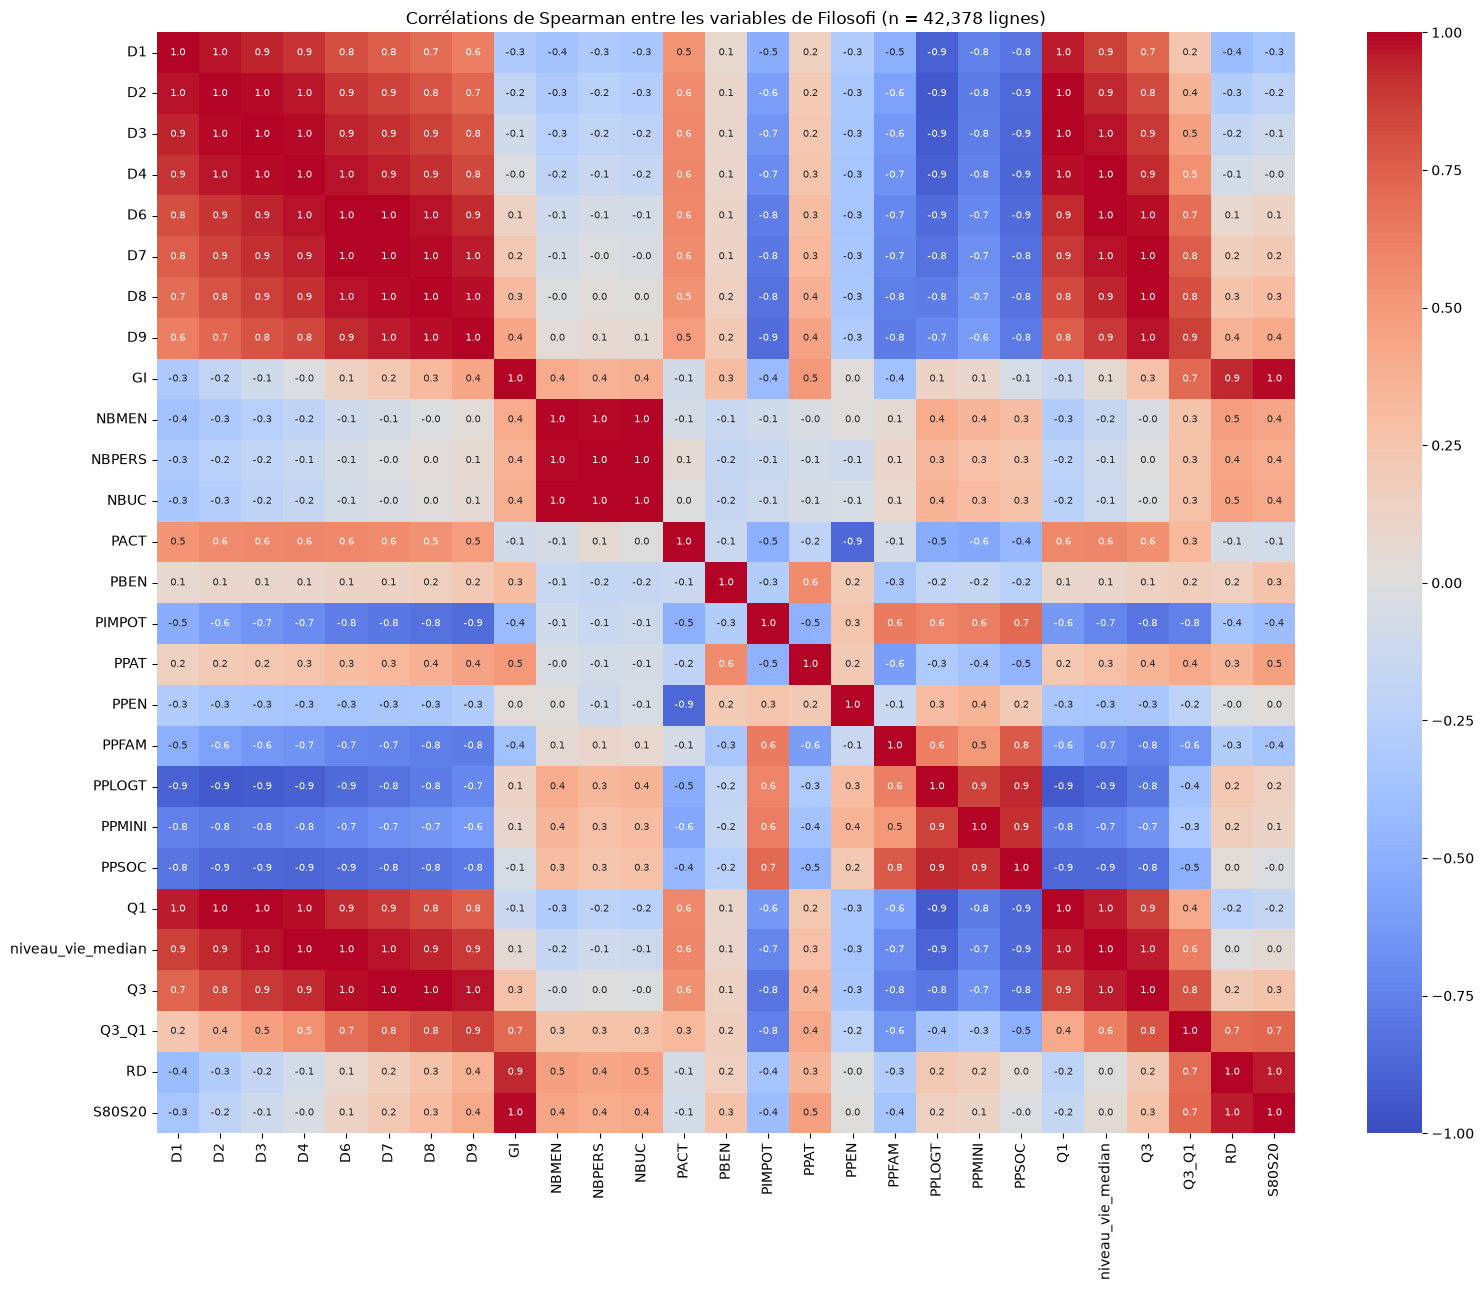

In [12]:
# Communes avec tous les indicateurs (indicateurs détaillés publiés en bloc)
complet = filo.dropna(subset=["D1"])
cols = [c for c in filo.columns if c not in ["code_commune", "annee"]]

corr = complet[cols].corr(method="spearman")

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title(f"Corrélations de Spearman entre les variables de Filosofi (n = {len(complet):,} lignes)")
plt.tight_layout()
plt.show()

**Constat :** la matrice fait apparaître des groupes de variables très liées entre elles (|rho| ≥ 0,9) :
- **Effectifs** : `NBMEN`, `NBPERS` et `NBUC` sont parfaitement liés (rho = 1,0).
- **Position dans la distribution** : les déciles voisins, les quartiles et la médiane sont liés à 0,9-1,0. Le lien s'affaiblit entre les extrêmes (D1 et D9 : 0,6) : le bas et le haut de la distribution ne racontent pas tout à fait la même chose.
- **Inégalités** : `GI`, `RD` et `S80S20` sont liés à 0,9-1,0. `Q3_Q1` est plus lié au niveau de revenu (Q3, D9 : 0,8-0,9) qu'aux inégalités (0,7), parce qu'il est exprimé en euros.
- **Prestations sociales** : `PPSOC` est lié à 0,8-0,9 avec ses sous-parts (`PPLOGT`, `PPMINI`, `PPFAM`), et à −0,9 avec la médiane : plus une commune est aisée, moins les prestations pèsent.
- **Actifs et retraités** : `PACT` et `PPEN` sont liés à −0,9. C'est la même information vue des deux côtés.
- **Impôts** : `PIMPOT` est lié à −0,9 avec D9 : les communes aux hauts revenus sont plus imposées.

Trois informations restent peu liées à la médiane :
- la **taille de la commune** (rho entre −0,2 et 0,1) ;
- les **inégalités** (`GI` : 0,1) ;
- la **part des revenus du patrimoine** (`PPAT` : 0,3).

Les grandes communes sont un peu plus inégalitaires (`NBMEN` et `GI` : 0,4).

**Interprétation :** les 27 variables se résument à environ six informations distinctes. Pour chacune, on peut garder une seule variable :

| Information | Variable proposée | Variables redondantes |
|---|---|---|
| Niveau de revenu | `niveau_vie_median` | déciles, quartiles, `PPSOC` et ses sous-parts, `PIMPOT` |
| Étendue de la distribution | `D1`, `D9` (si besoin) | déciles voisins |
| Inégalités | `GI` ou `RD` | `S80S20`, `Q3_Q1` |
| Profil actifs / retraités | `PACT` | `PPEN` |
| Patrimoine | `PPAT` | `PBEN` en partie (0,6) |
| Taille de la commune | `NBMEN` | `NBPERS`, `NBUC` |

`RD` peut être préféré au Gini : il repose sur deux déciles, donc il est moins sensible aux revenus exceptionnels (fiche d'audit, valeurs extrêmes).

**Biais / limites :** les corrélations sont calculées sur les grandes communes seulement (au moins 1 000 ménages ou 2 000 personnes). Rien ne garantit que les mêmes liens existent dans les petites communes, pour lesquelles seuls la médiane et les effectifs sont connus.

### B1.2 Niveau de vie médian selon la taille de la commune

**Variables :** `niveau_vie_median`, `NBMEN` (regroupé en classes de taille).

**Pourquoi regarder cela :** B1.1 ne portait que sur les grandes communes. La médiane et la taille sont connues pour presque toutes les communes : on peut donc regarder si le niveau de vie diffère entre petites et grandes communes, c'est-à-dire, en gros, entre rural et urbain.

**Méthode :** une seule année (2019), pour ne pas compter chaque commune huit fois. Boxplot de la médiane par classe de taille, puis test de Kruskal-Wallis (les classes ont-elles des médianes différentes ?) et corrélation de Spearman (le lien suit-il un sens ?).

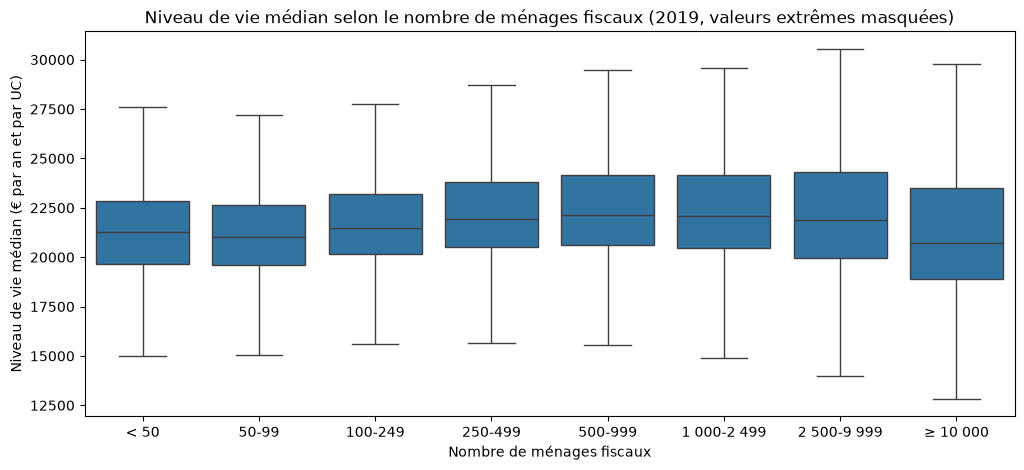

             nb_communes  mediane
taille                           
< 50                 714  21270.0
50-99               6243  21030.0
100-249             9913  21490.0
250-499             6039  21910.0
500-999             3869  22130.0
1 000-2 499         2726  22110.0
2 500-9 999         1436  21880.0
≥ 10 000             418  20705.0


In [13]:
# Une seule année : 2019, dernière année avant le changement de format des fichiers
f19 = filo[filo["annee"] == 2019].dropna(subset=["niveau_vie_median"]).copy()

bornes = [0, 50, 100, 250, 500, 1000, 2500, 10_000, float("inf")]
etiquettes = ["< 50", "50-99", "100-249", "250-499", "500-999",
              "1 000-2 499", "2 500-9 999", "≥ 10 000"]
f19["taille"] = pd.cut(f19["NBMEN"], bins=bornes, labels=etiquettes, right=False)

plt.figure(figsize=(12, 5))
sns.boxplot(data=f19, x="taille", y="niveau_vie_median", showfliers=False)
plt.title("Niveau de vie médian selon le nombre de ménages fiscaux (2019, valeurs extrêmes masquées)")
plt.xlabel("Nombre de ménages fiscaux")
plt.ylabel("Niveau de vie médian (€ par an et par UC)")
plt.show()

print(f19.groupby("taille", observed=True)["niveau_vie_median"]
         .agg(nb_communes="count", mediane="median").round(0))

In [14]:
groupes = [g["niveau_vie_median"].values for _, g in f19.groupby("taille", observed=True)]
H, p, eta2 = eta2_kruskal(groupes)
print(f"Kruskal-Wallis : p-value = {p:.1e} | eta² = {eta2:.3f}")

rho, p = stats.spearmanr(f19["NBMEN"], f19["niveau_vie_median"])
print(f"Spearman : rho = {rho:.2f} | p-value = {p:.1e} | n = {len(f19)}")

Kruskal-Wallis : p-value = 9.1e-205 | eta² = 0.031
Spearman : rho = 0.16 | p-value = 6.9e-177 | n = 31358


**Constat :**
- Le niveau de vie médian suit une légère courbe en cloche selon la taille : 21 030 € pour les communes de 50 à 99 ménages, un maximum de 22 130 € entre 500 et 999 ménages, puis 20 705 € pour les communes de 10 000 ménages et plus.
- L'écart entre classes reste faible (environ 1 400 €, soit 7 %), alors que l'écart à l'intérieur de chaque classe est bien plus grand (boîtes de 3 000 à 4 500 € de hauteur).
- La dispersion augmente avec la taille : les communes de 10 000 ménages et plus ont la boîte la plus haute et descendent jusqu'à 12 800 €.

**Résultat :**
- Kruskal-Wallis : p-value inférieure à 0,05, on rejette H0 : les classes de taille ont des niveaux de vie différents. Mais la taille d'effet est faible (η² = 0,031) : la classe de taille n'explique qu'environ 3 % des écarts de niveau de vie entre communes.
- Spearman : rho = 0,16, lien positif et faible.

**Interprétation :** les communes périurbaines de taille moyenne sont un peu plus aisées que les petites communes rurales et que les grandes villes. Mais la taille explique très peu du niveau de vie : deux communes de même taille peuvent avoir des niveaux de vie très différents. Les tests sont significatifs surtout parce que l'effectif est grand (31 358 communes) ; c'est la faiblesse de l'écart et de rho qui compte.

**Impact projet :** la taille de la commune et le niveau de vie médian portent des informations différentes ; les deux peuvent être gardés comme variables candidates.

### B1.3 Évolution du niveau de vie dans le temps

**Variables :** `niveau_vie_median`, `annee`.

**Pourquoi regarder cela :** le projet porte sur l'évolution des prix. Si le niveau de vie d'une commune change peu d'une année à l'autre, il pourra expliquer les écarts de prix entre communes, mais difficilement leur évolution.

**Méthode :** on garde les communes qui ont une médiane les 8 années (même code de 2014 à 2021). On trace l'évolution de la médiane des communes.

Communes avec une médiane les 8 années : 30891


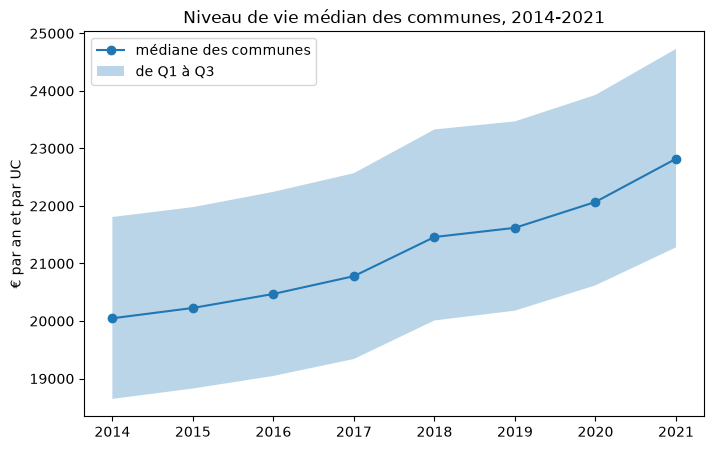

In [15]:
# Une ligne par commune, une colonne par année ; on garde les communes complètes
med = filo.pivot(index="code_commune", columns="annee", values="niveau_vie_median").dropna()
print("Communes avec une médiane les 8 années :", len(med))

# Médiane des communes par année, avec la bande Q1-Q3
q = med.quantile([0.25, 0.5, 0.75])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(med.columns, q.loc[0.5], marker="o", label="médiane des communes")
ax.fill_between(med.columns, q.loc[0.25], q.loc[0.75], alpha=0.3, label="de Q1 à Q3")
ax.set_title("Niveau de vie médian des communes, 2014-2021")
ax.set_ylabel("€ par an et par UC")
ax.legend()
plt.show()

In [ ]:
# 1. Les communes gardent-elles leur rang entre 2014 et 2021 ?
rho, p = stats.spearmanr(med[2014], med[2021])
print(f"Spearman 2014 / 2021 : rho = {rho:.2f} | p-value = {p:.1e} | n = {len(med)}")

# 2. Part des écarts due aux différences entre communes (plutôt qu'au temps)
total = med.stack().var()
entre = med.mean(axis=1).var()
print(f"Part des écarts entre communes : {entre / total * 100:.1f} %")

# 3. Évolutions annuelles : ordre de grandeur
evol = med.pct_change(axis=1).iloc[:, 1:] * 100   # évolution de chaque commune d'une année à l'autre (%)
print("\nÉvolution annuelle (%) :")
print(evol.stack().describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(1))

**Constat :**
- Le niveau de vie médian des communes augmente régulièrement, de 20 050 € en 2014 à environ 22 800 € en 2021 (+1,9 % par an en moyenne). La hausse est plus forte entre 2017 et 2018 (environ +3 %).
- L'écart entre communes aisées et modestes s'élargit un peu : la bande de Q1 à Q3 passe d'environ 3 150 € à 3 450 €.

**Résultat :**
- Spearman entre 2014 et 2021 : rho = 0,90, lien fort (p-value < 0,05) : les communes gardent presque le même classement sur toute la période.
- 88 % des écarts de niveau de vie viennent des différences entre communes, 12 % de l'évolution dans le temps.

**Interprétation :** le niveau de vie médian est une caractéristique stable de la commune : il progresse lentement, et les communes gardent presque le même classement d'une année à l'autre.

**Biais / limites :** le saut de 2018 coïncide avec un changement de méthode de l'Insee (calcul des prestations sociales harmonisé avec l'enquête ERFS, *Sources et méthodes Filosofi 2021*) : une partie de la hausse peut venir de la méthode. Seules les communes au même code les 8 années sont prises en compte (30 891).

**Impact projet :** le niveau de vie devrait surtout expliquer les écarts de **niveau** de prix entre communes. Son lien avec l'**évolution** des prix est testé à part en C2.2.

## B2. Parc de logement et vacance (recensement 2022, LOVAC)

**Contributeurs :** Théophyle CHEVET · **Date :** octobre 2026

Deux sources décrivent le parc de logements :
- la **base logement du recensement 2022** : tout le parc, une seule année, IRIS additionnés par commune (bloc 7 de la préparation) ; B2.1 à B2.5 ;
- **LOVAC** : logements privés vacants, millésimes 2020 à 2026, comparés au recensement ; B2.6 à B2.8.

In [16]:
sns.set_theme(style="whitegrid")
bleu = "#2a78d6"

# Base logement à la commune (bloc 7 : IRIS additionnés, 19 indicateurs en %)
com = pd.read_parquet(DATA_OUT / "logement_commune_2022.parquet")

# On garde les communes d'au moins 50 logements (taux trop instables en dessous)
com = com[~com["petite_commune"]].copy()

# Taille de la commune en 5 tranches (nombre de logements) : du village à la grande ville
com["taille"] = pd.cut(com["P22_LOG"], bins=[0, 500, 2000, 10000, 50000, 2000000],
                       labels=["< 500", "500-2 000", "2 000-10 000", "10 000-50 000", "> 50 000"])
print("Communes étudiées :", len(com))
print(com["taille"].value_counts().sort_index())

Communes étudiées : 32933
taille
< 500            22371
500-2 000         7488
2 000-10 000      2505
10 000-50 000      511
> 50 000            58
Name: count, dtype: int64


### B2.1 Distribution du taux de vacance

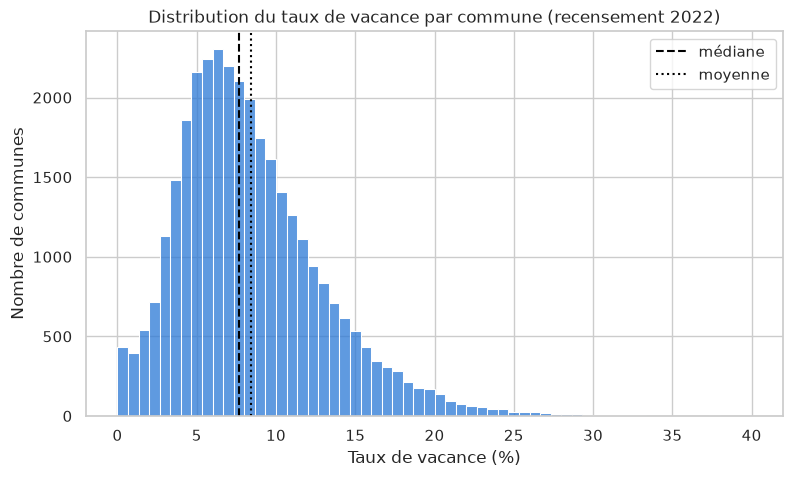

Moyenne : 8.4 % | Médiane : 7.6 %
0.25     5.2
0.75    10.9
0.90    14.5
0.99    22.6
Name: taux_vacance, dtype: float64
Taux national : 8.0 %


In [17]:
plt.figure(figsize=(9, 5))
sns.histplot(com["taux_vacance"], bins=60, color=bleu)
plt.axvline(com["taux_vacance"].median(), color="black", linestyle="--", label="médiane")
plt.axvline(com["taux_vacance"].mean(), color="black", linestyle=":", label="moyenne")
plt.title("Distribution du taux de vacance par commune (recensement 2022)")
plt.xlabel("Taux de vacance (%)")
plt.ylabel("Nombre de communes")
plt.legend()
plt.show()

# Validation : moyenne > médiane = distribution étirée à droite ; quantiles pour situer les extrêmes
print("Moyenne :", round(com["taux_vacance"].mean(), 1), "% | Médiane :", round(com["taux_vacance"].median(), 1), "%")
print(com["taux_vacance"].quantile([0.25, 0.75, 0.9, 0.99]).round(1))
# Taux national (somme des vacants / somme des logements) : point de comparaison
print("Taux national :", round(com["P22_LOGVAC"].sum() / com["P22_LOG"].sum() * 100, 1), "%")

**Interprétation du graphique :** la moitié des communes ont entre 5,2 % et 10,9 % de logements vacants (médiane 7,6 %). La distribution est étirée vers la droite : 10 % des communes dépassent 14,5 % et 1 % dépassent 22,6 %. Ces territoires sont en déprise : centres anciens dégradés, zones rurales du centre de la France, outre-mer. Un pic à 0 % correspond aux petites communes où aucun logement vacant n'a été recensé.

**Choix de la validation :** pour décrire la forme d'une distribution, on compare la moyenne et la médiane (asymétrie) et on lit les quantiles (où se situent les valeurs extrêmes). Le taux national, calculé à partir des sommes de logements, sert de point de comparaison.

**Interprétation de la validation :** la moyenne (8,4 %) dépasse la médiane (7,6 %), ce qui confirme l'asymétrie à droite. Le taux national (8,0 %) est plus bas que la moyenne des communes : dans une moyenne simple, un village très vacant pèse autant qu'une grande ville, alors que les grandes villes, plus peuplées, ont une vacance plus faible.

**Avis métier :** la vacance mesure la tension du marché : faible là où la demande est forte, élevée dans les territoires en déprise où les prix sont bas. Il faut calculer les taux à partir de sommes de logements, jamais par moyenne de taux. Pour les modèles linéaires, cette variable asymétrique gagnera à être transformée (classes ou logarithme).

### B2.2 Petits logements selon la taille de la commune

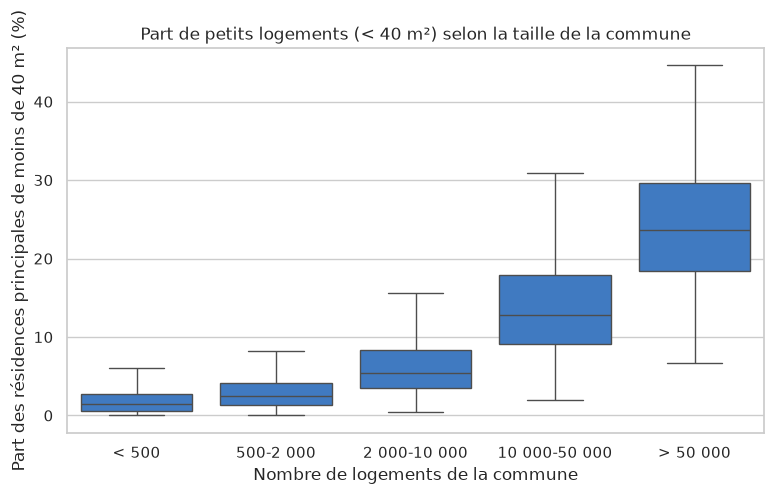

               count  mean  median
taille                            
< 500          22371   2.1     1.5
500-2 000       7488   3.2     2.4
2 000-10 000    2505   6.6     5.5
10 000-50 000    511  14.4    12.7
> 50 000          58  25.1    23.7
F_onewayResult(statistic=np.float64(3672.006923550634), pvalue=np.float64(0.0))
êta² : 0.308


In [18]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=com, x="taille", y="part_moins40m2", color=bleu, showfliers=False)
plt.title("Part de petits logements (< 40 m²) selon la taille de la commune")
plt.xlabel("Nombre de logements de la commune")
plt.ylabel("Part des résidences principales de moins de 40 m² (%)")
plt.show()

# Validation 1 : moyenne et médiane par tranche
print(com.groupby("taille", observed=True)["part_moins40m2"].agg(["count", "mean", "median"]).round(1))

# Validation 2 : ANOVA (5 groupes)
tranches = ["< 500", "500-2 000", "2 000-10 000", "10 000-50 000", "> 50 000"]
groupes = []
for t in tranches:
    groupes.append(com[com["taille"] == t]["part_moins40m2"])
print(stats.f_oneway(groupes[0], groupes[1], groupes[2], groupes[3], groupes[4]))

# Taille d'effet : êta² = part de la variance expliquée par la taille de la commune
moyenne = com["part_moins40m2"].mean()
entre = 0
for g in groupes:
    entre = entre + len(g) * (g.mean() - moyenne) ** 2
total = ((com["part_moins40m2"] - moyenne) ** 2).sum()
print("êta² :", round(entre / total, 3))

**Interprétation du graphique :** la part de petits logements (moins de 40 m²) augmente très nettement avec la taille de la commune. La médiane passe de 1,5 % dans les villages (moins de 500 logements) à 23,7 % dans les grandes villes (plus de 50 000) : une résidence principale sur quatre y est un studio ou un petit deux-pièces, contre presque aucune à la campagne. La dispersion augmente aussi : les communes moyennes sont plus hétérogènes (villes étudiantes contre villes résidentielles).

**Choix du test :** on compare la moyenne d'une variable quantitative entre 5 classes de taille de commune : c'est le cas de l'ANOVA. Avec 32 933 communes, la p-value sera forcément très faible ; l'êta² mesure l'ampleur de l'effet.

**Interprétation du test :** l'ANOVA est très significative (F = 3 672, p ≈ 0). L'êta² vaut 0,308 : la taille de la commune explique 31 % des différences de part de petits logements, un effet **fort** (au-delà du seuil de 0,14).

**Avis métier :** les petites surfaces se concentrent en ville, là où le prix au m² est le plus élevé (un studio se vend plus cher au m² qu'une maison). Ce sont aussi les biens les plus recherchés en location (étudiants, jeunes actifs). Cette variable aidera à corriger l'effet de composition : une ville avec beaucoup de studios aura mécaniquement un prix médian au m² plus élevé.

### B2.3 Mobilité résidentielle et marché locatif

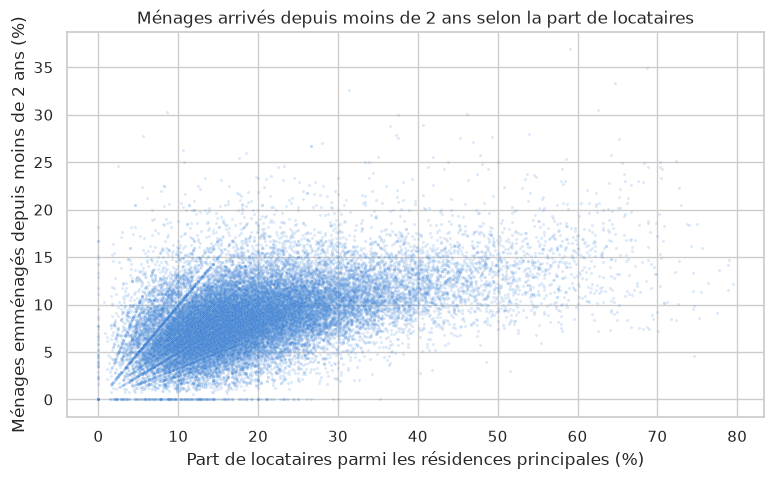

Pearson : PearsonRResult(statistic=np.float64(0.524813071728195), pvalue=np.float64(0.0))
Spearman : SignificanceResult(statistic=np.float64(0.5169055044010045), pvalue=np.float64(0.0))


In [19]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=com, x="part_locataires", y="part_emmenages_2ans", s=5, alpha=0.15, color=bleu)
plt.title("Ménages arrivés depuis moins de 2 ans selon la part de locataires")
plt.xlabel("Part de locataires parmi les résidences principales (%)")
plt.ylabel("Ménages emménagés depuis moins de 2 ans (%)")
plt.show()

# Validation : corrélations (le coefficient sert aussi de taille d'effet)
print("Pearson :", stats.pearsonr(com["part_locataires"], com["part_emmenages_2ans"]))
print("Spearman :", stats.spearmanr(com["part_locataires"], com["part_emmenages_2ans"]))

**Interprétation du graphique :** plus une commune compte de locataires, plus elle a de ménages arrivés récemment. Autour de 10 % de locataires, 5 à 10 % des ménages ont emménagé depuis moins de 2 ans ; au-delà de 40 % de locataires, on monte souvent à 15-20 %. Le nuage reste large : à part de locataires égale, la mobilité varie beaucoup. Les lignes diagonales et la rangée à 0 % en bas à gauche viennent des toutes petites communes, dont les effectifs (quelques ménages) ne prennent que quelques valeurs possibles.

**Choix du test :** deux variables quantitatives continues : on mesure leur lien avec Pearson (relation linéaire) et Spearman (relation monotone, moins sensible aux valeurs extrêmes). Comparer les deux indique si la relation est linéaire. Le coefficient sert directement de taille d'effet.

**Interprétation du test :** Pearson (r = 0,52) et Spearman (ρ = 0,52) sont presque identiques : la relation est monotone et à peu près linéaire. Au-delà de 0,5, le lien est **fort**. Les p-values sont nulles, ce qui est attendu avec 32 933 communes.

**Avis métier :** le taux d'emménagements récents mesure le dynamisme du marché (rotation des occupants, liquidité). Pour un investisseur, une commune où les locataires changent souvent offre un marché locatif actif, mais aussi un risque de vacance entre deux locataires. Les deux variables étant fortement liées, il faudra probablement n'en garder qu'une dans le modèle.

### B2.4 Ménages sans voiture, communes denses ou non

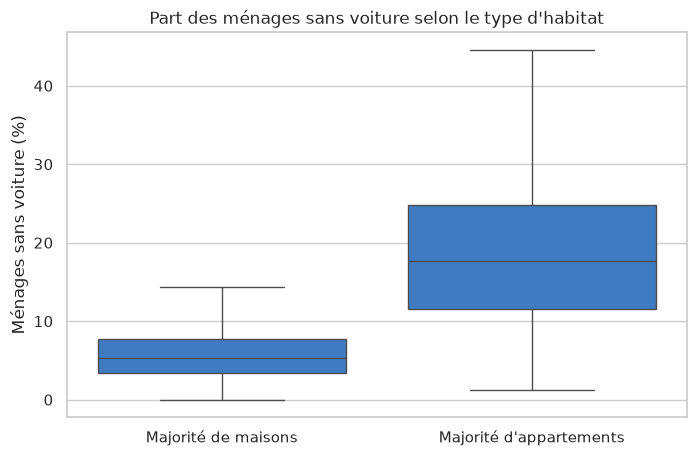

Communes : 1186 denses / 31747 pavillonnaires
Moyennes : 19.8 % / 6.2 %
TtestResult(statistic=np.float64(38.365164631820164), pvalue=np.float64(1.186450623987051e-210), df=np.float64(1196.9693424191735))
d de Cohen : 1.48


In [20]:
# Commune "dense" : majorité d'appartements
com["habitat"] = np.where(com["part_apparts"] > 50, "Majorité d'appartements", "Majorité de maisons")

plt.figure(figsize=(8, 5))
sns.boxplot(data=com, x="habitat", y="part_sans_voiture", color=bleu, showfliers=False)
plt.title("Part des ménages sans voiture selon le type d'habitat")
plt.xlabel("")
plt.ylabel("Ménages sans voiture (%)")
plt.show()

# Validation : test t de Welch (2 groupes) + taille d'effet (d de Cohen)
dense = com[com["habitat"] == "Majorité d'appartements"]["part_sans_voiture"]
pavillon = com[com["habitat"] == "Majorité de maisons"]["part_sans_voiture"]
print("Communes :", len(dense), "denses /", len(pavillon), "pavillonnaires")
print("Moyennes :", round(dense.mean(), 1), "% /", round(pavillon.mean(), 1), "%")
print(stats.ttest_ind(dense, pavillon, equal_var=False))
ecart_type = np.sqrt((dense.var() + pavillon.var()) / 2)
print("d de Cohen :", round((dense.mean() - pavillon.mean()) / ecart_type, 2))

**Interprétation du graphique :** dans les communes à majorité d'appartements, un ménage sur cinq en moyenne n'a pas de voiture (19,8 %), contre 6,2 % dans les communes à majorité de maisons. Les deux boîtes ne se chevauchent presque pas. Les communes denses ne sont que 1 186 sur 32 933, mais elles regroupent une grande partie de la population.

**Choix du test :** on compare la moyenne d'une variable quantitative entre deux groupes de tailles et de variances très différentes (1 186 contre 31 747 communes) : c'est le cas du test t de Welch (`equal_var=False`). Le d de Cohen mesure l'ampleur de l'écart.

**Interprétation du test :** l'écart est très significatif (t = 38,4 ; p ≈ 10⁻²¹⁰) et surtout **très fort** : d = 1,48, bien au-delà du seuil de 0,8. C'est l'effet le plus net de cette EDA.

**Avis métier :** se passer de voiture n'est possible que là où les transports en commun et les services sont proches. La part de ménages sans voiture est donc une mesure indirecte de l'accessibilité, l'un des facteurs cités dans le sujet (« transports, services »), que le recensement fournit pour toute la France. On s'attend à ce qu'elle soit fortement liée au prix au m², à vérifier après la jointure avec DVF+.

### B2.5 Corrélations entre indicateurs

In [21]:
# Indicateurs calculés à l'IRIS (au moins 50 logements), sur la base brute du recensement
codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
l = pd.read_csv(DATA_RAW / "base-ic-logement-2022_csv" / "base-ic-logement-2022.CSV",
                sep=";", dtype=codes_texte)
l = l[l["P22_LOG"] >= 50].copy()
log_, rp = l["P22_LOG"], l["P22_RP"].replace(0, np.nan)
l["taux_vacance"] = l["P22_LOGVAC"] / log_ * 100
l["part_rsec"] = l["P22_RSECOCC"] / log_ * 100
l["part_maisons"] = l["P22_MAISON"] / log_ * 100
l["part_proprio"] = l["P22_RP_PROP"] / rp * 100
l["part_hlm"] = l["P22_RP_LOCHLMV"] / rp * 100
l["part_avant1946"] = (l["P22_RP_ACH1919"] + l["P22_RP_ACH1945"]) / rp * 100
print("IRIS étudiés :", len(l))

IRIS étudiés : 46801


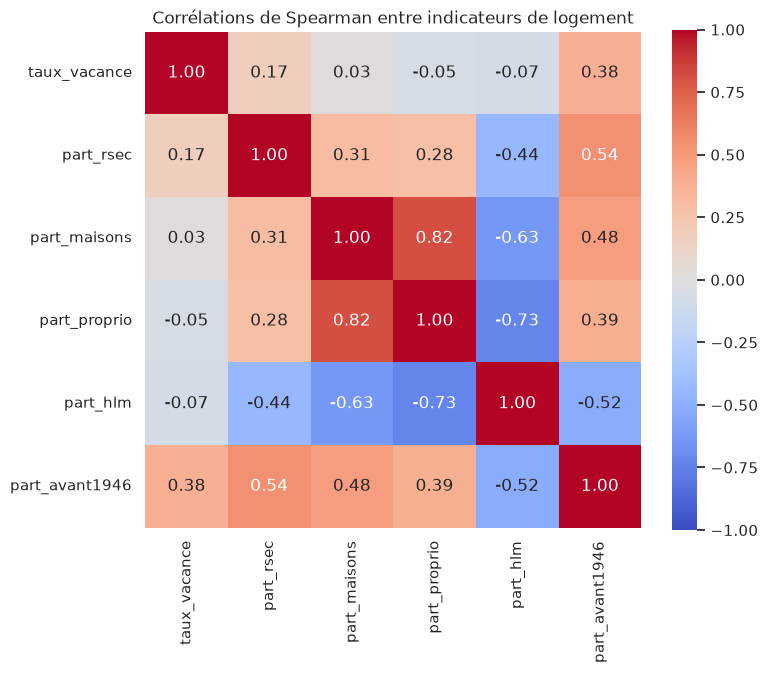

Maisons / propriétaires : SignificanceResult(statistic=np.float64(0.8150857829579694), pvalue=np.float64(0.0))
Propriétaires / HLM : SignificanceResult(statistic=np.float64(-0.7267348676046284), pvalue=np.float64(0.0))
Maisons / HLM : SignificanceResult(statistic=np.float64(-0.6348114607947348), pvalue=np.float64(0.0))


In [22]:
indicateurs = ["taux_vacance", "part_rsec", "part_maisons", "part_proprio", "part_hlm", "part_avant1946"]
correlations = l[indicateurs].corr(method="spearman")

plt.figure(figsize=(8, 6.5))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Corrélations de Spearman entre indicateurs de logement")
plt.show()

# Validation : test des corrélations les plus fortes
# nan_policy="omit" : ignore les IRIS sans résidence principale (parts vides)
print("Maisons / propriétaires :", stats.spearmanr(l["part_maisons"], l["part_proprio"], nan_policy="omit"))
print("Propriétaires / HLM :", stats.spearmanr(l["part_proprio"], l["part_hlm"], nan_policy="omit"))
print("Maisons / HLM :", stats.spearmanr(l["part_maisons"], l["part_hlm"], nan_policy="omit"))

**Interprétation du graphique :** un bloc de variables très liées se détache : part de maisons et de propriétaires (0,82), part de propriétaires et de HLM (-0,73), part de maisons et de HLM (-0,63). Ces trois variables décrivent le même axe : « pavillonnaire / propriétaires » contre « collectif / logement social ». La vacance, elle, est presque indépendante de ce bloc (moins de 0,1 en valeur absolue) : elle apporte une information nouvelle. Son lien le plus net est avec l'ancienneté du parc (0,38).

**Interprétation des tests :** toutes les corrélations testées sont significatives (p ≈ 0), ce qui est attendu avec 46 800 IRIS. Ce qui compte, c'est leur valeur : au-delà de 0,7, les variables sont redondantes.

**Avis métier :** pour la modélisation, ne garder qu'une variable du bloc maisons / propriétaires / HLM (la part de maisons, la plus simple à interpréter, ou la part de HLM pour le profil social). Conserver la vacance, les résidences secondaires et l'ancienneté du parc, qui apportent chacune une information différente.

In [23]:
orange = "#eb6834"
chemin_lovac = DATA_RAW / "lovac-open-data-2020-a-2026.xlsx"

# LOVAC, feuille communale : "s" (secret) -> valeur manquante, puis conversion en nombres
lovac = pd.read_excel(chemin_lovac, sheet_name="COM open data", dtype=str)
for col in lovac.columns:
    if col.startswith("pp_") or col.startswith("ff_"):
        lovac[col] = pd.to_numeric(lovac[col].replace("s", np.nan))

# Base logement 2022 (recensement), additionnée par commune (bloc 7) : sert de point de comparaison
rp = (pd.read_parquet(DATA_OUT / "logement_commune_2022.parquet",
                      columns=["code_commune", "P22_LOG", "P22_LOGVAC"])
        .rename(columns={"code_commune": "COM"}))

# Jointure par code commune (LOVAC : géographie 2026 ; recensement : géographie 2024)
compar = lovac.merge(rp, left_on="CODGEO_26", right_on="COM", how="inner")
print("Communes LOVAC :", len(lovac), "| recensement :", len(rp), "| communes communes aux deux :", len(compar))

Communes LOVAC : 34912 | recensement : 34955 | communes communes aux deux : 34884


### B2.6 LOVAC : évolution nationale et rupture de série

In [ ]:
# Feuille FR : totaux nationaux par millésime
fr = pd.read_excel(chemin_lovac, sheet_name="FR")
fr["annee_situation"] = fr["Millésime"] - 1          # millésime N = situation au 1er janvier N-1
fr = fr.sort_values("annee_situation")

plt.figure(figsize=(9, 5))
plt.plot(fr["annee_situation"], fr["pp_vacant"] / 1e6, marker="o", color=bleu, label="Logements vacants")
plt.plot(fr["annee_situation"], fr["pp_vacant_plus_2ans"] / 1e6, marker="o", color=orange, label="Vacants depuis plus de 2 ans")
plt.axvspan(2022.5, 2024.5, color="grey", alpha=0.15, label="Après la fin de la taxe d'habitation")
plt.title("Logements privés vacants en France (LOVAC)")
plt.xlabel("Situation au 1er janvier de l'année")
plt.ylabel("Nombre de logements (millions)")
plt.ylim(0, 4.5)
plt.legend()
plt.show()

# Validation 1 : les chiffres et le taux national (quand le parc est connu)
fr["taux_%"] = (fr["pp_vacant"] / fr["ff_pp_total"] * 100).round(1)
print(fr[["Millésime", "annee_situation", "pp_vacant", "pp_vacant_plus_2ans", "taux_%"]])

# Validation 2 : le classement des communes est-il stable d'une année à l'autre ?
# Corrélation de Spearman entre les taux de vacance de deux millésimes consécutifs
for a, b in [("20", "21"), ("21", "22"), ("22", "23"), ("23", "24"), ("24", "25")]:
    ta = lovac["pp_vacant_" + a] / lovac["ff_pp_total_" + a]
    tb = lovac["pp_vacant_" + b] / lovac["ff_pp_total_" + b]
    ok = ta.notna() & tb.notna()
    print("Millésimes 20" + a, "-> 20" + b, ": Spearman =", round(stats.spearmanr(ta[ok], tb[ok])[0], 3))

**Interprétation du graphique :** de 2019 à 2023, le nombre de logements privés vacants est stable, autour de 3,6-3,7 millions (taux national d'environ 11 %). En 2024, il chute brutalement à 2,38 millions (7,2 %), puis remonte à 3,16 millions en 2025. Une baisse d'un tiers en un an, suivie d'une remontée, ne correspond à aucune évolution réelle du marché : c'est l'effet du changement de collecte après la fin de la taxe d'habitation (dispositif GMBI). La vacance de plus de 2 ans reste stable (1,1 à 1,35 million) : elle est moins touchée par la rupture.

**Choix de la validation :** une rupture de collecte peut fausser les **niveaux** sans fausser la **position relative** des communes. On mesure la stabilité du classement des communes entre deux millésimes consécutifs avec la corrélation de Spearman (fondée sur les rangs).

**Interprétation du test :** le classement est très stable avant la rupture (Spearman de 0,91 à 0,92 entre millésimes successifs) et reste élevé après (0,87). Les communes très vacantes restent très vacantes, même si le niveau national est faussé.

**Avis métier :** il ne faut pas utiliser LOVAC pour mesurer l'**évolution** de la vacance autour de 2023-2024. En revanche, il reste fiable pour **comparer les communes entre elles** une année donnée. Pour le modèle, il vaut mieux utiliser un indicateur relatif (rang ou écart à la moyenne nationale de l'année) qu'un niveau brut, et signaler les millésimes après rupture.

### B2.7 LOVAC : le secret statistique selon la taille de la commune

In [ ]:
compar["taille"] = pd.cut(compar["P22_LOG"], bins=[0, 100, 500, 2000, 10000, 2000000],
                          labels=["< 100", "100-500", "500-2 000", "2 000-10 000", "> 10 000"])
compar["parc_secret"] = compar["ff_pp_total_23"].isna()     # parc privé caché (millésime 2023)

part_secret = compar.groupby("taille", observed=True)["parc_secret"].mean() * 100

plt.figure(figsize=(9, 5))
sns.barplot(x=part_secret.index, y=part_secret.values, color=bleu)
plt.title("Part des communes dont le parc privé est caché (secret statistique, millésime 2023)")
plt.xlabel("Nombre de logements de la commune (recensement 2022)")
plt.ylabel("Communes sous secret (%)")
plt.show()

# Validation 1 : part de secret et part des logements couverts
print(part_secret.round(1))
couvert = compar[~compar["parc_secret"]]["P22_LOG"].sum() / compar["P22_LOG"].sum() * 100
print("Part des logements situés dans une commune au parc connu :", round(couvert, 1), "%")

# Validation 2 : khi-deux taille × secret + V de Cramér
contingence = pd.crosstab(compar["taille"], compar["parc_secret"])
khi2, p, ddl, attendu = stats.chi2_contingency(contingence)
v_cramer = np.sqrt(khi2 / (contingence.values.sum() * (min(contingence.shape) - 1)))
print("khi-deux :", round(khi2), "| p-value :", p, "| V de Cramér :", round(v_cramer, 2))

**Interprétation du graphique :** le secret statistique dépend presque entièrement de la taille de la commune. Le parc privé est caché pour 85 % des communes de moins de 100 logements et 68 % de celles de 100 à 500, contre 11 % de 500 à 2 000 et pratiquement aucune au-delà. Ce sont donc les villages qui disparaissent des données.

**Choix du test :** on croise deux variables qualitatives (classe de taille, secret oui ou non) : c'est le cas du khi-deux. Le V de Cramér mesure l'intensité du lien.

**Interprétation du test :** le khi-deux est très significatif (12 960, p ≈ 0) et le V de Cramér vaut **0,61** : un lien **fort**. Les valeurs manquantes ne sont donc pas réparties au hasard : supprimer les communes sous secret reviendrait à retirer une grande partie du monde rural.

**Avis métier :** en nombre de logements, la perte est limitée : les communes au parc connu regroupent 90,6 % des logements, donc l'essentiel des ventes. Pour ne pas abandonner les villages, on complète leur taux par celui de leur intercommunalité (EPCI), en signalant ces valeurs dans une colonne à part.

### B2.8 Vacance LOVAC et vacance du recensement

In [ ]:
# Millésime 2023 (situation au 1er janvier 2022), le plus proche du recensement 2022
compar["taux_lovac"] = compar["pp_vacant_23"] / compar["ff_pp_total_23"] * 100
compar["taux_recensement"] = compar["P22_LOGVAC"] / compar["P22_LOG"] * 100
k = compar.dropna(subset=["taux_lovac", "taux_recensement"])
k = k[k["P22_LOG"] >= 50]

plt.figure(figsize=(8, 6))
sns.scatterplot(data=k, x="taux_recensement", y="taux_lovac", s=5, alpha=0.2, color=bleu)
plt.plot([0, 40], [0, 40], color="black", linestyle="--", label="égalité")
plt.xlim(0, 40)
plt.ylim(0, 40)
plt.title("Taux de vacance par commune : LOVAC (2022) et recensement (2022)")
plt.xlabel("Taux de vacance, recensement (%)")
plt.ylabel("Taux de vacance du parc privé, LOVAC (%)")
plt.legend()
plt.show()

# Validation : niveaux, puis corrélations
print("Communes comparées :", len(k))
print("Médianes : recensement", round(k["taux_recensement"].median(), 1), "% | LOVAC", round(k["taux_lovac"].median(), 1), "%")
print("Part des communes où LOVAC > recensement :", round((k["taux_lovac"] > k["taux_recensement"]).mean() * 100, 1), "%")
print("Pearson :", stats.pearsonr(k["taux_recensement"], k["taux_lovac"]))
print("Spearman :", stats.spearmanr(k["taux_recensement"], k["taux_lovac"]))

**Interprétation du graphique :** les deux mesures vont dans le même sens : les communes très vacantes selon le recensement le sont aussi selon LOVAC. Mais la plupart des points sont **au-dessus de la diagonale** : LOVAC donne une vacance plus élevée dans 74,6 % des 15 105 communes comparées (médiane de 9,9 % contre 7,5 %). Le nuage est large : pour un même taux au recensement, LOVAC varie beaucoup.

**Choix du test :** deux variables quantitatives continues : Pearson (lien linéaire) et Spearman (lien monotone, moins sensible aux valeurs extrêmes comme celles de la Guyane). Le coefficient sert de taille d'effet.

**Interprétation du test :** Pearson (r = 0,53) et Spearman (ρ = 0,59) indiquent un lien **fort** (au-delà de 0,5), mais loin d'une identité. Spearman est un peu plus élevé : les valeurs extrêmes affaiblissent le lien linéaire.

**Avis métier :** les deux sources mesurent la même réalité avec des méthodes différentes : vacance observée par l'enquêteur contre vacance fiscale, tout le parc contre parc privé. Elles ne sont pas redondantes au point d'en écarter une d'office : LOVAC apporte la dimension annuelle et la vacance longue. Leur corrélation reste assez élevée pour qu'il faille vérifier, lors de la modélisation, qu'elles ne se font pas concurrence (importance des variables).

## B3. Délinquance enregistrée (SSMSI)

**Contributeurs :** Cécile NAUDET · **Date :** 17/10/2026

**Objectif :** comprendre comment les indicateurs de délinquance se rapprochent ou se distinguent les uns des autres, puis étudier leur lien avec le prix au m², et surtout avec son évolution.

| Élément | Choix |
|---|---|
| Source | Délinquance enregistrée par la police et la gendarmerie (SSMSI), base communale. Voir la fiche d'audit. |
| Maille | Une ligne = un bassin de vie × une année. Paris, Lyon et Marseille en ville entière (option A), en attendant la décision de l'équipe sur les grandes villes. |
| Période | 2016-2024. 2025 est l'année de test : elle est exclue. |
| Cible | Prix médian au m² par bassin de vie et par année, recalculé à partir des ventes DVF+ (C5.0). |
| Clé de rapprochement | `maille` + `annee`. |
| Indicateurs | 15 taux pour 1 000 habitants (pour 1 000 logements pour les cambriolages). Les communes masquées sont complétées par la moyenne départementale des communes masquées. |
| Points d'attention | Délinquance enregistrée et non délinquance réelle ; indicateurs sur les stupéfiants liés à l'activité des services ; chiffres d'une année arrêtés en avril de l'année suivante. |

### Délinquance au bassin de vie

Taux recalculés par bassin de vie et par année : somme des faits divisée par la somme des habitants (des logements pour les cambriolages). Les communes masquées reçoivent la moyenne départementale des communes masquées (`complement_info_nombre`).

On part de la base communale brute (format long : une ligne par commune, année et indicateur) plutôt que du fichier du bloc 8, car les familles d'indicateurs (B3.1) se construisent à partir des libellés des indicateurs.

Paris, Lyon et Marseille : ville entière (option A) ou arrondissements séparés (option B), selon `DECOUPER_GRANDES_VILLES`. La cible au bassin de vie (C5.0) suit la même option.

In [ ]:
# Base communale brute
delinq = pd.read_parquet(DATA_RAW / "dataset_delinquance_communale.parquet")

# Table de liaison commune -> bassin de vie (bloc 1 de la préparation)
liaison = pd.read_parquet(DATA_OUT / "liaison_commune_bv2022.parquet")
liaison_ini = liaison[["CODGEO_INI", "BV2022"]]   # une ligne par code commune d'origine

# Maille : bassin de vie (option A) ou arrondissements séparés pour Paris, Lyon, Marseille (option B)
DECOUPER_GRANDES_VILLES = False

In [ ]:
# 1. Correspondance code 2026 -> bassin de vie
liaison_2026 = liaison[["CODGEO_2026", "BV2022"]].drop_duplicates()

# 2. Paris, Lyon, Marseille : un seul niveau, selon l'option choisie pour la cible
arrondissement = delinq["CODGEO_2026"].str.match(r"^(751|6938|132)")
ville_entiere = delinq["CODGEO_2026"].isin(["75056", "69123", "13055"])
if DECOUPER_GRANDES_VILLES:
    d = delinq[~ville_entiere]    # option B : on garde les arrondissements
else:
    d = delinq[~arrondissement]   # option A : on garde la ville entière

# 3. Rattachement au bassin de vie, et maille identique à celle de la cible
d = d.merge(liaison_2026, on="CODGEO_2026", how="left", validate="many_to_one")
d["maille"] = d["BV2022"]
if DECOUPER_GRANDES_VILLES:
    a = d["CODGEO_2026"].str.match(r"^(751|6938|132)")
    d.loc[a, "maille"] = d.loc[a, "CODGEO_2026"]

# 4. Communes masquées : moyenne départementale ; dénominateur : logements pour les cambriolages
d["nombre_estime"] = d["nombre"].fillna(d["complement_info_nombre"])
d["denominateur"] = np.where(d["indicateur"] == "Cambriolages de logement", d["insee_log"], d["insee_pop"])

# 5. Somme des faits et des habitants par maille × année × indicateur, puis taux
delinq_bv = (d.groupby(["maille", "annee", "indicateur"], observed=True)[["nombre_estime", "denominateur"]]
              .sum().reset_index())
delinq_bv["taux"] = delinq_bv["nombre_estime"] / delinq_bv["denominateur"] * 1000

# 6. Format large : une ligne par maille × année, une colonne par indicateur
delinq_bv["indicateur"] = delinq_bv["indicateur"].astype(str)   # évite les colonnes vides des 3 indicateurs départementaux
taux_bv = delinq_bv.pivot(index=["maille", "annee"], columns="indicateur", values="taux").reset_index()

print(taux_bv.shape)
print("Mailles :", taux_bv["maille"].nunique())

In [ ]:
# 2025 est l'année de test : on la retire dès maintenant de toute l'EDA
taux_bv = taux_bv[taux_bv["annee"] <= 2024]
print(taux_bv.shape)

In [ ]:
import geopandas as gpd

# Contours des bassins de vie : contours des communes, fusionnés par bassin
url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/communes-version-simplifiee.geojson"
communes = gpd.read_file(url)
communes = communes.merge(liaison_ini, left_on="code", right_on="CODGEO_INI", how="left")
carte_bv = communes.dissolve(by="BV2022").reset_index()[["BV2022", "geometry"]]

# Taux lissés d'une période : somme des faits / somme des habitants, au niveau demandé
def taux_periode(df, debut, fin, cles):
    t = df[df["annee"].between(debut, fin)].groupby(cles)[["nombre_estime", "denominateur"]].sum()
    return t["nombre_estime"] / t["denominateur"] * 1000

### B3.1 Redondances entre indicateurs

**Variables :** les 15 taux de délinquance par bassin de vie.

**Pourquoi regarder cela :** plusieurs indicateurs risquent de porter la même information (par exemple, l'usage de stupéfiants et sa partie sanctionnée par amende, ou les trois types de vols liés aux véhicules). Repérer ces redondances permet de garder un seul indicateur par groupe pour la suite.

**Méthode :** matrice des corrélations de Spearman entre les 15 taux, sur tous les bassins de vie et toutes les années 2016-2024. On utilise Spearman plutôt que Pearson parce que les distributions sont asymétriques, avec quelques valeurs extrêmes (fiche d'audit, section 7).

In [ ]:
indicateurs = [c for c in taux_bv.columns if c not in ["maille", "annee"]]

corr = taux_bv[indicateurs].corr(method="spearman")

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".1f", annot_kws={"size": 8})
plt.title(f"Corrélations de Spearman entre les taux de délinquance (n = {len(taux_bv):,} bassins × années)")
plt.tight_layout()
plt.show()

**Constat :** aucun couple d'indicateurs n'est lié à |rho| ≥ 0,9 : les 15 taux portent des informations assez distinctes. Trois groupes apparaissent avec des liens moyens à forts (rho de 0,4 à 0,7) :
- **délinquance de voie publique** : destructions et dégradations, vols sans violence contre des personnes, vols dans les véhicules, violences physiques hors cadre familial, vols violents sans arme (rho jusqu'à 0,7 entre destructions et vols sans violence) ;
- **vols liés aux véhicules** : vols de véhicule, vols dans les véhicules, vols d'accessoires (rho de 0,5 à 0,6), dont se rapprochent un peu les cambriolages (0,4 à 0,5) ;
- **violences intrafamiliales, violences sexuelles, escroqueries et usage de stupéfiants (AFD)** (rho de 0,5 à 0,7).

**Méthode :** les 15 indicateurs sont regroupés en 8 familles. On n'additionne que des indicateurs de même nature et de même unité de compte. Pour chaque famille, les faits sont additionnés puis rapportés à la population (aux logements pour les cambriolages).

| Famille | Indicateurs | Unité de compte |
|---|---|---|
| Cambriolages | Cambriolages de logement | Infraction (pour 1 000 logements) |
| Vols liés aux véhicules | Vols de véhicule, vols dans les véhicules, vols d'accessoires sur véhicules | Véhicule |
| Vols violents | Vols avec armes, vols violents sans arme | Infraction |
| Vols sans violence | Vols sans violence contre des personnes | Victime entendue |
| Violences | Violences physiques intrafamiliales, violences physiques hors cadre familial, violences sexuelles | Victime |
| Stupéfiants | Trafic de stupéfiants, usage de stupéfiants | Mis en cause |
| Escroqueries | Escroqueries et fraudes aux moyens de paiement | Victime |
| Destructions et dégradations | Destructions et dégradations volontaires | Infraction |

L'usage de stupéfiants (AFD) n'est pas ajouté : il fait déjà partie de l'usage de stupéfiants.

In [ ]:
# Correspondance indicateur -> famille (AFD exclu : déjà compris dans l'usage de stupéfiants)
familles = {
    "Cambriolages de logement": "Cambriolages",
    "Vols de véhicule": "Vols liés aux véhicules",
    "Vols dans les véhicules": "Vols liés aux véhicules",
    "Vols d'accessoires sur véhicules": "Vols liés aux véhicules",
    "Vols avec armes": "Vols violents",
    "Vols violents sans arme": "Vols violents",
    "Vols sans violence contre des personnes": "Vols sans violence",
    "Violences physiques intrafamiliales": "Violences",
    "Violences physiques hors cadre familial": "Violences",
    "Violences sexuelles": "Violences",
    "Trafic de stupéfiants": "Stupéfiants",
    "Usage de stupéfiants": "Stupéfiants",
    "Escroqueries et fraudes aux moyens de paiement": "Escroqueries",
    "Destructions et dégradations volontaires": "Destructions et dégradations",
}

fam = delinq_bv[(delinq_bv["annee"] <= 2024) & delinq_bv["indicateur"].isin(familles)].copy()
fam["famille"] = fam["indicateur"].map(familles)

# Faits additionnés dans chaque famille ; population (ou logements) comptée une seule fois
fam = (fam.groupby(["maille", "annee", "famille"])
          .agg(nombre_estime=("nombre_estime", "sum"), denominateur=("denominateur", "first"))
          .reset_index())
fam["taux"] = fam["nombre_estime"] / fam["denominateur"] * 1000

# Format large : une ligne par bassin × année, une colonne par famille
taux_fam = fam.pivot(index=["maille", "annee"], columns="famille", values="taux").reset_index()
liste_familles = ["Cambriolages", "Vols liés aux véhicules", "Vols violents", "Vols sans violence",
                  "Violences", "Stupéfiants", "Escroqueries", "Destructions et dégradations"]

print(taux_fam.shape)

In [ ]:
# Une ligne par bassin : taux lissés sur 2021-2024, DOM exclus
l21 = taux_periode(fam, 2021, 2024, ["maille", "famille"]).unstack("famille").reset_index()
l21_metro = l21[l21["maille"].str[:2] != "97"]

corr_fam = l21_metro[liste_familles].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(corr_fam, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 9})
plt.title(f"Corrélations de Spearman entre familles d'indicateurs (n = {len(l21_metro):,} bassins, 2021-2024)")
plt.tight_layout()
plt.show()

**Constat :**
- Aucun couple de familles n'est lié à |rho| ≥ 0,9 : le lien le plus fort est 0,77 (vols sans violence et destructions et dégradations). Les huit familles portent des informations distinctes.
- Quatre familles forment un groupe lié entre 0,5 et 0,77 : vols sans violence, destructions et dégradations, violences, stupéfiants.
- Les cambriolages sont la famille la plus à part (rho de 0,11 à 0,56). Leur lien le plus fort est avec les vols liés aux véhicules (0,56).
- Le lien entre violences et escroqueries n'est plus que de 0,33, contre 0,6 entre violences intrafamiliales et escroqueries dans la première matrice, qui mélangeait les années.

**Interprétation :**
- Le groupe vols sans violence, destructions, violences et stupéfiants correspond à une délinquance plus fréquente dans les mêmes bassins, probablement les plus urbains (effet « ville »).
- Les cambriolages ne suivent pas cette géographie : ils apportent une information propre, ce qui en fait la famille la plus intéressante pour le logement.
- La baisse du lien entre violences et escroqueries confirme l'hypothèse de la première matrice : ce lien venait surtout de leur hausse commune dans le temps (B3.3), pas du fait qu'elles touchent les mêmes bassins.

**Biais / limites :** les familles ont été construites sur la nature des faits et l'unité de compte, pas sur leurs corrélations. Les indicateurs d'une même famille ne se ressemblent pas toujours : le trafic et l'usage de stupéfiants (rho = 0,4 dans la première matrice), ou les vols avec et sans arme (0,3), touchent en partie des bassins différents. Le regroupement gagne en stabilité, mais il peut masquer ces différences.

### B3.2 Répartition sur le territoire

**Pourquoi regarder cela :** un indicateur presque identique partout ne peut pas expliquer des différences de prix entre bassins de vie. Regrouper les indicateurs proches donne plus de faits par bassin, donc des taux plus stables.

**Méthode :** Carte des taux de 2024 par bassin de vie, avec la même échelle de couleurs pour toutes les familles.

In [ ]:
# Taux lissés sur 2021-2024 : somme des faits sur 4 ans / somme des habitants sur 4 ans
l21 = (fam[fam["annee"].between(2021, 2024)]
       .groupby(["maille", "famille"])[["nombre_estime", "denominateur"]].sum())
l21["taux"] = l21["nombre_estime"] / l21["denominateur"] * 1000
l21 = l21.reset_index().pivot(index="maille", columns="famille", values="taux").reset_index()

carte_fam = carte_bv.merge(l21, left_on="BV2022", right_on="maille", how="left")

fig, axes = plt.subplots(2, 4, figsize=(26, 13))
for ax, f in zip(axes.flatten(), liste_familles):
    carte_fam.plot(column=f, cmap="Reds", vmin=0, vmax=12, legend=True, linewidth=0,
                   missing_kwds={"color": "lightgrey"}, ax=ax,
                   legend_kwds={"label": "Taux pour 1 000", "shrink": 0.6})
    ax.set_title(f, fontsize=12)
    ax.set_axis_off()
fig.suptitle("Taux par famille d'indicateurs et par bassin de vie, lissés sur 2021-2024 (même échelle)", fontsize=14)
plt.tight_layout()
plt.show()

**Constat :**
- **Familles qui varient nettement selon le territoire :**
  - **cambriolages** : plus élevés dans le Nord-Est, autour de Paris, dans la vallée du Rhône et autour de Bordeaux, Toulouse et Marseille ; bas dans le Massif central, les Alpes et la Corse ;
  - **vols liés aux véhicules** : élevés dans les grandes agglomérations (Paris, Lyon, Bordeaux, Lille) et sur le littoral méditerranéen ; bas dans le Massif central et l'Ouest ;
  - **stupéfiants** : faibles presque partout, élevés dans quelques grandes villes (Marseille, Paris, Lyon, Lille) ;
  - **violences** : élevées dans le Nord (Hauts-de-France) et sur le pourtour méditerranéen. Réunis, les trois indicateurs de violences forment une géographie plus nette que séparément.
- **Familles élevées presque partout :** destructions et dégradations (plus encore sur le pourtour méditerranéen, dans le Nord-Est et en Corse) et vols sans violence (plus élevés dans les grandes villes, les stations des Alpes et sur le littoral).
- **Famille la plus homogène :** escroqueries, avec des couleurs proches sur tout le territoire.
- **Vols violents** : les taux sont trop bas pour être visibles sur cette échelle (autour de 0,2 pour 1 000).
- La carte lissée sur 2021-2024 est très proche de celle de la seule année 2024 : la géographie de chaque famille est stable.

**Interprétation :** regrouper les indicateurs fait mieux apparaître la géographie des familles peu fréquentes prises une à une, comme les violences ou les vols liés aux véhicules. Plusieurs familles (vols liés aux véhicules, stupéfiants, vols sans violence) sont surtout élevées dans les grandes agglomérations, ce qui rappelle le risque de confusion avec l'effet « ville ».

**Biais / limites :**
- Taux lissés sur 2021-2024. Les cambriolages sont comptés pour 1 000 logements, les autres familles pour 1 000 habitants.
- Effet du nombre : une famille qui additionne plusieurs indicateurs a mécaniquement un taux plus élevé qu'un indicateur seul. Sur une échelle commune, elle paraît donc plus foncée (c'est le cas des violences) : on ne peut pas comparer les niveaux d'une famille à l'autre, seulement la géographie de chacune.
- Dans une famille, l'indicateur le plus fréquent pèse le plus : les violences suivent surtout les violences intrafamiliales, les stupéfiants surtout l'usage.

**Question :** certains indicateurs sont-ils homogènes sur le territoire ? Un indicateur presque identique partout ne peut pas expliquer des différences de prix entre bassins de vie.

In [ ]:
# Taux lissés sur 2021-2024 par famille
lisse_fam = (fam[fam["annee"].between(2021, 2024)]
             .groupby(["maille", "famille"])[["nombre_estime", "denominateur"]].sum())
lisse_fam["taux"] = lisse_fam["nombre_estime"] / lisse_fam["denominateur"] * 1000
lisse_fam = lisse_fam.reset_index().pivot(index="maille", columns="famille", values="taux").reset_index()

lisse_fam["dep"] = lisse_fam["maille"].str[:2]   # département du bassin (celui de sa commune pôle)
lisse_fam = lisse_fam[lisse_fam["dep"] != "97"]  # DOM hors périmètre

lignes = []
for f in liste_familles:
    x = lisse_fam[f].dropna()
    d1, med, d9 = x.quantile([0.1, 0.5, 0.9])
    groupes = [g[f].dropna().values for _, g in lisse_fam.groupby("dep")]
    H, p, eta2 = eta2_kruskal(groupes)
    lignes.append({"famille": f, "D1": round(d1, 2), "médiane": round(med, 2), "D9": round(d9, 2),
                   "D9 / D1": round(d9 / d1, 1) if d1 > 0 else np.nan,
                   "p-value": f"{p:.1e}", "η² département": round(eta2, 3)})

display(pd.DataFrame(lignes).set_index("famille").sort_values("η² département", ascending=False))

**Méthode :** taux lissés sur 2021-2024 (somme des faits sur quatre ans divisée par la somme des habitants), pour limiter l'effet des petits bassins où quelques faits suffisent à faire varier le taux. La période couvre les quatre dernières années hors test ; 2021 est aussi la première année complète des amendes forfaitaires pour usage de stupéfiants. Chaque valeur du tableau est calculée sur les taux des quelque 1 600 bassins de vie de métropole.

**Comment lire le tableau (exemple des cambriolages) :**
- **D1 = 2,21** : 10 % des bassins ont moins de 2,21 cambriolages pour 1 000 logements. Ce sont les bassins les moins touchés.
- **Médiane = 4,41** : la moitié des bassins a moins de 4,41 cambriolages pour 1 000 logements, l'autre moitié plus.
- **D9 = 7,14** : 10 % des bassins ont plus de 7,14 cambriolages pour 1 000 logements. Ce sont les bassins les plus touchés.
- **D9 / D1 = 3,2** : les bassins les plus touchés ont un taux 3,2 fois plus élevé que les moins touchés. Ce rapport mesure **à quel point les bassins sont différents entre eux**. S'il valait 1, tous les bassins auraient le même taux : la famille serait homogène sur le territoire.
- **η² département = 0,42** : 42 % des écarts entre bassins s'expliquent par le département où ils se trouvent. Les 58 % restants viennent de différences entre bassins **d'un même département**. Le η² mesure donc **si les écarts suivent une géographie régionale**. Repères : 0,01 faible, 0,06 moyen, 0,14 fort.
- **p-value** : avec plus de 1 600 bassins, elle est toujours très faible, même pour un écart minime. Ce n'est pas elle qu'on interprète, mais la taille des écarts (D9 / D1) et le η².

**Résultat :**
- **Aucune famille n'est homogène sur le territoire** : le rapport D9 / D1 va de 1,7 à 6,3, et le η² dépasse 0,14 pour les huit familles (effet fort du département).
- **Les vols liés aux véhicules** sont la famille la plus liée à la géographie (η² = 0,49 ; D9 / D1 = 3,7), devant les **cambriolages** (η² = 0,42 ; D9 / D1 = 3,2).
- **Les vols violents** ont des écarts forts entre bassins (D9 / D1 = 6,3), mais restent très rares (médiane de 0,17 pour 1 000) : leurs résultats reposent sur peu de faits.
- **Les stupéfiants** ont aussi de forts écarts (D9 / D1 = 5,3), qui reflètent en partie l'activité des services de police.
- **Les escroqueries** ont les écarts les plus faibles (D9 / D1 = 1,7), mais organisés régionalement (η² = 0,26).
- **Les violences** sont la famille la moins liée à la géographie (η² = 0,18 ; D9 / D1 = 2,3).
- Les résultats sont presque identiques avec un lissage sur 2020-2024 : ils ne dépendent pas de la période choisie.

**Interprétation :** la délinquance enregistrée varie entre bassins de vie pour toutes les familles. Elle est d'autant plus liée à la géographie qu'elle porte sur des biens (véhicules, logements) ; les atteintes aux personnes le sont moins. La carte des violences, très foncée, donnait une impression trompeuse : son taux est élevé parce qu'elle additionne trois indicateurs (effet du nombre), mais ses écarts entre bassins restent modérés. Pour la plupart des familles, la plus grande partie des écarts se joue entre bassins d'un même département, ce qui justifie de travailler au bassin de vie plutôt qu'au département. Les cambriolages, la famille la plus directement liée au logement, font partie des plus variables et des plus territorialisées.

**Biais / limites :**
- Le département d'un bassin est celui de sa commune pôle ; le η² mesure aussi en partie la composition des départements (plus ou moins urbains).
- Dans une famille, l'indicateur le plus fréquent pèse le plus : les violences suivent surtout les violences intrafamiliales, les stupéfiants surtout l'usage.
- Pour les stupéfiants, un même mis en cause peut être compté dans deux communes : l'addition par bassin peut légèrement surestimer le nombre de personnes.

### B3.3 Évolution dans le temps

**Pourquoi regarder cela :** le projet porte sur l'évolution des prix. Si la délinquance d'un bassin change peu dans le temps, ou si tous les bassins évoluent de la même façon, elle pourra expliquer les écarts de prix entre bassins, mais difficilement leur évolution.

**Méthode :** en deux temps.
1. **Tendance nationale :** pour chaque famille et chaque année, somme des faits de tous les bassins de métropole divisée par la somme des habitants (des logements pour les cambriolages). Un graphique par famille, avec un axe qui part de 0 pour ne pas exagérer les variations.
2. **Écart de chaque bassin à cette tendance :** évolution du taux du bassin entre 2016-2018 et 2022-2024 (moyennes sur trois ans), moins l'évolution nationale.

In [ ]:
# Bassins de métropole (DOM hors périmètre) ; fam s'arrête déjà en 2024
fam_metro = fam[fam["maille"].str[:2] != "97"]

nat_fam = fam_metro.groupby(["famille", "annee"])[["nombre_estime", "denominateur"]].sum()
nat_fam["taux"] = nat_fam["nombre_estime"] / nat_fam["denominateur"] * 1000
nat_fam = nat_fam.reset_index()

fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharex=True)
for ax, f in zip(axes.flatten(), liste_familles):
    g = nat_fam[nat_fam["famille"] == f]
    ax.plot(g["annee"], g["taux"], marker="o")
    ax.set_title(f, fontsize=11)
    ax.set_ylim(bottom=0)
fig.suptitle("Taux national par famille d'indicateurs, pour 1 000 habitants (logements pour les cambriolages), 2016-2024")
plt.tight_layout()
plt.show()

**Constat :** les familles n'évoluent pas toutes de la même façon entre 2016 et 2024.
- **Hausse continue** : violences, escroqueries, stupéfiants, avec une forte hausse à partir de 2021.
- **Baisse** : vols violents, cambriolages, vols liés aux véhicules, vols sans violence, destructions et dégradations.
- **Une chute en 2020 pour la plupart des familles** : cambriolages, vols liés aux véhicules, vols sans violence, stupéfiants, destructions et dégradations. Les vols liés aux véhicules et les stupéfiants remontent ensuite nettement ; les cambriolages en partie seulement. Les violences, elles, ne baissent pas en 2020 : elles restent au niveau de 2019, puis repartent à la hausse.

**Interprétation :** l'évolution d'une famille ne reflète pas seulement celle de la délinquance. Plusieurs facteurs se mêlent (hypothèses, non vérifiées avec nos données) :
- **Les événements** : la chute de 2020 correspond aux confinements liés à la crise sanitaire (moins de déplacements, plus de présence au domicile, donc moins de vols et de cambriolages). Les dégradations liées au mouvement des gilets jaunes (2018-2019) ne se voient pas dans le taux national : concentrées dans quelques villes, elles pèsent peu face à plus de 500 000 faits par an.
- **La société et le dépôt de plainte** : les victimes de violences sexuelles et intrafamiliales portent plus souvent plainte depuis le mouvement #MeToo (fin 2017) et le Grenelle des violences conjugales (2019). La hausse des violences vient en partie de cette libération de la parole.
- **Les priorités de l'État et des forces de l'ordre** : les stupéfiants comptent des personnes mises en cause, donc ils suivent l'activité des services. La hausse à partir de 2021 suit la création des amendes forfaitaires (fin 2020) et les priorités données à la lutte contre les trafics.
- **La technologie** : les systèmes antivol des voitures rendent les vols de véhicule plus difficiles, ce qui peut expliquer en partie la baisse des vols liés aux véhicules avant 2020.

**Conséquence pour le projet :** ces facteurs agissent au niveau national, sur tous les bassins en même temps. Comme le taux des crédits, ils peuvent expliquer le moment du marché, mais pas les écarts entre bassins. Pour l'évolution des prix, ce qui comptera est la façon dont chaque bassin s'écarte de cette tendance nationale.

In [ ]:
# Évolution de chaque bassin entre 2016-2018 et 2022-2024 (%)
evol_fam = pd.DataFrame({"debut": taux_periode(fam_metro, 2016, 2018, ["maille", "famille"]),
                         "fin": taux_periode(fam_metro, 2022, 2024, ["maille", "famille"])}).reset_index()
evol_fam["evol_bv"] = (evol_fam["fin"] / evol_fam["debut"] - 1) * 100
evol_fam["evol_bv"] = evol_fam["evol_bv"].replace([np.inf, -np.inf], np.nan)   # aucun fait au départ : évolution impossible

# Évolution nationale de chaque famille (%)
evol_nat_fam = (taux_periode(fam_metro, 2022, 2024, "famille") / taux_periode(fam_metro, 2016, 2018, "famille") - 1) * 100
print("Évolution nationale (%) :\n", evol_nat_fam.round(1))

# Écart du bassin à la tendance nationale (points de %)
evol_fam["ecart"] = evol_fam["evol_bv"] - evol_fam["famille"].map(evol_nat_fam)
ecart_fam = evol_fam.pivot(index="maille", columns="famille", values="ecart").reset_index()
carte_ecart_fam = carte_bv.merge(ecart_fam, left_on="BV2022", right_on="maille", how="left")

fig, axes = plt.subplots(2, 4, figsize=(26, 13))
for ax, f in zip(axes.flatten(), liste_familles):
    carte_ecart_fam.plot(column=f, cmap="RdBu_r", vmin=-50, vmax=50, legend=True, linewidth=0,
                         missing_kwds={"color": "lightgrey"}, ax=ax,
                         legend_kwds={"label": "Écart à la tendance nationale (points de %)", "shrink": 0.6})
    ax.set_title(f"{f}\n(France : {evol_nat_fam[f]:+.0f} %)", fontsize=12)
    ax.set_axis_off()
fig.suptitle("Évolution 2016-2018 → 2022-2024 de chaque bassin, comparée à la France", fontsize=14)
plt.tight_layout()
plt.show()

**Constat :**
- **Cambriolages** (France : −15 %) : les écarts forment de grandes zones. Les cambriolages ont augmenté, dans l'Ouest (Bretagne, Normandie, Pays de la Loire) et une partie du Centre ; ils ont baissé plus vite dans le Sud-Est et en Corse.
- **Vols liés aux véhicules** (France : −9 %) : baisse plus forte que la moyenne dans une grande partie du Sud ; évolution plus défavorable dans des zones du Centre et du Nord-Est.
- **Vols sans violence** (−12 %) et **destructions et dégradations** (−15 %) : la plupart des bassins suivent la tendance nationale, avec des écarts faibles.
- **Vols violents** (−39 %) et **violences** (+54 %) : la majorité des bassins a évolué plus défavorablement que la France (en rouge).
- **Stupéfiants** (+35 %) : la majorité des bassins a évolué nettement en dessous de la tendance nationale (en bleu).
- **Escroqueries** (+55 %) : les écarts forment une mosaïque, sans organisation géographique.

**Interprétation :**
- Quand la plupart des bassins sont du même côté de la tendance nationale, cette tendance est portée par quelques grandes agglomérations, qui pèsent beaucoup dans le total national. Les vols violents ont surtout baissé, et les stupéfiants surtout augmenté, dans les grandes villes.
- Les cambriolages et les vols liés aux véhicules évoluent différemment selon les régions, avec des zones cohérentes. Ce sont les familles les plus susceptibles d'expliquer des écarts d'évolution des prix entre bassins.
- Pour les escroqueries, la mosaïque peut venir du hasard dans les petits bassins ou de pratiques locales de dépôt de plainte, plutôt que d'une vraie dynamique territoriale.

**Biais / limites :**
- La tendance nationale est dominée par les grandes agglomérations : elle ne décrit pas l'évolution d'un bassin typique. La médiane des évolutions des bassins serait une autre référence possible.
- L'écart est mesuré en points de pourcentage, avec la même échelle pour toutes les familles : pour une famille à forte tendance nationale (violences, escroqueries), un même écart représente une différence relative plus faible.
- Pour les vols violents, les faits sont rares : dans les petits bassins, l'évolution peut venir du hasard.

### B3.4 Stabilité des bassins dans le temps

**Variables :** les taux des 8 familles par bassin de vie et par année, 2016-2024.

**Pourquoi regarder cela :** si la délinquance d'un bassin est une caractéristique stable (un bassin très touché le reste), elle décrit surtout **quel** bassin, comme une réputation, et peu **quand**. Elle pourrait alors expliquer le niveau des prix, mais difficilement leur évolution.

**Méthode :** pour chaque famille :
1. **Nuage de points** du taux de chaque bassin en 2016-2018 (abscisse) et en 2022-2024 (ordonnée), en échelles logarithmiques, avec une diagonale qui marque « même taux au début et à la fin ».
2. **Les bassins gardent-ils leur rang ?** Corrélation de Spearman entre les taux lissés de 2016-2018 et ceux de 2022-2024. Proche de 1, les bassins les plus touchés au début le sont encore à la fin.
3. **D'où viennent les écarts ?** Part des écarts entre toutes les valeurs (bassin × année) qui vient des différences entre bassins, plutôt que de l'évolution dans le temps.

In [ ]:
debut = taux_periode(fam_metro, 2016, 2018, ["maille", "famille"]).unstack("famille")
fin = taux_periode(fam_metro, 2022, 2024, ["maille", "famille"]).unstack("famille")

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, f in zip(axes.flatten(), liste_familles):
    d = pd.concat([debut[f], fin[f]], axis=1, keys=["debut", "fin"]).dropna()
    d = d[(d["debut"] > 0) & (d["fin"] > 0)]          # échelle logarithmique : pas de taux nul
    ax.scatter(d["debut"], d["fin"], s=4, alpha=0.3)
    lim = [d.min().min(), d.max().max()]
    ax.plot(lim, lim, color="grey", linestyle="--", label="même taux")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f, fontsize=11)
    ax.set_xlabel("Taux 2016-2018 (pour 1 000)")
    ax.set_ylabel("Taux 2022-2024 (pour 1 000)")
axes[0, 0].legend()
fig.suptitle("Taux de chaque bassin au début et à la fin de la période (échelles logarithmiques)", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# Taux de métropole par bassin et par année (DOM hors périmètre)
tf = taux_fam[taux_fam["maille"].str[:2] != "97"]

lignes = []
for f in liste_familles:
    # 1. Les bassins gardent-ils leur rang ?
    d = pd.concat([debut[f], fin[f]], axis=1, keys=["debut", "fin"]).dropna()
    rho, p = stats.spearmanr(d["debut"], d["fin"])

    # 2. Part des écarts due aux différences entre bassins (plutôt qu'au temps)
    large = tf.pivot(index="maille", columns="annee", values=f).dropna()   # une ligne par bassin, une colonne par année
    total = large.stack().var()
    entre = large.mean(axis=1).var()

    lignes.append({"famille": f, "rho 2016-18 / 2022-24": round(rho, 2), "p-value": f"{p:.1e}",
                   "part entre bassins (%)": round(entre / total * 100, 1), "n bassins": len(d)})

display(pd.DataFrame(lignes).set_index("famille"))

**Constat :**
- **Graphiques :** pour les vols sans violence, les destructions et dégradations et les vols liés aux véhicules, les points forment une bande étroite le long de la diagonale : chaque bassin garde presque le même taux. Pour les vols violents, les escroqueries et les stupéfiants, le nuage est plus dispersé. Pour les violences et les escroqueries, le nuage est entièrement au-dessus de la diagonale : hausse dans presque tous les bassins.
- **Tableau :**

| Profil | Familles | rho début / fin | Part des écarts entre bassins |
|---|---|---|---|
| Caractéristique stable du bassin | Vols sans violence, vols liés aux véhicules, destructions et dégradations | 0,83 à 0,88 | 81 à 89 % |
| Plutôt stable, avec des bassins qui bougent | Cambriolages | 0,74 | 70 % |
| Rang instable, faits rares | Vols violents | 0,59 | 83 % |
| Tendance dans le temps importante | Violences, stupéfiants, escroqueries | 0,58 à 0,79 | 36 à 63 % |

Pour toutes les familles, la p-value est inférieure à 0,05 : les taux du début et de la fin sont liés.

**Interprétation :**
- **Vols sans violence, vols liés aux véhicules, destructions et dégradations** sont des caractéristiques stables des bassins : un bassin très touché le reste. Ils décrivent surtout **où** l'on est, comme une réputation. Ils pourront expliquer le niveau des prix, plus difficilement leur évolution, sauf si le niveau de délinquance est lié à des trajectoires de prix différentes (hypothèse testée en C5.3).
- **Les cambriolages** sont en grande partie stables, mais les bassins changent davantage de position : c'est cohérent avec les évolutions différentes selon les régions (Ouest, Sud-Est) vues sur les cartes d'écart. C'est la famille qui peut le mieux porter à la fois le « où » et le « quand ».
- **Pour les violences et surtout les escroqueries** (36 % seulement des écarts entre bassins), la hausse nationale domine : ces familles disent surtout **quand**, au niveau national (libération de la parole, fraude en ligne), plutôt que quel bassin.
- **Pour les vols violents**, le rang instable vient probablement du faible nombre de faits : dans un petit bassin, quelques faits suffisent à le faire changer de place.

**Biais / limites :** les bassins sans aucun fait sont retirés des graphiques (échelles logarithmiques), mais pris en compte dans le rho. Le rho compare deux périodes de trois ans, et non toutes les années.

## B4. Équipements

**Contributeurs :** Christian · **Date :** octobre 2026

Analyses des équipements de la Base permanente des équipements (BPE) : indicateurs de présence par commune pour les millésimes 2015 et 2020 (bloc 10 de la préparation), types d'équipements de la BPE 2025.

**En attente :** ces analyses s'appuient sur des scripts et des fichiers qui ne sont pas encore dans le dépôt ni sur le Drive. Elles seront intégrées ici dès leur réception, sur le même principe que le reste du notebook : le code dans les cellules, les données téléchargées par `00_telechargement`.

## B5. Annonces immobilières du Haut-Rhin (axe 2)

**Contributeurs :** Théophyle CHEVET · **Date :** octobre 2026

Échantillons d'annonces de vente et de location du Haut-Rhin (voir les audits 10 et 11). Les prix étudiés ici sont ceux des annonces, pas la cible DVF+.

### Préparation des données suite à la première inspection

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

annonces_ventes = pd.read_csv(DATA_RAW / "ech_annonces_ventes_68.csv", sep=";", encoding="utf-8-sig", index_col='idannonce')
location = pd.read_csv(DATA_RAW / "ech_annonces_locations_68.csv", sep=";", encoding="utf-8-sig",index_col="idannonce")

sns.set_theme(style="whitegrid")          # fond blanc avec une grille légère
couleurs = {"Appartement": "#2a78d6", "Maison": "#eb6834"}   # bleu / orange

# ── Préparation : on retire les valeurs aberrantes repérées dans les premieres inspections ─────
v = annonces_ventes[(annonces_ventes["surface"] >= 9)
           & (annonces_ventes["prix_bien"] >= 20000)
           & (annonces_ventes["prix_m2_vente"] >= 500)
           & (annonces_ventes["prix_m2_vente"] <= 8000)
           & (annonces_ventes["typedebien_lite"] != "l")
           & (annonces_ventes["typedetransaction"] == "v")].copy()

# Libellés lisibles pour les graphiques
v["type"] = v["typedebien_lite"].replace({"a": "Appartement", "m": "Maison"})
v["neuf"] = v["logement_neuf"].replace({"o": "Neuf", "n": "Ancien"})
v["annee"] = pd.to_datetime(v["date"]).dt.year

# Location : Haut-Rhin uniquement, sans loyers ni surfaces aberrants
l = location[(location["DEP"] == 68)
             & (location["prix_bien"] >= 150)
             & (location["surface"] >= 9)
             & (location["typedebien_lite"] != "l")].copy()
l["loyer_m2"] = l["prix_bien"] / l["surface"]      # loyer au m² (absent du fichier)

print("Ventes conservées :", len(v), "| Locations conservées :", len(l))

### B5.1 Distribution du prix des annonces

In [ ]:
plt.figure(figsize=(6, 3))  

sns.histplot(v["prix_bien"]/1000, bins=60) # on divise les valeurs par 1000 pour afficher en K€
plt.title("Distribution du prix des annonces (K€)")

plt.xlim(0, 1000)

plt.xlabel("Prix (K€)")   

plt.show()

# Validation : si la moyenne dépasse nettement la médiane, la distribution est asymétrique
print("Moyenne :", round(v["prix_bien"].mean()), "€ | Médiane :", v["prix_bien"].median(), "€")

**Interpretation du graphique**

La grande majorité des annonces se situe entre 100 et 400k euros. Le prix median des annonces est inférieur à la moyenne car les logements tres chers tirent cette-dernière vers le haut et on ne peut pas dire que ca suit une loi normale.

### B5.2 Prix au m² selon le type de bien et le neuf

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=v, x="type", y="prix_m2_vente", hue="neuf",
            showfliers=False)                        # showfliers=False : on masque les points extrêmes
plt.title("Prix au m² selon le type de bien et le neuf")
plt.xlabel("")
plt.ylabel("Prix au m² (€)")
plt.show()

# Validation : test t (compare deux moyennes), pour les appartements puis les maisons
for t in ["Appartement", "Maison"]:
    groupe = v[v["type"] == t]
    neuf = groupe[groupe["neuf"] == "Neuf"]["prix_m2_vente"]
    ancien = groupe[groupe["neuf"] == "Ancien"]["prix_m2_vente"]
    print(t, ": neuf", round(neuf.mean()), "€/m² | ancien", round(ancien.mean()), "€/m²")
    print(stats.ttest_ind(neuf, ancien, equal_var=False))

**Interpretation du graphique**

On remarque que la médiane du neuf est toujours supérieure à celle de l'ancien que ce soit pour les appartements ou les maisons. On remarque également une plus grande dispersion pour l'ancien qui peut s'expliquer par une proportion plus grande d'appartement anciens que neuf.

**Choix et interpretation du test**

Nous voulons comparer deux moyennes de deux groupes différents avec une variable quantitative et une variable qualitative à deux modalités. Plus précisément ici on utilise la version de Welch du test t de Student, qui ne suppose pas l’égalité des variances, car les groupes sont de tailles très différentes avec le paramètre equal_var=False. En effet les groupes sont très déséquilibrés (environ 1 200 appartements neufs contre 12 400 anciens) et leurs dispersions de prix diffèrent. 

**Constat :** le neuf est nettement plus cher au m² que l'ancien. Pour les appartements, le prix moyen passe de 2 453 €/m² dans l'ancien à 3 503 €/m² dans le neuf (+43 %). Pour les maisons, il passe de 2 528 à 3 339 €/m² (+32 %).

**Validation :** statistic (environ 48 et 49) : l’écart entre les deux moyennes, rapporté à leur variabilité. Au-delà d’environ 2, la différence est déjà significative ; ici, elle est énorme.
pvalue = 0.0 : la probabilité d’observer un tel écart si, en réalité, neuf et ancien avaient le même prix moyen est très faible p < 0,001. Comme la p-value est inférieure à 0,05, on rejette l’hypothèse d’égalité des moyennes : le prix au m² moyen du neuf est significativement supérieur à celui de l’ancien, pour les appartements comme pour les maisons.

**Avis métier :** la prime du neuf s'explique par la performance énergétique (DPE A ou B), les normes de construction récentes, l'absence de travaux à prévoir et des frais de notaire réduits (environ 2 à 3 % contre 7 à 8 % dans l'ancien). L'écart est plus fort pour les appartements, souvent vendus dans des programmes neufs en ville.

### B5.3 Prix en fonction de la surface

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=v, x="surface", y="prix_bien", hue="type",
                palette=couleurs, s=8, alpha=0.3)    # s = taille des points, alpha = transparence
plt.xscale("log")                                    # échelles log : les points sont mieux répartis
plt.yscale("log")
plt.title("Prix selon la surface")
plt.xlabel("Surface (m²)")
plt.ylabel("Prix (€)")
plt.show()

# Validation : corrélation entre surface et prix, puis entre surface et prix au m²
print("Pearson surface / prix :", stats.pearsonr(v["surface"], v["prix_bien"]))
for t in ["Appartement", "Maison"]:
    groupe = v[v["type"] == t]
    print(t, "| Pearson surface / prix au m² :", stats.pearsonr(groupe["surface"], groupe["prix_m2_vente"]))
    print(t, "| Spearman surface / prix au m² :", stats.spearmanr(groupe["surface"], groupe["prix_m2_vente"]))

**Interpretation du graphique**

Les nuages de points semblent montrer une relation linéaire entre le prix et la surface. Les appartements restent gloabalement moins chers et une séparation nette à partir de 100m2 laisse place aux maisons

**Choix et intéprétations des tests**

Corrélations de Pearson et de Spearman. On étudie le lien entre deux variables quantitatives (surface et prix). Pearson mesure une relation linéaire. Spearman, basé sur les rangs, mesure une relation monotone (qui monte ou descend régulièrement), même si elle n'est pas linéaire, et il est moins sensible aux valeurs extrêmes. Présenter les deux permet de vérifier si la relation est linéaire.

Résultat :
- Surface / prix : Pearson r = 0,71 (p < 0,001).
- Surface / prix au m² : Pearson -0,15 et Spearman -0,18 pour les appartements ; -0,19 et -0,21 pour les maisons (p < 0,001).

Conclusion :le prix augmente fortement avec la surface. Le prix au m², lui, diminue légèrement quand la surface augmente. Spearman est un peu plus fort que Pearson : la relation n'est pas tout à fait linéaire.

Avis métier : la surface est la variable la plus explicative du prix, ce qui confirme qu'elle sera centrale dans le modèle. La baisse du prix au m² avec la surface est bien connue : c'est la **dégressivité**. Les pièces « coûteuses » (cuisine, salle de bain) existent dans tous les logements, quelle que soit leur taille, donc les petites surfaces reviennent plus cher au m².

### B5.4 Prix au m² selon l'étiquette DPE

In [ ]:
ordre = ["A", "B", "C", "D", "E", "F", "G"]
d = v[v["dpeL"].isin(ordre)]           # on retire 0, NS et VI

plt.figure(figsize=(9, 5))
sns.boxplot(data=d, x="dpeL", y="prix_m2_vente", hue="type",
            order=ordre, palette=couleurs, showfliers=False)
plt.title("Prix au m² selon l'étiquette DPE")
plt.xlabel("Étiquette DPE")
plt.ylabel("Prix au m² (€)")
plt.show()

# Validation 1 : ANOVA (compare les moyennes des 7 classes)
print(stats.f_oneway(d[d["dpeL"] == "A"]["prix_m2_vente"], d[d["dpeL"] == "B"]["prix_m2_vente"],
                     d[d["dpeL"] == "C"]["prix_m2_vente"], d[d["dpeL"] == "D"]["prix_m2_vente"],
                     d[d["dpeL"] == "E"]["prix_m2_vente"], d[d["dpeL"] == "F"]["prix_m2_vente"],
                     d[d["dpeL"] == "G"]["prix_m2_vente"]))

# Validation 2 : même ANOVA sur les seuls logements anciens (sans l'effet du neuf)
anc = d[d["neuf"] == "Ancien"]
print(anc.groupby("dpeL")["prix_m2_vente"].median()) # on affiche pour visualiser la decote de prix en fonction de l'étiquette pour les logements anciens
print(stats.f_oneway(anc[anc["dpeL"] == "A"]["prix_m2_vente"], anc[anc["dpeL"] == "B"]["prix_m2_vente"],
                     anc[anc["dpeL"] == "C"]["prix_m2_vente"], anc[anc["dpeL"] == "D"]["prix_m2_vente"],
                     anc[anc["dpeL"] == "E"]["prix_m2_vente"], anc[anc["dpeL"] == "F"]["prix_m2_vente"],
                     anc[anc["dpeL"] == "G"]["prix_m2_vente"]))

**Interpretation du graphique**

La médiane du prix au m2 pour un appartement est plus cher pour les étiquettes A et B mais ca vient surement du fait qu'il y a plus de données pour les appartements en A et B car en général les logements neufs viennent de promoteur immobilier qui construisent des immeubles neufs. On constate également qu'a partir de l'étiquette D il n'y a plus trop d'effet sur le prix au m2

**Choix et intéprétations des tests**

- ANOVA, car on compare la moyenne d'une variable quantitative (prix au m²) entre **plus de deux groupes** (les 7 étiquettes). Le test t ne compare que deux groupes.

Résultat :
- ANOVA sur tous les biens : F = 924, p < 0,001.
- ANOVA sur les seuls logements anciens : F = 672, p < 0,001. Le prix médian passe de 3 782 €/m² en A à 1 941 €/m² en G.

Conclusion : le prix au m² diffère significativement selon l'étiquette DPE. Le DPE est fortement lié au neuf, mais l'écart reste très net quand on ne garde que l'ancien : l'effet du DPE ne s'explique pas uniquement par le neuf.

Avis métier : les logements économes se vendent plus cher, et les passoires thermiques (F, G) subissent une décote. Cette décote devrait s'accentuer avec l'interdiction progressive de louer les logements classés G puis F, qui réduit leur intérêt pour les investisseurs. Le DPE est donc une variable utile pour le modèle, mais il faudra tenir compte de son lien avec le neuf.

### B5.5 Évolution du prix au m² dans le temps

In [ ]:
v2020 = v[v["annee"] >= 2020]                        # 2019 contient trop peu d'annonces

# Prix au m² médian par année et par type de bien
evolution = v2020.groupby(["annee", "type"])["prix_m2_vente"].median().reset_index()

plt.figure(figsize=(8, 5))
sns.lineplot(data=evolution, x="annee", y="prix_m2_vente", hue="type",
             palette=couleurs, marker="o")
plt.xticks([2020, 2021, 2022, 2023])                 # une graduation par année
plt.title("Évolution du prix au m² médian (2023 : janvier à avril)")
plt.xlabel("Année")
plt.ylabel("Prix au m² médian (€)")
plt.show()

# Validation 1 : ANOVA entre les années, pour les maisons puis les appartements
for t in ["Maison", "Appartement"]:
    groupe = v2020[v2020["type"] == t]
    print(t, groupe.groupby("annee")["prix_m2_vente"].mean().round())
    print(stats.f_oneway(groupe[groupe["annee"] == 2020]["prix_m2_vente"],
                         groupe[groupe["annee"] == 2021]["prix_m2_vente"],
                         groupe[groupe["annee"] == 2022]["prix_m2_vente"],
                         groupe[groupe["annee"] == 2023]["prix_m2_vente"]))

# Validation 2 : khi-deux, la part maisons / appartements change-t-elle selon l'année ?
print(stats.chi2_contingency(pd.crosstab(v["annee"], v["type"]))[:2])

**Interpretation du graphique**

Le prix médian a tendance à augmenter entre 2020 et 2023 pour les maisons. Pour les appartements aussi mais un pic en 2022.
Ca reste une très courte période d'analyse et on rappelle qu'on n'est que dans le 68.

**Choix et intéprétations des tests**

Tests choisis :
- **ANOVA**, car on compare la moyenne du prix au m² entre **quatre groupes** (les années 2020 à 2023).
- **Khi-deux**, car on vérifie si la composition du jeu (part de maisons et d'appartements, deux variables qualitatives) change selon l'année. Si c'est le cas, une évolution du prix moyen tous biens confondus pourrait venir du changement de composition, et non d'une vraie évolution du marché.

Résultat :
- Maisons : 2 404 €/m² en moyenne en 2020, puis 2 535, 2 814 et 2 998 € en 2023 (+25 %). ANOVA p < 0,001.
- Appartements : 2 403 €/m² en 2020, 2 394 en 2021, 2 693 en 2022 et 2 675 € en 2023. ANOVA p < 0,001.
- Khi-deux année × type de bien : p < 0,001.

Conclusion : le prix au m² a significativement évolué entre 2020 et 2023, pour les maisons comme pour les appartements. La composition du jeu change aussi selon l'année, ce qui justifie d'analyser les deux types de biens séparément.

Avis métier : les maisons ont connu une hausse continue, cohérente avec la recherche d'espace et de jardin après les confinements de 2020. Les appartements ont progressé jusqu'en 2022 puis se sont stabilisés en 2023, au moment de la forte remontée des taux de crédit, qui réduit la capacité d'emprunt des acheteurs. L'année 2023 ne couvre que janvier à avril : la tendance est à confirmer.

# C. Relations avec la cible

Pour chaque dimension, on étudie le lien avec le prix au m² : d'abord avec son **niveau** (où les prix sont élevés), puis, quand c'est possible, avec son **évolution** (quand et où ils augmentent).

| Dimension | Sources | Contributeurs |
|---|---|---|
| C1. Caractéristiques des biens vendus | DVF+ | Cécile NAUDET |
| C2. Revenus des habitants | Filosofi | Cécile NAUDET |
| C3. Temps et financement | DVF+, taux des crédits immobiliers | Cécile NAUDET |
| C4. Parc de logement et vacance | Recensement 2022 (logement), LOVAC | Théophyle CHEVET |
| C5. Délinquance enregistrée | SSMSI | Cécile NAUDET |
| C6. Équipements | BPE 2015 et 2020 | Christian |

## C1. Caractéristiques des biens vendus (DVF+)

**Contributeurs :** Cécile NAUDET · **Date :** octobre 2026

On travaille sur l'échantillon d'apprentissage (835 288 ventes, 2014-2023), après avoir appliqué les règles d'exclusion de A1. On ne met pas de poids : la médiane du prix au m² change d'environ 1 % avec ou sans poids.

In [ ]:
del pop   # population de A, plus utilisée : les ventes retenues sont dans `ventes`

# Échantillon d'apprentissage (bloc 3 de la préparation)
ech = pd.read_parquet(DATA_OUT / "dvf_plus_echantillon_apprentissage.parquet")
ech = regles_exclusion(ech, afficher=True)

### C1.1 Prix au m² selon la surface

**Variables :** `prix_m2`, `sbati`, `type_bien`.

**Pourquoi regarder cela :** la surface est la principale information sur le logement dans DVF+. On veut savoir si le prix au m² change avec la surface, et de quelle façon.

**Méthode :** on découpe la surface en tranches, puis on trace un boxplot du prix au m² pour chaque tranche, en séparant maisons et appartements. Les valeurs extrêmes ne sont pas affichées pour que le graphique reste lisible. Un nuage de points n'a pas été retenu : avec plus de 800 000 ventes, les points se superposent et le graphique risque d'être illisible.

In [ ]:
# Tranches de surface
tranches = [0, 30, 50, 70, 90, 120, np.inf]
noms = ["moins de 30", "30-49", "50-69", "70-89", "90-119", "120 et plus"]
ech["tranche_surface"] = pd.cut(ech["sbati"], bins=tranches, labels=noms, right=False)

# Boxplot du prix au m² par tranche et par type de bien
plt.figure(figsize=(10, 5))
sns.boxplot(data=ech, x="tranche_surface", y="prix_m2", hue="type_bien", showfliers=False)
plt.xlabel("Surface bâtie (m²)")
plt.ylabel("Prix au m² (€)")
plt.title("Prix au m² selon la surface et le type de bien")
plt.show()

# Prix médian par tranche, pour les chiffres du constat
ech.groupby(["tranche_surface", "type_bien"], observed=True)["prix_m2"].median().unstack().round(0)

**Constat :**
- Pour les appartements, le prix médian au m² baisse quand la surface augmente, de 3 950 € environ pour moins de 30 m² à 2 400 € environ pour 70-89 m², puis remonte pour les plus grands (environ 2 950 € au-delà de 120 m²).
- Pour les maisons, le prix médian au m² baisse un peu entre les très petites maisons et les autres, puis reste presque stable, autour de 1 800 à 1 900 €.
- Dans chaque tranche, le prix médian au m² des appartements est plus élevé que celui des maisons.
- L'écart interquartile est plus grand pour les appartements, surtout pour les plus de 120 m².

**Hypothèse :** le prix au m² diminue quand la surface augmente.
- H0 : il n'y a pas de lien entre la surface et le prix au m².
- H1 : le prix au m² change avec la surface.

**Méthode de vérification :** corrélation de Spearman entre la surface et le prix au m², séparément pour les maisons et pour les appartements.

In [ ]:
for t in ["appartement", "maison"]:
    d = ech[ech["type_bien"] == t]
    rho, p = stats.spearmanr(d["sbati"], d["prix_m2"])
    print(f"{t} : rho = {rho:.2f} | p-value = {p:.1e} | n = {len(d)}")

**Résultat :** pour les deux types de bien, la p-value est inférieure à 0,05 : on rejette H0, il existe un lien entre la surface et le prix au m². Ce lien est négatif (le prix au m² baisse quand la surface augmente) et faible : rho = -0,22 pour les appartements, et rho = -0,04 pour les maisons, où il est presque nul.

**Interprétation :** pour les appartements, les petits logements sont plus chers au m². Mais le lien n'est pas en ligne droite : le prix baisse jusqu'à 70-89 m², puis remonte pour les grands appartements. Pour les maisons, la surface ne change presque pas le prix au m². Dans les deux cas, la surface explique peu de chose à elle seule. Les écarts entre maisons et appartements, et la forte dispersion des grands appartements, viennent probablement de la localisation : les appartements sont surtout dans les villes, où les prix sont plus élevés.

**Avis métier :** une explication courante est que, dans un petit appartement, la cuisine et la salle de bain coûtent aussi cher que dans un grand, mais sont réparties sur moins de m². Les petites surfaces sont aussi très demandées (étudiants, investissement locatif).

**Impact projet :** la cible est un prix médian par commune. Elle dépend donc aussi de la taille et du type des logements vendus dans l'année : si une commune vend plus de studios une année, son prix médian au m² peut monter sans que le marché ait changé.

**Action envisagée :** garder la surface et le type de bien comme variables, sans supposer un lien en ligne droite (par exemple en tranches). Vérifier l'effet de la localisation avec la carte (C1.3).

**Biais / limites :** Spearman ne mesure qu'un lien dans un seul sens, alors que la courbe des appartements baisse puis remonte. Le graphique mélange tous les territoires. Pour les maisons, le prix inclut le terrain, mais la surface ne compte que le bâti.

### C1.2 Prix au m² selon le type de biens

**Variables :** `prix_m2`, `type_bien`.

**Pourquoi regarder cela :** les maisons et les appartements sont les deux types de biens de notre périmètre. On veut savoir si leurs prix au m² sont différents, pour décider s'il faut les traiter séparément dans le modèle.

**Méthode :** histogramme du prix au m² pour chaque type de bien, d'abord en échelle normale, puis en échelle log.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Échelle normale, limitée à 15 000 €/m² pour la lisibilité
sns.histplot(data=ech, x="prix_m2", hue="type_bien", bins=100, stat="density",
             common_norm=False, element="step", ax=axes[0])
axes[0].set_xlim(0, 15000)
axes[0].set_title("Prix au m² (échelle normale)")
axes[0].set_xlabel("Prix au m² (€)")

# Échelle log
sns.histplot(data=ech, x="prix_m2", hue="type_bien", bins=100, stat="density",
             common_norm=False, element="step", log_scale=True, ax=axes[1])
axes[1].set_title("Prix au m² (échelle log)")
axes[1].set_xlabel("Prix au m² (€, échelle log)")

plt.tight_layout()
plt.show()

# Médianes par type
ech.groupby("type_bien")["prix_m2"].median().round(0)# analyse / visualisation

**Constat :**
- En échelle normale, les deux distributions sont très étirées vers la droite : beaucoup de ventes entre 1 000 et 3 000 € au m², et quelques ventes très chères.
- En échelle log, les deux distributions deviennent à peu près symétriques.
- Le prix au m² des appartements est plus élevé que celui des maisons : environ 2 900 € de médiane contre 1 900 €.
- La distribution des appartements a une bosse vers 8 000 à 10 000 € au m².

**Hypothèse :**
- H0 : les prix au m² des maisons et des appartements ont la même distribution.
- H1 : les prix au m² des maisons et des appartements sont différents.

**Méthode de vérification :** test de Mann-Whitney, qui compare deux groupes sans supposer que les données suivent une loi normale. On regarde aussi l'écart entre les médianes.

In [ ]:
appart = ech.loc[ech["type_bien"] == "appartement", "prix_m2"]
maison = ech.loc[ech["type_bien"] == "maison", "prix_m2"]

U, p, r = r_mannwhitney(appart, maison)
print(f"Mann-Whitney : p-value = {p:.1e} | r = {r:.2f}")
print(f"Probabilité qu'un appartement soit plus cher au m² qu'une maison : {(1 + r) / 2:.0%}")
print(f"Écart des médianes : {appart.median() - maison.median():.0f} €/m²")

**Résultat :** la p-value est inférieure à 0,05 : on rejette H0, les prix au m² des maisons et des appartements sont différents. L'écart des médianes est de 1 022 € au m², en faveur des appartements.

**Interprétation :** les maisons et les appartements forment deux marchés différents. L'échelle log rend les distributions à peu près symétriques, ce qui sera utile pour le modèle. La bosse des appartements vers 8 000 à 10 000 € au m² correspond probablement aux grandes villes chères, surtout Paris.

**Avis métier :** les appartements se trouvent surtout dans les villes, où les prix sont élevés. Les maisons sont plus souvent en zone périurbaine ou rurale, où les prix sont plus bas. L'écart vient donc en partie de la localisation, et pas seulement du type de bien.

**Impact projet :** la cible mélange maisons et appartements. Si la part de maisons vendues change d'une année à l'autre dans une commune, le prix médian au m² peut changer sans que les prix aient bougé.

**Action envisagée :** discuter en groupe de deux options : calculer une cible séparée pour les maisons et pour les appartements, ou garder une cible commune et ajouter la part de maisons comme variable. Utiliser le log du prix au m² pour le modèle.

**Biais / limites :** la comparaison mélange tous les territoires. L'échantillon est utilisé sans poids.

### C1.3 Prix au m² selon le département

**Variables :** `prix_m2`, `coddep`, part d'appartements dans les ventes (calculée à partir de `type_bien`).

**Pourquoi regarder cela :** on a vu en C1.1 et C1.2 que la localisation semble expliquer une grande partie des écarts de prix. On veut voir comment le prix au m² varie d'un département à l'autre, et si ces écarts sont liés à la part d'appartements vendus.

**Méthode :**
1. carte du prix médian au m² par département ;
2. carte de la part d'appartements dans les ventes, et nuage de points (un point par département) entre cette part et le prix médian.

Les calculs portent sur la population complète (après les règles de A1), pour avoir assez de ventes dans chaque département.

In [ ]:
import geopandas as gpd

# Contours des départements (dépôt GitHub france-geojson)
url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson"
deps = gpd.read_file(url)

# Prix médian au m² par département, sur la population
med_dep = ventes.groupby("coddep")["prix_m2"].median().reset_index(name="prix_m2_median")

# Jointure sur le code département (texte des deux côtés)
deps = deps.merge(med_dep, left_on="code", right_on="coddep", how="left")
print("Départements sans données :", deps.loc[deps["prix_m2_median"].isna(), "nom"].tolist())

# Carte
ax = deps.plot(column="prix_m2_median", cmap="viridis", legend=True, vmax=5000,
               missing_kwds={"color": "lightgrey"}, figsize=(8, 8))
ax.set_axis_off()
ax.set_title("Prix médian au m² par département (2014-2023)")
plt.show()

# Les 5 départements les plus chers et les 5 moins chers
print(med_dep.sort_values("prix_m2_median").iloc[[0, 1, 2, 3, 4, -5, -4, -3, -2, -1]].round(0))

**Constat :**
- Le prix médian au m² varie beaucoup d'un département à l'autre : de 743 € dans la Creuse à 9 511 € à Paris, soit environ 13 fois plus.
- Les départements les plus chers sont Paris (9 511 €), les Hauts-de-Seine (6 288 €), le Val-de-Marne (4 479 €), les Alpes-Maritimes (4 062 €) et les Yvelines (3 667 €).
- Les moins chers sont la Creuse (743 €), la Haute-Marne (909 €), la Nièvre (938 €), la Meuse (946 €) et l'Indre (973 €).
- Les prix élevés se trouvent en Île-de-France, sur la côte méditerranéenne, dans les Alpes et autour des grandes villes. Les prix bas forment une bande du nord-est au centre de la France.
- L'Alsace-Moselle (Bas-Rhin, Haut-Rhin, Moselle) n'a pas de données.
- Sur la carte, l'échelle de couleur s'arrête à 5 000 € : Paris et les Hauts-de-Seine dépassent cette valeur.

**Hypothèse :**
- H0 : le prix au m² a la même distribution dans tous les départements.
- H1 : le prix au m² est différent selon les départements.

**Méthode de vérification :** test de Kruskal-Wallis, qui compare plus de deux groupes sans supposer une loi normale. C'est l'équivalent de Mann-Whitney pour plusieurs groupes.

In [ ]:
groupes = [g["prix_m2"].values for _, g in ventes.groupby("coddep")]

H, p, eta2 = eta2_kruskal(groupes)
print(f"Kruskal-Wallis : p-value = {p:.1e} | eta² = {eta2:.3f} | nombre de départements = {len(groupes)}")

In [ ]:
# Part d'appartements et prix médian par département (population)
dep = (ventes.groupby("coddep")
             .agg(nb_ventes=("prix_m2", "size"),
                  part_maisons=("est_maison", "mean"),
                  prix_m2_median=("prix_m2", "median"))
             .reset_index())
dep["part_appart (%)"] = (1 - dep["part_maisons"]) * 100

# Contours des départements (déjà chargés plus haut) + nouvelles données
carte_part = deps[["code", "nom", "geometry"]].merge(dep, left_on="code", right_on="coddep", how="left")

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Carte de la part d'appartements
carte_part.plot(column="part_appart (%)", cmap="Oranges", legend=True,
                missing_kwds={"color": "lightgrey"}, ax=axes[0])
axes[0].set_axis_off()
axes[0].set_title("Part d'appartements dans les ventes, par département (%)")

# Un point par département : part d'appartements et prix médian
sns.scatterplot(data=dep, x="part_appart (%)", y="prix_m2_median", ax=axes[1])
for d in ["75", "92", "06", "23", "13"]:
    ligne = dep[dep["coddep"] == d]
    axes[1].annotate(d, (ligne["part_appart (%)"].iloc[0], ligne["prix_m2_median"].iloc[0]))
axes[1].set_xlabel("Part d'appartements dans les ventes (%)")
axes[1].set_ylabel("Prix médian au m² (€)")
axes[1].set_title("Part d'appartements et prix médian, par département")

plt.tight_layout()
plt.show()

**Constat :**
- La part d'appartements dans les ventes varie beaucoup selon les départements : moins de 10 % dans la Creuse, près de 100 % à Paris. Elle est forte en Île-de-France, sur la côte méditerranéenne, dans les Alpes et autour des grandes villes.
- Plus la part d'appartements est élevée, plus le prix médian au m² du département est élevé : les points forment presque une droite.

**Hypothèse :**
- H0 : il n'y a pas de lien entre la part d'appartements vendus et le prix médian au m² du département.
- H1 : le prix médian au m² change avec la part d'appartements.

**Méthode de vérification :** corrélation de Spearman sur les 93 départements.

In [ ]:
for t in ["maison", "appartement"]:
    groupes = [g["prix_m2"].values for _, g in ventes[ventes["type_bien"] == t].groupby("coddep")]
    H, p, eta2 = eta2_kruskal(groupes)
    print(f"{t} : p-value = {p:.1e} | eta² = {eta2:.3f} | {len(groupes)} départements")

# Lien entre la part d'appartements et le prix médian, un point par département
rho, p = stats.spearmanr(dep["part_appart (%)"], dep["prix_m2_median"])
print(f"Spearman part d'appartements / prix médian : rho = {rho:.2f} | p-value = {p:.1e} | n = {len(dep)}")

**Résultat :**
- **Kruskal-Wallis, toutes ventes** : la p-value est inférieure à 0,05, on rejette H0 : le prix au m² est différent selon les départements. La taille d'effet est forte (η² = 0,48) : le département explique à lui seul près de la moitié des écarts de prix au m². Le prix médian va de 743 € (Creuse) à 9 511 € (Paris), soit un rapport d'environ 13.
- **Kruskal-Wallis, par type de bien** : l'effet reste fort pour les deux types, plus pour les appartements (η² = 0,52) que pour les maisons (η² = 0,37).
- **Spearman** : la p-value est inférieure à 0,05, on rejette H0. Le lien entre la part d'appartements et le prix médian du département est positif et fort (rho = 0,82, 93 départements).

**Interprétation :** la localisation est le facteur le plus fort parmi ceux étudiés : son effet (η² = 0,48) est bien plus grand que celui du type de bien (C1.2, r = 0,39, effet moyen) ou de la surface (C1.1, effet faible ou négligeable). L'effet du département reste fort quand on sépare maisons et appartements : il ne vient donc pas seulement du fait que les départements chers vendent plus d'appartements. Il est plus fort pour les appartements, dont les prix varient énormément entre les grandes villes chères (Paris en tête) et les villes moyennes.

Les départements chers sont aussi ceux où l'on vend le plus d'appartements. Ce n'est pas la part d'appartements qui fait monter les prix : dans les zones denses et attractives, le terrain est rare et cher, on construit donc plus d'immeubles, et les prix sont élevés pour tous les logements. Cela confirme qu'une partie de l'écart entre maisons et appartements vu en C1.2 vient de leur localisation.

**Avis métier :** les prix sont élevés là où il y a de l'emploi et une forte demande (Île-de-France, grandes villes), et dans les zones touristiques (littoral méditerranéen, Alpes). Ils sont bas dans les territoires peu denses qui perdent des habitants, souvent appelés la « diagonale du vide ».

**Impact projet :** le territoire doit être au centre du modèle. Les variables des autres bases du projet (ménages, logements, bassins de vie) devraient aider à expliquer ces écarts.

**Action envisagée :** garder la localisation dans le modèle et la compléter par des variables territoriales issues des autres bases.

**Biais / limites :** le département est une maille large, qui cache de grands écarts à l'intérieur (par exemple Megève et le reste de la Haute-Savoie). L'Alsace-Moselle n'est pas couverte : le modèle ne pourra pas y faire de prédiction. Sur la carte, l'échelle de couleur est limitée à 5 000 €.

### C1.4 Prix au m² selon le nombre de pièces

**Variables :** `prix_m2`, nombre de pièces (construit à partir de `nbapt1pp` à `nbapt5pp` et `nbmai1pp` à `nbmai5pp`), `type_bien`.

**Pourquoi regarder cela :** le nombre de pièces est un des premiers critères d'un acheteur. On veut savoir si le prix au m² change avec le nombre de pièces.

**Méthode :** on construit une variable « nombre de pièces », puis on trace un boxplot du prix au m² pour chaque nombre de pièces, en séparant maisons et appartements.

In [ ]:
# Nombre de pièces de chaque vente, à partir des colonnes de DVF+
# nbapt1pp = nombre d'appartements d'1 pièce, ..., nbapt5pp = 5 pièces et plus (idem pour les maisons)
# Chaque vente porte sur un seul logement : une seule de ces colonnes vaut 1
ech["nb_pieces"] = 0
for k in range(1, 6):
    ech["nb_pieces"] += k * (ech[f"nbapt{k}pp"] + ech[f"nbmai{k}pp"])

print(ech["nb_pieces"].value_counts().sort_index())

In [ ]:
# Ventes sans nombre de pièces renseigné : on les compte, puis on les écarte du graphique
print("Ventes sans nombre de pièces :", (ech["nb_pieces"] == 0).sum())
p = ech[ech["nb_pieces"] > 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Répartition des ventes
sns.countplot(data=p, x="nb_pieces", hue="type_bien", hue_order=["maison", "appartement"], ax=axes[0])
axes[0].set_title("Nombre de ventes selon le nombre de pièces")
axes[0].set_xlabel("Nombre de pièces (5 = 5 et plus)")
axes[0].set_ylabel("Nombre de ventes")

# Prix au m² selon le nombre de pièces
sns.boxplot(data=p, x="nb_pieces", y="prix_m2", hue="type_bien", hue_order=["maison", "appartement"],
            showfliers=False, ax=axes[1])
axes[1].set_title("Prix au m² selon le nombre de pièces")
axes[1].set_xlabel("Nombre de pièces (5 = 5 et plus)")
axes[1].set_ylabel("Prix au m² (€)")

plt.tight_layout()
plt.show()

# Prix médian par nombre de pièces et par type
p.groupby(["nb_pieces", "type_bien"])["prix_m2"].median().unstack().round(0)

**Constat :**
- Pour les appartements, le nombre de ventes suit une courbe en cloche : peu de 1 pièce, beaucoup de 2 et 3 pièces, peu de 5 pièces et plus.
- Pour les maisons, le nombre de ventes augmente avec le nombre de pièces. La dernière catégorie regroupe toutes les maisons de 5 pièces et plus, ce qui explique en partie qu'elle soit la plus grande.
- Pour les appartements, le prix médian au m² baisse quand le nombre de pièces augmente : 3 556 € pour une pièce, 2 333 € pour 5 pièces et plus. Les boîtes sont larges et se décalent d'une catégorie à l'autre.
- Pour les maisons, le prix médian au m² reste assez stable (entre 1 380 € et 1 960 €), et les boîtes se chevauchent beaucoup.

In [ ]:
apt = ech[(ech["type_bien"] == "appartement") & (ech["nb_pieces"] > 0)]

# Part des studios vendus par département (10 premiers, en %)
part_1p = (apt[apt["nb_pieces"] == 1]["coddep"].value_counts(normalize=True) * 100).head(10)

# Prix médian au m² par département et nombre de pièces
tab = apt.pivot_table(index="coddep", columns="nb_pieces", values="prix_m2", aggfunc="median")
tab["nb_ventes_1p"] = apt[apt["nb_pieces"] == 1].groupby("coddep").size()
tab = tab[tab["nb_ventes_1p"] >= 100]   # assez de studios pour une médiane fiable
tab["ecart_1p_vs_3p (%)"] = (tab[1] / tab[3] - 1) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Graphique 1 : où sont vendus les studios
sns.barplot(x=part_1p.values, y=part_1p.index, color="tab:orange", ax=axes[0])
axes[0].set_title("Part des appartements d'une pièce vendus (10 premiers départements)")
axes[0].set_xlabel("Part des studios vendus (%)")
axes[0].set_ylabel("Département")

# Graphique 2 : un point par département
sns.scatterplot(data=tab, x=3, y=1, ax=axes[1])
lim = tab[[1, 3]].max().max() * 1.05
axes[1].plot([0, lim], [0, lim], color="grey", linestyle="--", label="même prix")
for code in ["75", "92", "06", "69", "33"]:     # quelques départements repérés sur le graphique
    if code in tab.index:
        axes[1].annotate(code, (tab.loc[code, 3], tab.loc[code, 1]))
axes[1].set_title("Prix médian au m² : 1 pièce contre 3 pièces, par département")
axes[1].set_xlabel("Prix médian au m², 3 pièces (€)")
axes[1].set_ylabel("Prix médian au m², 1 pièce (€)")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Départements gardés :", len(tab))
print("Départements où le studio est plus cher au m² :", (tab[1] > tab[3]).sum())
print("Écart médian entre 1 pièce et 3 pièces :", round(tab["ecart_1p_vs_3p (%)"].median(), 1), "%")

In [ ]:
for t in ["appartement", "maison"]:
    d = ech[(ech["type_bien"] == t) & (ech["nb_pieces"] > 0)]
    groupes = [g["prix_m2"].values for _, g in d.groupby("nb_pieces")]
    H, p, eta2 = eta2_kruskal(groupes)
    print(f"{t} : Kruskal-Wallis : p-value = {p:.1e} | eta² = {eta2:.3f}")

In [ ]:
for t in ["appartement", "maison"]:
    d = ech[(ech["type_bien"] == t) & (ech["nb_pieces"] > 0)]
    rho, p = stats.spearmanr(d["sbati"], d["nb_pieces"])
    print(f"{t} : rho surface / nombre de pièces = {rho:.2f}")

**Constat :**
- Les appartements d'une pièce sont concentrés dans les départements chers : Paris représente près de 13 % des studios vendus, suivi des Alpes-Maritimes, des Hauts-de-Seine et des départements des grandes villes.
- Dans presque tous les départements, le prix médian au m² d'un studio est plus élevé que celui d'un 3 pièces (écart médian de 20,5 %).
- Paris est une exception : le studio et le 3 pièces ont presque le même prix médian au m².

**Résultat :**
- Kruskal-Wallis : la p-value est inférieure à 0,05 pour les deux types, on rejette H0 : le prix au m² est différent selon le nombre de pièces. Mais la taille d'effet est faible pour les appartements (η² = 0,04 : le nombre de pièces explique environ 4 % des écarts de prix au m²) et négligeable pour les maisons (η² = 0,007).
- Pour les appartements, plus il y a de pièces, plus le prix au m² baisse. Cet écart vient de deux causes : les studios sont surtout vendus dans les départements chers, et, dans un même département, ils restent plus chers au m².
- Redondance avec la surface : la corrélation de Spearman entre la surface et le nombre de pièces est forte, 0,87 pour les appartements et 0,68 pour les maisons. Pour les appartements, les deux variables portent presque la même information. Pour les maisons, chacune apporte une information en partie différente.

**Interprétation :** le nombre de pièces a un effet propre sur le prix au m² des appartements, qui ne vient pas seulement de la localisation, mais cet effet est faible. Pour les maisons, il est négligeable. On retrouve aussi l'effet de composition vu en C1.3 : les petits appartements sont vendus surtout là où les prix sont élevés.

**Avis métier :** les studios sont très recherchés (étudiants, jeunes actifs, investissement locatif), et leur cuisine et salle de bain sont réparties sur peu de m². Une maison d'une pièce est souvent une petite maison rurale ou à rénover. À Paris, les grands appartements sont rares, ce qui pourrait expliquer que leur prix au m² rejoigne celui des studios (hypothèse).

**Impact projet :** le prix médian d'une commune dépend aussi du type de logements vendus dans l'année : une année avec beaucoup de studios vendus fera monter le prix médian au m², sans que le marché ait changé.

**Action envisagée :**
- garder le nombre de pièces comme variable candidate secondaire pour les appartements ;
- ne pas garder la surface et le nombre de pièces telles quelles dans un modèle linéaire, car elles sont très redondantes pour les appartements. Tester plutôt une variable « surface par pièce », qui indique si les pièces sont grandes ou petites ;
- vérifier en modélisation si le nombre de pièces apporte une information en plus de la surface.

**Biais / limites :** la catégorie 5 regroupe tous les logements de 5 pièces et plus. La comparaison par département ne garde que les départements avec au moins 100 studios, et le département reste une maille large.

### C1.5 Prix au m² des maisons selon la surface du terrain

**Variables :** `prix_m2`, `sterr` (surface du terrain, en m²), uniquement pour les maisons.

**Pourquoi regarder cela :** pour une maison, le prix de vente comprend le terrain, alors que le prix au m² ne compte que la surface bâtie. On veut savoir si la taille du terrain change le prix au m².

**Méthode :** on découpe la surface du terrain en tranches, puis on regarde le nombre de ventes et le prix au m² dans chaque tranche.

In [ ]:
mai = ech[ech["type_bien"] == "maison"].copy()
print("Part des maisons sans terrain :", round((mai["sterr"] == 0).mean() * 100, 1), "%")

# Tranches de surface de terrain
tranches_t = [0, 1, 500, 1000, 2000, 5000, np.inf]
noms_t = ["0", "1-499", "500-999", "1 000-1 999", "2 000-4 999", "5 000 et plus"]
mai["tranche_terrain"] = pd.cut(mai["sterr"], bins=tranches_t, labels=noms_t, right=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=mai, x="tranche_terrain", color="tab:blue", ax=axes[0])
axes[0].set_title("Nombre de ventes de maisons selon le terrain")
axes[0].set_xlabel("Surface du terrain (m²)")
axes[0].set_ylabel("Nombre de ventes")

sns.boxplot(data=mai, x="tranche_terrain", y="prix_m2", color="tab:blue", showfliers=False, ax=axes[1])
axes[1].set_title("Prix au m² des maisons selon le terrain")
axes[1].set_xlabel("Surface du terrain (m²)")
axes[1].set_ylabel("Prix au m² (€)")

plt.tight_layout()
plt.show()

# Prix médian par tranche
mai.groupby("tranche_terrain", observed=True)["prix_m2"].median().round(0)

**Constat :**
- 4,5 % des maisons vendues ont un terrain de 0 m². Les ventes de maisons sont plus nombreuses pour les petits terrains (moins de 500 m²) et diminuent quand le terrain augmente.
- Le prix médian au m² des maisons sans terrain est le plus élevé (2 721 €). Pour les autres, il baisse doucement quand le terrain augmente, de 1 932 € (500-999 m²) à 1 576 € (5 000 m² et plus).
- Les boîtes se chevauchent beaucoup. La dispersion est plus forte pour les petits terrains.

**Méthode de vérification :** manipulation de données :
1. pour les maisons sans terrain, la part en copropriété (`nblot` > 0) et les départements où elles sont vendues ;
2. pour chaque tranche de terrain, le prix médian du département où les maisons sont vendues (calculé en C1.3).

In [ ]:
# 1. Maisons sans terrain : où sont-elles, et sont-elles en copropriété ?
sans = mai[mai["sterr"] == 0]
print((sans["coddep"].value_counts(normalize=True) * 100).head(10).round(1))
print("En copropriété (nblot > 0) :", round((sans["nblot"] > 0).mean() * 100, 1), "% des maisons sans terrain,",
      "contre", round((mai["nblot"] > 0).mean() * 100, 1), "% de l'ensemble des maisons")

# 2. Les grands terrains sont-ils dans des départements moins chers ?
prix_dep = dep[["coddep", "prix_m2_median"]].rename(columns={"prix_m2_median": "prix_dep"})
mai = mai.merge(prix_dep, on="coddep", how="left")
mai.groupby("tranche_terrain", observed=True)["prix_dep"].median().round(0)

**Résultat :**
- 84,5 % des maisons sans terrain sont en copropriété, contre 4,6 % de l'ensemble des maisons. Elles sont surtout vendues autour des grandes villes et sur le littoral (Gironde, Bouches-du-Rhône, Hérault, Var, grande couronne parisienne).
- Le prix médian du département baisse quand le terrain augmente (de 1 916 € à 1 556 €), presque exactement comme le prix médian des maisons elles-mêmes.

**Interprétation :** un terrain à 0 n'est pas une erreur : la maison est en copropriété et le terrain est commun. La baisse du prix au m² avec la taille du terrain vient de la localisation : les grands terrains se trouvent dans des départements où les prix sont plus bas. À localisation égale, la taille du terrain semble changer peu le prix au m².

**Avis métier :** les grands terrains sont plus courants en zone rurale, où le foncier est moins cher. Les maisons en copropriété (lotissements, résidences) se trouvent plutôt dans les zones urbaines et touristiques, où le terrain est rare.

**Impact projet :** la surface du terrain apporte peu d'information une fois la localisation prise en compte. En revanche, le fait qu'une maison soit en copropriété est une information utile.

**Action envisagée :** créer une variable « maison en copropriété » (terrain à 0 ou `nblot` > 0). Ne pas traiter un terrain à 0 comme une valeur manquante.

**Biais / limites :** la localisation est mesurée au niveau du département, une maille large. À l'échelle de la commune, la taille du terrain pourrait avoir un effet que cette analyse ne montre pas.

### C1.6 Prix au m² selon le nombre de dépendances

**Variables :** `prix_m2`, `nblocdep` (nombre de dépendances : garage, cave, parking…), `type_bien`.

**Pourquoi regarder cela :** une dépendance augmente le prix de vente sans ajouter de surface habitable. On veut savoir si elle change le prix au m².

**Méthode :**
1. répartition des ventes et prix au m² selon le nombre de dépendances, pour les maisons et les appartements ;
2. comparaison avec le prix médian du département, pour séparer l'effet des dépendances de celui de la localisation.

In [ ]:
# Classes de dépendances : 0, 1, 2, 3 et plus
ech["dep_classe"] = pd.cut(ech["nblocdep"], bins=[-1, 0, 1, 2, np.inf],
                           labels=["0", "1", "2", "3 et plus"])

# Répartition des ventes (en % de chaque type de bien)
print((pd.crosstab(ech["dep_classe"], ech["type_bien"], normalize="columns") * 100).round(1))

# Prix médian au m² selon le nombre de dépendances
print(ech.groupby(["dep_classe", "type_bien"], observed=True)["prix_m2"].median().unstack().round(0))

# Boxplot
plt.figure(figsize=(9, 5))
sns.boxplot(data=ech, x="dep_classe", y="prix_m2", hue="type_bien", hue_order=["maison", "appartement"],
            showfliers=False)
plt.xlabel("Nombre de dépendances (garage, cave, parking...)")
plt.ylabel("Prix au m² (€)")
plt.title("Prix au m² selon le nombre de dépendances")
plt.show()

**Constat :**
- 85 % des maisons sont vendues sans dépendance, contre 40 % des appartements. Pour les appartements, 42 % ont une dépendance et 18 % en ont deux ou plus.
- Pour les appartements, le prix médian au m² augmente un peu avec le nombre de dépendances : 2 864 € sans dépendance, 3 056 € avec 3 dépendances et plus (+7 %).
- Pour les maisons, le prix médian passe de 1 840 € sans dépendance à 2 095 € avec une dépendance (+14 %), puis redescend un peu (1 943 € avec 3 et plus).
- Les appartements sans dépendance ont la boîte la plus haute et la plus large.

**Hypothèse :** la localisation peut cacher ou modifier l'effet des dépendances. Les appartements sans dépendance pourraient être vendus surtout dans les départements chers (Paris, centres-villes).

**Méthode de vérification :** manipulation de données. On ajoute à chaque vente le prix médian au m² de son département (calculé en C1.3), puis on calcule un **prix relatif** : le prix au m² de la vente divisé par le prix médian de son département. Un prix relatif de 1,10 signifie que la vente est 10 % plus chère que la médiane de son département.

In [ ]:
# Prix médian du département de chaque vente (tableau dep calculé en C1.3)
prix_dep = dep[["coddep", "prix_m2_median"]].rename(columns={"prix_m2_median": "prix_dep"})
ech_dep = ech.merge(prix_dep, on="coddep", how="left")

# Pour chaque type et nombre de dépendances : prix des biens et prix de leur département
comp = (ech_dep.groupby(["type_bien", "dep_classe"], observed=True)
               .agg(prix_bien=("prix_m2", "median"), prix_departement=("prix_dep", "median"))
               .reset_index())
comp["dep_classe"] = comp["dep_classe"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, t in zip(axes, ["appartement", "maison"]):
    d = comp[comp["type_bien"] == t]
    ax.plot(d["dep_classe"], d["prix_bien"], marker="o", label="Prix médian des biens vendus")
    ax.plot(d["dep_classe"], d["prix_departement"], marker="o", linestyle="--",
            label="Prix médian de leur département")
    ax.set_title(t.capitalize())
    ax.set_xlabel("Nombre de dépendances")
    ax.set_ylabel("Prix au m² (€)")
    ax.legend()

plt.tight_layout()
plt.show()

comp.round(0)

**Résultat :**
- Appartements : ceux sans dépendance sont vendus dans les départements les plus chers (médiane du département : 3 047 €), mais leur prix est en dessous (2 864 €, environ -6 %). Ceux avec 3 dépendances et plus sont vendus dans des départements moins chers (2 667 €), mais leur prix est au-dessus (3 056 €, environ +15 %).
- Maisons : les départements sont presque les mêmes quel que soit le nombre de dépendances (environ 1 890 €). Les maisons avec au moins une dépendance se vendent plus cher que la médiane de leur département (2 095 € avec une dépendance, environ +11 %). Les maisons sans dépendance se vendent un peu en dessous (1 840 €).

**Interprétation :** les dépendances augmentent le prix au m² des appartements, mais cet effet était caché dans la première étape : les appartements sans dépendance se trouvent surtout dans les départements chers, ce qui faisait monter leur prix médian. Il faut donc regarder la localisation en même temps qu'une autre variable pour voir son vrai effet. Pour les maisons, avoir au moins une dépendance est associé à un prix plus élevé, mais en avoir plusieurs n'ajoute rien.

**Avis métier :** une cave ou un parking sont recherchés en ville et augmentent le prix d'un appartement. Dans les centres-villes très chers, beaucoup d'appartements se vendent sans parking. Pour une maison, le garage fait souvent partie du bâtiment et n'est pas compté comme dépendance.

**Impact projet :** le nombre de dépendances apporte une information sur le prix, surtout pour les appartements. Plus généralement, l'effet d'une variable peut être caché par la localisation : il faudra toujours en tenir compte dans le modèle.

**Action envisagée :** garder le nombre de dépendances comme variable, en tranches (0, 1, 2, 3 et plus).

**Biais / limites :** la localisation est mesurée au niveau du département, une maille large. Les axes du graphique ne commencent pas à 0 et n'ont pas la même échelle pour les maisons et les appartements : les écarts paraissent plus grands qu'ils ne sont. DVF+ ne précise pas le type de dépendance (cave, garage, parking).

## C2. Revenus des habitants (Filosofi)

**Contributeurs :** Cécile NAUDET · **Date :** 15/10/2026

### C2.0 Rapprochement avec la table cible

**Sources et rapprochement :** table cible `cible_commune_annee.parquet` (bloc 4 de la préparation) et Filosofi, par `code_commune` + `annee`, de 2014 à 2021.

**Pourquoi regarder cela :** chaque millésime de Filosofi est publié dans la géographie de l'année suivante, et les fusions de communes changent les codes. Avant toute analyse, il faut mesurer quelle part des communes et des ventes trouve un revenu.

**Méthode :** jointure à gauche (on garde toutes les lignes de la cible), puis on distingue deux cas d'échec : code commune absent de Filosofi (problème de géographie), ou code présent mais médiane masquée (secret statistique).

In [26]:
# Table cible, années communes aux deux sources
cible = pd.read_parquet(DATA_OUT / "cible_commune_annee.parquet")
cible = cible[cible["annee"] <= 2021].copy()
cible["n_total"] = cible["n_appart"] + cible["n_maison"]

# Jointure à gauche : on garde toutes les communes × années de la cible
fusion = cible.merge(filo, on=["code_commune", "annee"], how="left", indicator=True)

# Trois cas pour chaque ligne de la cible
fusion["cas"] = np.select(
    [fusion["_merge"] == "left_only", fusion["niveau_vie_median"].isna()],
    ["code absent de Filosofi", "médiane masquée"],
    default="revenu trouvé",
)

# Part des lignes et des ventes dans chaque cas
bilan = fusion.groupby("cas").agg(lignes=("code_commune", "size"), ventes=("n_total", "sum"))
bilan["% lignes"] = (bilan["lignes"] / bilan["lignes"].sum() * 100).round(1)
bilan["% ventes"] = (bilan["ventes"] / bilan["ventes"].sum() * 100).round(1)
display(bilan)

# Évolution par année de la part des ventes avec un revenu
par_annee = fusion.groupby("annee").apply(
    lambda d: d.loc[d["cas"] == "revenu trouvé", "n_total"].sum() / d["n_total"].sum() * 100
).round(1)
print("\n% des ventes avec un revenu, par année :")
print(par_annee)

,lignes,ventes,% lignes,% ventes
cas,,,,
code absent de Filosofi,10771,19057,4.5,0.3
médiane masquée,4406,8469,1.8,0.1
revenu trouvé,225506,6385855,93.7,99.6



% des ventes avec un revenu, par année :
annee
2014    99.6
2015    99.6
2016    99.6
2017    99.6
2018    99.6
2019    99.6
2020    99.5
2021    99.5
dtype: float64


**Constat :** 99,6 % des ventes de 2014 à 2021 trouvent un niveau de vie médian dans Filosofi, avec une part stable d'une année à l'autre (99,5 à 99,6 %). Les échecs concernent 6,3 % des lignes commune × année, mais seulement 0,4 % des ventes : codes communes absents de Filosofi (0,4 % des ventes, probablement des communes fusionnées ou renommées) et médianes masquées par le secret statistique (0,1 %).

**Impact projet :** les pertes sont négligeables pour l'EDA ; aucune table de passage entre géographies n'est nécessaire à ce stade. La question pourra se reposer en modélisation, si les communes concernées doivent être conservées.

### C2.1 Prix au m² selon le niveau de vie médian

**Sources et rapprochement :** table cible et Filosofi, par `code_commune` + `annee`, année2014, 2016,2018,2020, communes avec au moins 10 ventes du type de bien.

**Variables :** `niveau_vie_median`, `prix_m2_med_maison`, `prix_m2_med_appart`.

**Pourquoi regarder cela :** c'est la question centrale de l'EDA Filosofi : les communes où les habitants ont un niveau de vie plus élevé ont-elles des prix au m² plus élevés ?

**Méthode :**nuages de points pour 2014, 2016, 2018 et 2020, puis corrélation de Spearman pour chacune des 8 années, avec le même seuil de 10 ventes.

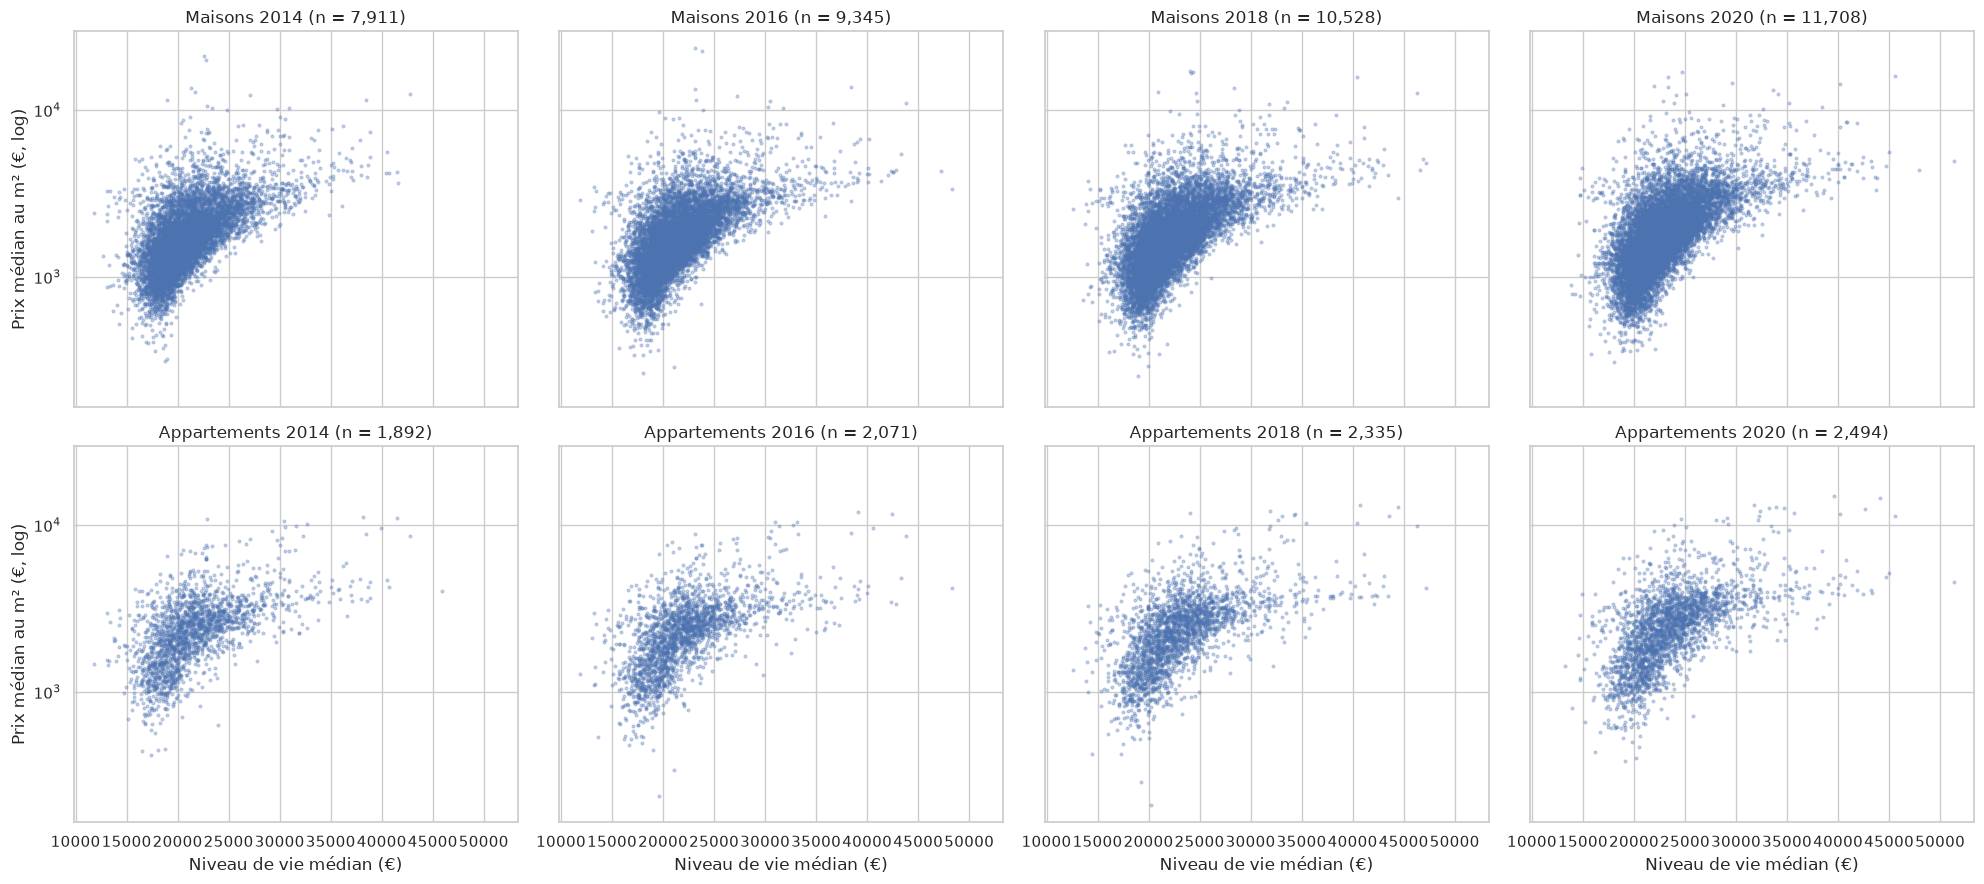

In [27]:
annees = [2014, 2016, 2018, 2020]
types = [("maison", "Maisons"), ("appart", "Appartements")]

fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharex=True, sharey=True)
for i, (t, nom) in enumerate(types):
    for j, an in enumerate(annees):
        d = fusion[(fusion["annee"] == an) & (fusion["cas"] == "revenu trouvé") & (fusion[f"n_{t}"] >= 10)]
        ax = axes[i, j]
        ax.scatter(d["niveau_vie_median"], d[f"prix_m2_med_{t}"], s=4, alpha=0.3)
        ax.set_yscale("log")
        ax.set_title(f"{nom} {an} (n = {len(d):,})")
        if j == 0:
            ax.set_ylabel("Prix médian au m² (€, log)")
        if i == 1:
            ax.set_xlabel("Niveau de vie médian (€)")
plt.tight_layout()
plt.show()

**Constat :**
- Pour les maisons comme pour les appartements, le prix médian au m² augmente avec le niveau de vie médian de la commune : le nuage de points monte de gauche à droite.
- Le lien n'est pas une droite : le prix monte nettement pour les niveaux de vie modestes à moyens, puis le nuage s'élargit et monte moins régulièrement pour les communes les plus aisées.
- La dispersion est forte : à niveau de vie égal, le prix au m² peut être très différent d'une commune à l'autre.
- Quelques communes ont un niveau de vie modeste et des prix élevés.
- L'analyse porte sur 11 386 communes pour les maisons, mais seulement 2 450 pour les appartements : il faut au moins 10 ventes d'appartements, ce qui concerne surtout les communes urbaines.

**Hypothèse :** il existe un lien positif entre le niveau de vie des habitants et le prix au m², pour les deux types de biens. Une partie importante des écarts dépend aussi de la localisation (région, littoral, proximité d'une grande ville).

**Méthode de vérification :** corrélation de Spearman pour chaque type de bien. Elle mesure si les deux variables augmentent ensemble, sans supposer que le lien est une droite, et elle est peu sensible aux valeurs extrêmes. Taille d'effet : rho.

In [28]:
lignes = []
for an in range(2014, 2022):
    for t, nom in types:
        d = fusion[(fusion["annee"] == an) & (fusion["cas"] == "revenu trouvé") & (fusion[f"n_{t}"] >= 10)]
        rho, p = stats.spearmanr(d["niveau_vie_median"], d[f"prix_m2_med_{t}"])
        lignes.append({"annee": an, "type": nom, "rho": round(rho, 2), "n": len(d)})

rho_annees = pd.DataFrame(lignes).pivot(index="annee", columns="type", values=["rho", "n"])
display(rho_annees)

rho                    n         
type  Appartements Maisons Appartements  Maisons
annee                                           
2014          0.61    0.62       1892.0   7911.0
2015          0.62    0.64       2016.0   9005.0
2016          0.64    0.65       2071.0   9345.0
2017          0.64    0.66       2256.0  10515.0
2018          0.65    0.65       2335.0  10528.0
2019          0.66    0.66       2448.0  11384.0
2020          0.65    0.66       2494.0  11708.0
2021          0.65    0.66       2728.0  13344.0

**Résultat :** pour les maisons comme pour les appartements, la p-value est inférieure à 0,05 : on rejette H0, il existe un lien entre le niveau de vie et le prix au m². Ce lien est positif et fort : rho = 0,66 pour les deux types de biens en 2019 (11 386 communes pour les maisons, 2 450 pour les appartements). Il est stable de 2014 à 2021 (voir la vérification sur plusieurs années).

**Interprétation :** plus les habitants d'une commune ont un niveau de vie élevé, plus le prix au m² y est élevé. Le lien est fort mais pas parfait : à niveau de vie égal, les prix restent très différents d'une commune à l'autre.

**Avis métier :** c'est logique : dans une commune aisée, les acheteurs peuvent payer plus cher. Mais le lien peut aussi aller dans l'autre sens : quand les prix sont élevés, seuls les ménages aisés peuvent venir s'installer. On ne peut donc pas dire que le revenu « cause » le prix. Les communes modestes aux prix élevés sont peut-être proches d'une grande ville ou sur le littoral, où la localisation compterait plus que le revenu des habitants (hypothèse à vérifier).

**Impact projet :** le niveau de vie médian est une variable candidate intéressante pour le modèle, pour les maisons comme pour les appartements.

**Action envisagée :**
- vérifier en C2.2 si le niveau de vie est aussi lié à l'**évolution** des prix, et pas seulement à leur niveau (B1.3 a montré que le niveau de vie change peu dans le temps) ;
- dans le modèle, associer le niveau de vie à une variable de localisation (le département, par exemple), pour séparer les deux effets.

**Biais / limites :**
- seules les communes avec au moins 10 ventes sont prises en compte : pour les appartements, ce sont surtout des communes urbaines ;
- Filosofi décrit les habitants de la commune, pas les acheteurs ;
- une corrélation ne prouve pas une relation de cause à effet.

### C2.2 Évolution des prix et du niveau de vie

**Sources et rapprochement :** table cible et Filosofi, par `code_commune` + `annee`, de 2014 à 2021.

**Variables :** `prix_m2_med_maison`, `prix_m2_med_appart`, `niveau_vie_median`.

**Pourquoi regarder cela :** C2.1 a montré que les communes aisées ont des prix plus élevés. Mais le projet porte sur l'évolution des prix. On veut savoir si les prix et le niveau de vie évoluent de la même façon dans le temps.

**Méthode :** on suit les mêmes communes de 2014 à 2021 (au moins 10 ventes chaque année). Pour chaque année, on calcule la médiane des prix et des niveaux de vie de ces communes, puis on les transforme en indice (base 100 en 2014) pour pouvoir comparer leurs évolutions sur un même axe.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, (t, nom) in zip(axes, [("maison", "Maisons"), ("appart", "Appartements")]):
    d = fusion[(fusion["cas"] == "revenu trouvé") & (fusion[f"n_{t}"] >= 10)]

    # On suit les mêmes communes chaque année (au moins 10 ventes les 8 années),
    # sinon la courbe changerait aussi parce que les communes changent
    nb_annees = d.groupby("code_commune")["annee"].nunique()
    d = d[d["code_commune"].isin(nb_annees[nb_annees == 8].index)]

    # Médiane des communes chaque année, puis indice base 100 en 2014
    serie = d.groupby("annee")[[f"prix_m2_med_{t}", "niveau_vie_median"]].median()
    indice = serie / serie.loc[2014] * 100

    ax.plot(indice.index, indice[f"prix_m2_med_{t}"], marker="o", label="Prix médian au m²")
    ax.plot(indice.index, indice["niveau_vie_median"], marker="s", label="Niveau de vie médian")
    ax.axhline(100, color="grey", ls=":")
    ax.set_title(f"{nom} : {d['code_commune'].nunique():,} communes suivies de 2014 à 2021")
    ax.set_xlabel("Année")
    ax.set_ylabel("Indice (2014 = 100)")
    ax.legend()

plt.tight_layout()
plt.show()

**Constat :**
- Sur les mêmes communes suivies de 2014 à 2021, le niveau de vie médian augmente régulièrement, presque en ligne droite.
- Le prix médian au m² suit une autre forme : il stagne ou recule légèrement jusqu'en 2016, puis augmente de plus en plus vite, surtout à partir de 2019.
- Les deux courbes se croisent vers 2019 pour les maisons et vers 2020 pour les appartements : avant, les revenus augmentent plus vite que les prix ; après, les prix augmentent plus vite que les revenus.

**Hypothèse :** il n'y a pas de lien entre l'évolution du niveau de vie d'une commune et l'évolution de ses prix.

**Méthode de vérification :** en deux étapes, pour chaque type de bien.

1. **Lien entre les évolutions.** Pour chaque commune suivie de 2014 à 2021 (au moins 10 ventes en 2014 et en 2021), on calcule l'évolution du prix au m² et celle du niveau de vie sur la période. On mesure le lien entre les deux avec une corrélation de Spearman. On mesure aussi le lien entre le niveau de vie de départ (2014) et l'évolution des prix, pour comparer. Avec autant de communes, le lien est presque toujours significatif : on conclut donc sur la taille d'effet (rho).

2. **Apport pour la prédiction.** Un lien, même significatif, ne dit pas si la variable aide à prédire. On entraîne une régression linéaire sur 2015-2018, puis on prédit le prix au m² de chaque commune en 2019. On compare deux versions du modèle : avec le prix de l'année précédente seul, puis avec le niveau de vie en plus. On ne garde que les communes avec au moins 10 ventes l'année N et l'année N-1. Le prix est pris en logarithme, car sa distribution est très asymétrique. On compare les deux versions avec deux mesures :
   - le R² sur l'évolution : la part de l'évolution réelle des prix entre N-1 et N que le modèle retrouve ;
   - l'erreur médiane : l'écart habituel, en %, entre le prix prédit et le prix réel.

   L'écart entre les deux versions sert de taille d'effet : si le niveau de vie aide à prédire l'évolution, la version avec niveau de vie doit nettement améliorer les deux mesures.

In [ ]:
def evolution(t, debut, fin):
    """Une ligne par commune : prix et niveau de vie au début et à la fin de la période, et leurs évolutions (%)."""
    cols = ["code_commune", f"n_{t}", f"prix_m2_med_{t}", "niveau_vie_median"]
    a = fusion.loc[fusion["annee"] == debut, cols]
    b = fusion.loc[fusion["annee"] == fin, cols]
    d = a.merge(b, on="code_commune", suffixes=("_debut", "_fin"))
    d = d[(d[f"n_{t}_debut"] >= 10) & (d[f"n_{t}_fin"] >= 10)].dropna()
    d["evol_prix"] = (d[f"prix_m2_med_{t}_fin"] / d[f"prix_m2_med_{t}_debut"] - 1) * 100
    d["evol_nv"] = (d["niveau_vie_median_fin"] / d["niveau_vie_median_debut"] - 1) * 100
    return d

evo = {"Maisons": evolution("maison", 2014, 2021),
       "Appartements": evolution("appart", 2014, 2021)}

for nom, d in evo.items():
    rho_niv, p_niv = stats.spearmanr(d["niveau_vie_median_debut"], d["evol_prix"])
    rho_evo, p_evo = stats.spearmanr(d["evol_nv"], d["evol_prix"])
    print(f"{nom} (n = {len(d)} communes)")
    print(f"  niveau de vie 2014         / évolution des prix : rho = {rho_niv:.2f} | p-value = {p_niv:.1e}")
    print(f"  évolution du niveau de vie / évolution des prix : rho = {rho_evo:.2f} | p-value = {p_evo:.1e}")

In [ ]:
for t, nom in [("maison", "Maisons"), ("appart", "Appartements")]:
    d = fusion[(fusion["cas"] == "revenu trouvé") & (fusion[f"n_{t}"] >= 10)]
    d = d[["code_commune", "annee", f"prix_m2_med_{t}", "niveau_vie_median"]].copy()
    d["log_prix"] = np.log(d[f"prix_m2_med_{t}"])

    prec = d[["code_commune", "annee", "log_prix"]].rename(columns={"log_prix": "log_prix_prec"})
    prec["annee"] += 1
    d = d.merge(prec, on=["code_commune", "annee"])

    train = d[d["annee"].between(2015, 2018)]
    test = d[d["annee"] == 2019]
    evol_reelle = test["log_prix"] - test["log_prix_prec"]

    print(f"{nom} (test : {len(test)} communes)")
    for nom_modele, X in [("sans revenu", ["log_prix_prec"]),
                          ("avec revenu", ["log_prix_prec", "niveau_vie_median"])]:
        pred = LinearRegression().fit(train[X], train["log_prix"]).predict(test[X])
        erreur = np.median(np.abs(np.exp(pred) / test[f"prix_m2_med_{t}"] - 1)) * 100
        print(f"  {nom_modele:12} R² évolution = {r2_score(evol_reelle, pred - test['log_prix_prec']):.3f}"
              f" | erreur médiane = {erreur:.1f} %")

**Résultat :**

*Lien entre les évolutions (2014-2021)*
- Maisons (7 586 communes) : le lien entre l'évolution du niveau de vie et l'évolution des prix est positif mais faible (rho = 0,14 ; p-value < 0,05). Le lien entre le niveau de vie de départ et l'évolution des prix est aussi faible (rho = 0,18).
- Appartements (1 829 communes) : liens faibles également (rho = 0,20 et 0,21 ; p-value < 0,05).

L'hypothèse d'une absence de lien n'est donc pas confirmée : un lien existe, mais il est faible, bien plus faible que celui entre le niveau de vie et le niveau des prix (rho = 0,66 en C2.1).

*Apport pour la prédiction (test sur 2019)*

| | R² évolution sans revenu | R² évolution avec revenu | Erreur médiane sans revenu | Erreur médiane avec revenu |
|---|---|---|---|---|
| Maisons (9 301 communes) | 0,008 | 0,031 | 7,4 % | 7,3 % |
| Appartements (2 168 communes) | −0,076 | −0,058 | 5,2 % | 5,2 % |

Ajouter le niveau de vie fait gagner environ 0,02 de R² sur l'évolution et ne change presque pas l'erreur médiane (−0,1 point pour les maisons, aucun changement pour les appartements). Dans les deux versions, le modèle ne retrouve presque rien de l'évolution des prix : un R² négatif signifie qu'il fait moins bien que s'il prédisait simplement la hausse moyenne de 2019.

**Interprétation :** le niveau de vie explique surtout **où** les prix sont élevés, et beaucoup moins **comment** ils évoluent. Les prix ont un peu plus augmenté dans les communes aisées et dans celles où le niveau de vie a progressé, mais cet effet est faible et n'améliore pas la prédiction. Le niveau des prix d'une commune est d'ailleurs déjà connu grâce à son prix de l'année précédente.

**Avis métier :** l'évolution des prix dépend sans doute d'abord de facteurs communs à tout le pays (taux d'emprunt, crise sanitaire), qui ont fait monter les prix partout à partir de 2019, alors que le niveau de vie progressait régulièrement. Le R² négatif va dans ce sens : le modèle rate surtout le mouvement d'ensemble du marché en 2019, que le niveau de vie, différent d'une commune à l'autre, ne peut pas capter.

**Impact projet :** le niveau de vie n'apporte pas de gain utile pour prédire l'évolution des prix. Comme il pose aussi des problèmes pratiques (données jusqu'en 2021 seulement, passage au bassin de vie), nous proposons de l'écarter de la modélisation. Décision à valider avec l'équipe et le mentor.

**Action envisagée :** étudier le lien entre l'évolution des prix et les taux d'emprunt mensuels (prochaine source).

**Biais / limites :**
- l'évolution du niveau de vie d'une commune est bruitée (B1.3), ce qui affaiblit la corrélation mesurée : le lien réel est peut-être un peu plus fort ;
- seules les communes avec assez de ventes sont prises en compte (au moins 10 en 2014 et en 2021 pour la corrélation, l'année N et l'année N-1 pour la régression) : les petites communes rurales sont peu représentées ;
- une corrélation ne prouve pas une relation de cause à effet ;
- le test de prédiction porte sur une seule année (2019) et utilise un modèle linéaire : un modèle plus complexe pourrait mieux exploiter le niveau de vie ;
- Filosofi s'arrête en 2021. Le retournement du marché observé dans DVF+ (pic des ventes en 2021, puis baisse nette en 2022 et 2023) se situe donc en dehors de la période où l'on peut comparer prix et niveau de vie. On ne peut pas vérifier si le lien entre niveau de vie et prix a changé pendant ce retournement. Pour un test sur 2025, le modèle devrait en plus utiliser un niveau de vie vieux de 4 ans.

### C2.3 Comparaison géographique : prix des maisons et niveau de vie

**Sources et rapprochement :** table cible et Filosofi, par `code_commune` + `annee`, année 2019, communes avec au moins 10 ventes de maisons ; regroupement par département.

**Variables :** `prix_m2_med_maison`, `niveau_vie_median`, département (deux premiers caractères du code commune).

**Pourquoi regarder cela :** C2.1 a montré un lien fort entre niveau de vie et prix au m². On veut voir si les départements les plus chers sont aussi les plus aisés, ou si certaines zones font exception.

**Méthode :** pour chaque département, médiane des prix et médiane des niveaux de vie de ses communes. Les départements sont classés en 5 groupes de même taille pour chaque variable, et affichés sur deux cartes avec les mêmes couleurs.

In [ ]:
import geopandas as gpd

url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson"
deps = gpd.read_file(url)

groupes = ["1 - très bas", "2 - bas", "3 - moyen", "4 - élevé", "5 - très élevé"]
fig, axes = plt.subplots(2, 2, figsize=(16, 15))

for i, (t, nom) in enumerate([("maison", "maisons"), ("appart", "appartements")]):
    # Communes de 2019 avec au moins 10 ventes du type de bien et un niveau de vie connu
    d = fusion[(fusion["annee"] == 2019) & (fusion["cas"] == "revenu trouvé") & (fusion[f"n_{t}"] >= 10)].copy()
    d["dep"] = d["code_commune"].str[:2]

    # Une ligne par département : médiane des communes
    par_dep = (d.groupby("dep")
                 .agg(prix=(f"prix_m2_med_{t}", "median"),
                      niveau_vie=("niveau_vie_median", "median"),
                      nb_communes=("code_commune", "size"))
                 .reset_index())

    carte = deps.merge(par_dep, left_on="code", right_on="dep", how="left")
    carte["classe_prix"] = pd.qcut(carte["prix"], 5, labels=groupes)
    carte["classe_nv"] = pd.qcut(carte["niveau_vie"], 5, labels=groupes)

    for j, (col, titre) in enumerate([("classe_prix", f"Prix médian au m² des {nom} (2019)"),
                                      ("classe_nv", f"Niveau de vie médian (communes avec ventes de {nom})")]):
        ax = axes[i, j]
        carte.plot(column=col, cmap="YlOrRd", legend=True, ax=ax,
                   edgecolor="white", linewidth=0.3,
                   missing_kwds={"color": "lightgrey", "label": "pas de données"})
        ax.set_title(titre)
        ax.set_axis_off()

    print(f"{nom} : {par_dep['dep'].nunique()} départements, de {par_dep['nb_communes'].min()} "
          f"à {par_dep['nb_communes'].max()} communes par département")

plt.tight_layout()
plt.show()

**Constat :**

*Maisons*
- Plusieurs zones sont foncées sur les deux cartes, donc à la fois chères et aisées : l'Île-de-France, les Alpes du Nord et la région lyonnaise, la Côte d'Azur, et autour de Toulouse.
- Le centre de la France est clair sur les deux cartes : prix bas et niveau de vie modeste.
- Certaines zones ne concordent pas :
  - le littoral méditerranéen (de l'Hérault aux Pyrénées-Orientales) et la Corse ont des prix élevés, mais un niveau de vie moyen ou bas ;
  - à l'inverse, une partie du Nord-Est a un niveau de vie élevé mais des prix bas.

*Appartements*
- Les deux cartes se ressemblent davantage : l'Île-de-France, la façade atlantique, les Alpes du Nord et la Côte d'Azur sont foncées sur les deux.
- Les exceptions sont moins nombreuses que pour les maisons.

*Pour les deux types* : l'Alsace-Moselle est en gris (absente de DVF+).

**Hypothèse :** au niveau des départements, les prix et le niveau de vie sont liés, et ce lien est plus fort pour les appartements que pour les maisons. Pour les maisons, d'autres facteurs comme l'attrait touristique du littoral ou l'éloignement des grandes villes pèseraient davantage.

**Méthode de vérification :** pour chaque type de bien, corrélation de Spearman entre le prix médian et le niveau de vie médian des départements. On compare ensuite les deux valeurs de rho.

In [ ]:
# Test 1 : lien entre prix et niveau de vie au niveau des départements, pour chaque type de bien
for t, nom in [("maison", "Maisons"), ("appart", "Appartements")]:
    d = fusion[(fusion["annee"] == 2019) & (fusion["cas"] == "revenu trouvé") & (fusion[f"n_{t}"] >= 10)].copy()
    d["dep"] = d["code_commune"].str[:2]

    # Une ligne par département : médiane des communes
    pdep = d.groupby("dep").agg(prix=(f"prix_m2_med_{t}", "median"),
                                niveau_vie=("niveau_vie_median", "median"))

    rho, p = stats.spearmanr(pdep["prix"], pdep["niveau_vie"])
    print(f"{nom} : rho = {rho:.2f} | p-value = {p:.1e} | n = {len(pdep)} départements")

**Résultat :** pour les deux types de biens, la p-value est inférieure à 0,05 : on rejette H0, il existe un lien entre le prix médian et le niveau de vie médian des départements. Ce lien est positif et fort : rho = 0,66 pour les maisons et rho = 0,73 pour les appartements (93 départements).

**Interprétation :** les départements les plus aisés sont en général les plus chers, pour les maisons comme pour les appartements. Le lien est un peu plus fort pour les appartements, ce qui va dans le sens des cartes, mais l'écart entre les deux valeurs est faible : avec seulement 93 départements, on ne peut pas affirmer qu'il est réel.

**Avis métier :** les exceptions visibles sur les cartes, surtout pour les maisons, correspondent à des zones où d'autres facteurs comptent : l'attrait touristique (littoral méditerranéen, Corse), qui fait monter les prix sans lien avec le revenu des habitants, ou l'éloignement des grandes villes, qui les maintient bas malgré un niveau de vie correct (hypothèses).

**Impact projet :** le niveau de vie résume bien une partie de la géographie des prix, mais pas toute. Une variable de localisation (département ou bassin de vie) reste nécessaire dans le modèle pour capter les zones qui font exception.

**Action envisagée :** dans la suite du projet, regarder si des variables comme la part de résidences secondaires ou la distance à une grande ville expliquent les exceptions (sources à identifier avec l'équipe).

**Biais / limites :**
- une seule année (2019) ;
- chaque département est résumé par la médiane de ses communes, sans tenir compte de leur nombre d'habitants ni de leur nombre de ventes ;
- la carte du niveau de vie des appartements ne porte que sur les communes avec au moins 10 ventes d'appartements, surtout urbaines ;
- l'Alsace-Moselle n'est pas couverte.

## C3. Temps et financement (DVF+, taux des crédits)

**Contributeurs :** Cécile NAUDET · **Date :** 16/10/2026

C3.1 décrit l'évolution des prix et des ventes dans DVF+. C3.2 la rapproche du taux des crédits immobiliers (Banque de France), puis C3.3 croise le taux avec le niveau de vie (C2).

### C3.1 Évolution du prix au m² et du nombre de ventes dans le temps

**Variables :** `prix_m2`, `datemut`, `type_bien`.

**Pourquoi regarder cela :** le projet porte sur l'évolution des prix. On veut voir comment le prix au m² et le nombre de ventes ont évolué entre 2014 et 2023.

**Méthode :** nombre de ventes par trimestre, pour les maisons et pour les appartements, calculés sur la population (après les règles de A1) ainsi que l'évolution du prix au m² par trimestre.

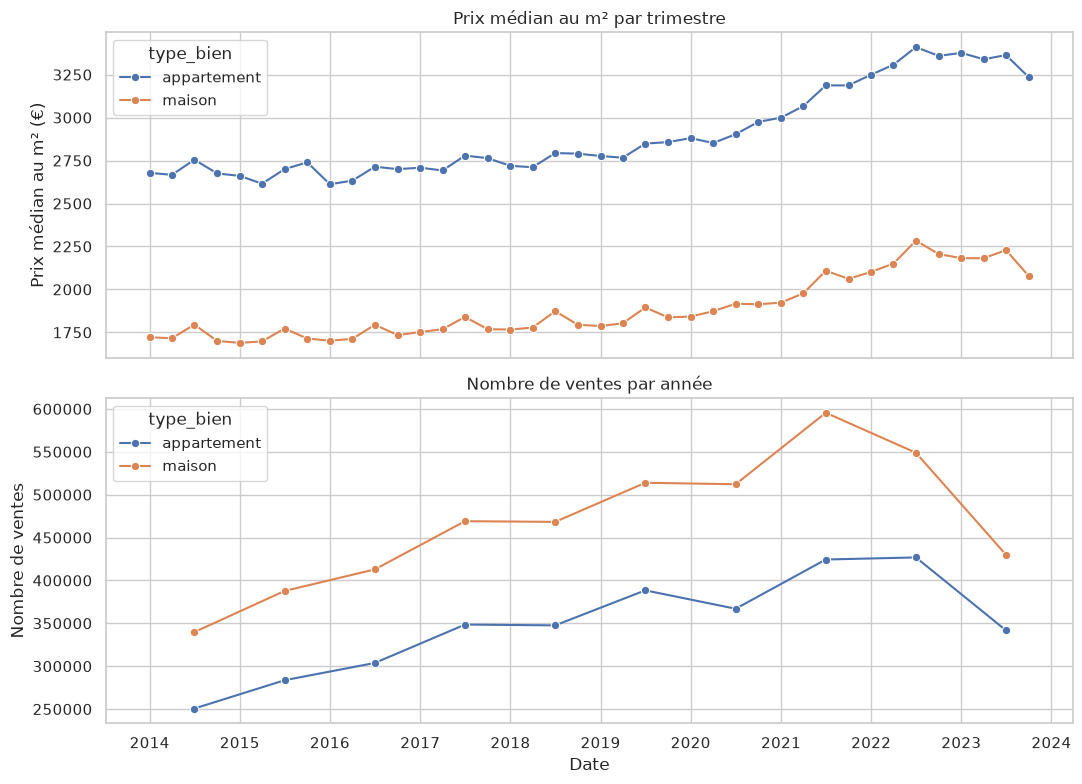

In [24]:
# Trimestre de chaque vente
ventes["trimestre"] = pd.to_datetime(ventes["datemut"], format="%Y-%m-%d").dt.to_period("Q")

# Prix médian par trimestre et par type
trim = (ventes.groupby(["trimestre", "type_bien"])["prix_m2"]
              .median().reset_index(name="prix_m2_median"))
trim["trimestre"] = trim["trimestre"].dt.to_timestamp()   # format date, pour l'axe du graphique

# Nombre de ventes par année et par type
annuel = ventes.groupby(["anneemut", "type_bien"]).size().reset_index(name="nb_ventes")
annuel["date"] = pd.to_datetime(annuel["anneemut"].astype(str) + "-07-01")   # point placé au milieu de l'année

# Deux graphiques l'un au-dessus de l'autre, avec le même axe du temps
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

sns.lineplot(data=trim, x="trimestre", y="prix_m2_median", hue="type_bien", marker="o", ax=axes[0])
axes[0].set_ylabel("Prix médian au m² (€)")
axes[0].set_title("Prix médian au m² par trimestre")

sns.lineplot(data=annuel, x="date", y="nb_ventes", hue="type_bien", marker="o", ax=axes[1])
axes[1].set_ylabel("Nombre de ventes")
axes[1].set_title("Nombre de ventes par année")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

**Résultat :** on distingue trois périodes :
- de 2014 à 2018, les prix sont presque stables, et le nombre de ventes augmente ;
- de 2019 à 2022, les prix augmentent nettement et le nombre de ventes atteint un pic en 2021 (plus d'un million de ventes) ;
- en 2023, le nombre de ventes baisse de 21 % et les prix baissent légèrement.

**Interprétation :** la période compte beaucoup : selon les années, les prix et les ventes ne suivent pas la même tendance. Les prix réagissent avec un temps de retard : ils continuent de monter en 2022 alors que les ventes commencent déjà à baisser.

**Avis métier :** ces évolutions sont liées au contexte économique (taux des crédits, confinement de 2020). Le lien avec les taux est étudié en C3.2.

**Impact projet :** un modèle qui ne verrait qu'une seule période (par exemple les années de hausse) risquerait de mal prédire une période de baisse. Les données d'entraînement et de test devront être séparées par date, comme le recommande le cours sur les séries temporelles.

**Action envisagée :** garder toute la période 2014-2023 pour l'entraînement. Étudier le lien avec les taux d'intérêt (C3.2).

**Biais / limites :** le prix médian national mélange tous les territoires et dépend du type de biens vendus chaque année. Les années 2024 et 2025 n'ont pas été regardées.

### C3.2 Évolution des prix et taux des crédits immobiliers

**Sources et rapprochement :** prix médian au m² par trimestre et par type de bien, calculé en C3.1 (population après les règles de A1), et taux moyen des crédits nouveaux à l'habitat des particuliers (Banque de France, série MIR1.M.FR.B.A22.A.R.A.2254U6.EUR.N, mensuelle). Rapprochement par trimestre, de 2014 à 2023, à l'échelle de la France entière.

**Variables :** `prix_m2_median` (maisons et appartements), `taux` (moyenne des trois mois de chaque trimestre).

**Pourquoi regarder cela :** C2.2 a montré que le niveau de vie explique peu l'évolution des prix, et que le modèle rate surtout le mouvement d'ensemble du marché, commun à toutes les communes. Le taux des crédits est le même pour toute la France et ne varie que dans le temps : il pourrait expliquer ce mouvement d'ensemble.

**Méthode :** on trace sur un même graphique le prix médian au m² et le taux moyen par trimestre, avec un second axe pour le taux, puisque les unités sont différentes.

40 trimestres


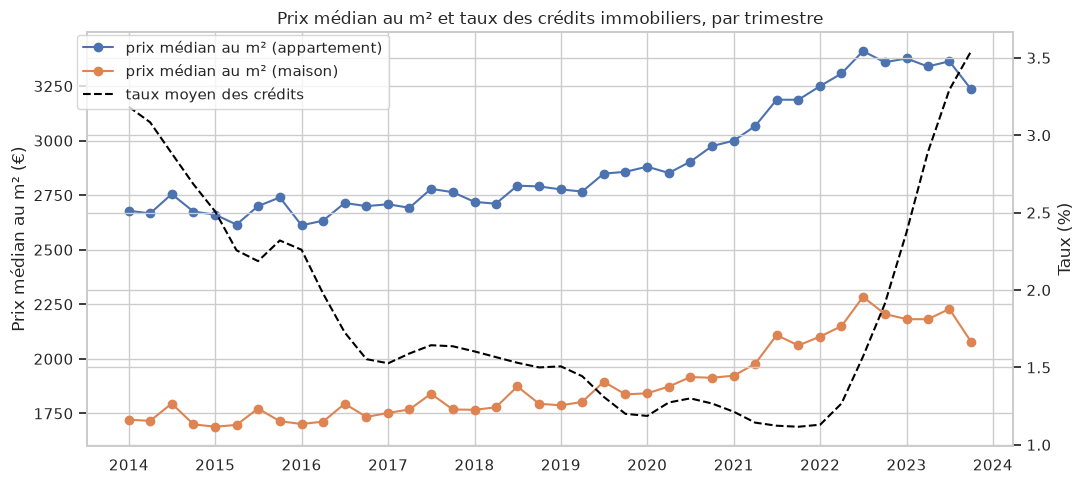

In [25]:
# Taux mensuels -> taux moyen par trimestre (moyenne des 3 mois)
taux = pd.read_csv(DATA_RAW / "Taux d'intérêt annuel des crédits immobiliers.csv",
                   sep=";", decimal=",", skiprows=6, header=None,
                   names=["date", "taux"], parse_dates=["date"], encoding="utf-8-sig")
taux["trimestre"] = taux["date"].dt.to_period("Q").dt.to_timestamp()
taux_trim = taux.groupby("trimestre")["taux"].mean()

# Prix médian par trimestre (calculé en C3.1), une colonne par type de bien
prix_trim = trim.pivot(index="trimestre", columns="type_bien", values="prix_m2_median")

# Une ligne par trimestre, de 2014 à 2023
tp = prix_trim.join(taux_trim).loc["2014":"2023"]
print(len(tp), "trimestres")

# Prix à gauche, taux à droite (second axe, car les unités sont différentes)
fig, ax = plt.subplots(figsize=(11, 5))
for col in prix_trim.columns:
    ax.plot(tp.index, tp[col], marker="o", label=f"prix médian au m² ({col})")
ax.set_ylabel("Prix médian au m² (€)")
ax2 = ax.twinx()
ax2.plot(tp.index, tp["taux"], color="black", linestyle="--", label="taux moyen des crédits")
ax2.set_ylabel("Taux (%)")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.93))
ax.set_title("Prix médian au m² et taux des crédits immobiliers, par trimestre")
plt.tight_layout()
plt.show()

**Constat :**
- Le taux moyen baisse presque sans interruption de 2014 à 2021 (de 2,96 % à 1,15 % en moyenne annuelle), puis remonte très vite en 2022 et 2023 (3,02 % en moyenne en 2023).
- Le prix médian au m² est presque stable jusqu'en 2018, augmente nettement de 2019 à 2022, puis stagne et baisse fin 2023.
- Les prix continuent de monter pendant quelques trimestres après le début de la remontée des taux.
- On ne voit pas de lien direct entre le niveau du taux et le niveau des prix.
- Le prix des maisons varie selon la saison : il est plus élevé chaque 3e trimestre.

**Hypothèse :** le taux n'agit pas sur le niveau des prix, mais sur leur évolution, avec un retard : quand les taux sont bas, les prix augmentent dans les trimestres suivants ; quand ils montent, la hausse des prix ralentit.

**Méthode de vérification :** pour chaque trimestre, on calcule l'évolution du prix sur un an, en le comparant au même trimestre de l'année précédente, ce qui retire l'effet de saison. On mesure ensuite le lien entre cette évolution et le taux observé 0 à 8 trimestres plus tôt, avec une corrélation de Spearman, pour chaque type de bien. Taille d'effet : rho. Le retard qui donne le rho le plus fort indique le délai de réaction des prix.

In [ ]:
# Évolution du prix sur un an : on compare chaque trimestre au même trimestre de l'année
# précédente, ce qui retire l'effet de saison
for col in prix_trim.columns:
    tp[f"evol_{col}"] = (tp[col] / tp[col].shift(4) - 1) * 100

# Lien entre le taux d'il y a k trimestres et l'évolution du prix sur un an
for col in prix_trim.columns:
    print(col)
    for k in range(0, 9):
        x = tp["taux"].shift(k)            # taux k trimestres plus tôt
        ok = x.notna() & tp[f"evol_{col}"].notna()
        rho, p = stats.spearmanr(x[ok], tp.loc[ok, f"evol_{col}"])
        print(f"  retard de {k} trimestre(s) : rho = {rho:.2f} | p-value = {p:.1e} | n = {ok.sum()}")

**Résultat :** pour tous les retards, la p-value est inférieure à 0,05 : on rejette H0. Le lien est négatif et fort, et presque identique pour les deux types de biens. Il est le plus fort avec 2 trimestres de retard (rho = −0,84 pour les appartements, −0,85 pour les maisons), reste proche de −0,8 entre 1 et 3 trimestres, puis s'affaiblit (environ −0,4 avec 8 trimestres de retard).

**Pourquoi ces graphiques :** un rho fort peut venir d'un seul épisode, par exemple la remontée des taux de 2022-2023. On vérifie donc sur quoi repose le lien, avec le retard de 2 trimestres :
- à gauche, l'évolution des prix et le taux décalé dans le temps, avec l'axe du taux inversé (un taux bas est placé en haut). Si le lien est réel, les courbes doivent se suivre sur toute la période ;
- à droite, un point par trimestre, coloré selon l'année. Si le lien est réel, les points doivent former une bande inclinée où les années se mélangent, et non deux paquets séparés.

In [ ]:
# Taux 2 trimestres plus tôt (le retard qui donne le lien le plus fort)
tp["taux_ret2"] = tp["taux"].shift(2)
d = tp.dropna(subset=["taux_ret2"] + [f"evol_{c}" for c in prix_trim.columns])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Dans le temps : évolution des prix et taux décalé, avec l'axe du taux inversé
for col in prix_trim.columns:
    axes[0].plot(d.index, d[f"evol_{col}"], marker="o", label=f"évolution du prix sur un an ({col})")
axes[0].axhline(0, color="grey", linestyle=":")
axes[0].set_ylabel("Évolution du prix médian au m² sur un an (%)")
ax2 = axes[0].twinx()
ax2.plot(d.index, d["taux_ret2"], color="black", linestyle="--", label="taux 2 trimestres plus tôt")
ax2.invert_yaxis()
ax2.set_ylabel("Taux (%), axe inversé")
axes[0].set_title("Évolution des prix et taux décalé de 2 trimestres")
h1, l1 = axes[0].get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
axes[0].legend(h1 + h2, l1 + l2, loc="lower center")

# 2. Nuage de points : un point par trimestre, couleur = année
for col, forme in zip(prix_trim.columns, ["o", "s"]):
    nuage = axes[1].scatter(d["taux_ret2"], d[f"evol_{col}"], c=d.index.year,
                            cmap="viridis", marker=forme, label=col)
axes[1].axhline(0, color="grey", linestyle=":")
axes[1].set_xlabel("Taux 2 trimestres plus tôt (%)")
axes[1].set_ylabel("Évolution du prix sur un an (%)")
axes[1].set_title("Un point par trimestre")
axes[1].legend()
plt.colorbar(nuage, ax=axes[1], label="Année")

plt.tight_layout()
plt.show()

**Constat :**
- Les courbes se suivent sur toute la période, pas seulement en 2022-2023 : la baisse des taux de 2015-2016 est suivie d'une reprise des prix, la légère remontée de 2018 d'un ralentissement, les taux les plus bas de 2020-2021 d'une forte accélération, et la remontée de 2022-2023 d'une chute de l'évolution des prix, qui devient négative.
- La hausse des prix de 2021 dépasse ce que le niveau du taux laisserait attendre.
- Dans le nuage de points, les trimestres forment une bande inclinée vers le bas. Les années se mélangent le long de cette bande : les trimestres de 2023 se placent à côté de ceux de 2015 et 2016, sur la même pente.
- La pente semble plus forte pour les taux les plus bas, mais ces points correspondent surtout à l'année 2021.

**Interprétation :** le taux des crédits est fortement lié à l'évolution des prix, avec un retard d'environ six mois. Le lien se retrouve sur toute la période 2014-2023 : il ne repose pas sur le seul retournement de 2022. Le taux n'explique pas tout pour autant : la forte hausse de 2021 montre que d'autres facteurs ont joué.

**Avis métier :** le taux fixe la capacité d'emprunt des ménages, donc le prix qu'ils peuvent payer. Le retard est logique : le prêt est accordé plusieurs mois avant la signature chez le notaire, et c'est le prix de la signature qui est enregistré dans DVF+. La hausse de 2021 correspond probablement au rattrapage des achats après les confinements de 2020. Avec le temps, les ménages pourraient s'habituer à des taux plus élevés, et l'effet s'atténuer.

**Impact projet :** le taux des crédits est une variable candidate forte pour prédire l'évolution des prix. Il est le même pour toutes les communes : il explique les évolutions dans le temps, mais pas les écarts entre territoires, et complète donc les variables de localisation. Il est publié environ deux mois après le mois concerné, donc disponible au moment de prédire.

**Action envisagée :** ajouter le taux des crédits, avec un retard, aux variables candidates. Choisir avec le groupe comment le ramener à la cible commune × année (par exemple, taux moyen des quatre trimestres qui précèdent le milieu de l'année). Étudier ensuite le lien entre le niveau de vie et le taux, puis le croisement des trois variables.

**Biais / limites :**
- les trimestres se suivent et se ressemblent : les points ne sont pas indépendants, donc les p-values sont trop optimistes ; on conclut sur rho et sur les graphiques ;
- la période couvre surtout une longue baisse des taux et une seule remontée ;
- une corrélation ne prouve pas une relation de cause à effet : en 2022, les taux ont monté en même temps que l'inflation, qui pèse aussi sur le budget des ménages ;
- le prix médian national mélange tous les territoires et dépend des biens vendus chaque trimestre ;
- 2024 et 2025 n'ont pas été regardées : on ne peut pas vérifier si l'effet s'atténue quand les ménages s'habituent à des taux élevés.

### C3.3 Prix au m², niveau de vie et taux des crédits

**Sources et rapprochement :** table cible (DVF+) et Filosofi par `code_commune` + `annee` ; taux moyen des crédits nouveaux à l'habitat (Banque de France) par `annee`. Pour appliquer le retard d'environ deux trimestres trouvé en C3.2, le taux de l'année N est la moyenne des taux de juillet N-1 à juin N. Période : 2014-2021, dernière année disponible dans Filosofi. On travaille par année, puisque Filosofi n'est publié que par année.

**Variables :** `niveau_vie_median`, `prix_m2_med_maison`, `prix_m2_med_appart`, `taux`.

**Pourquoi regarder cela :** C2.2 a montré que le niveau de vie explique surtout les écarts de prix entre communes, et peu leur évolution. C3.2 a montré que le taux des crédits est fortement lié à l'évolution des prix dans le temps. On veut savoir si ces deux variables portent la même information, ou si elles se complètent pour expliquer l'évolution des prix.

**Méthode :** pour chaque année, on calcule l'évolution du prix au m² de chaque commune par rapport à l'année précédente (au moins 10 ventes les deux années). On classe les communes en trois groupes de même taille selon leur niveau de vie (modestes, intermédiaires, aisées), puis on calcule l'évolution médiane des prix de chaque groupe. On place ces évolutions en fonction du taux des crédits de l'année, avec une couleur par groupe.

Le taux associé à l'année N n'est pas la moyenne de janvier à décembre N, mais celle de **juillet N-1 à juin N**. En effet, une vente est souvent financée par un prêt accordé plusieurs mois avant la signature chez le notaire, et c'est la date de signature qui est enregistrée dans DVF+. C3.2 a mesuré ce retard : le lien entre le taux et l'évolution des prix est le plus fort quand le taux est pris deux trimestres, soit six mois, plus tôt. On décale donc la période du taux de six mois vers le passé.

In [ ]:
# Taux de l'année N : moyenne de juillet N-1 à juin N (retard de 2 trimestres, vu en C4)
taux["annee"] = (taux["date"] + pd.DateOffset(months=6)).dt.year
taux_an = taux.groupby("annee")["taux"].mean().rename("taux")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, (t, nom) in zip(axes, [("maison", "Maisons"), ("appart", "Appartements")]):
    d = fusion[(fusion["cas"] == "revenu trouvé") & (fusion[f"n_{t}"] >= 10)]
    d = d[["code_commune", "annee", f"prix_m2_med_{t}", "niveau_vie_median"]].copy()

    # Évolution du prix de chaque commune par rapport à l'année précédente (%)
    prec = d[["code_commune", "annee", f"prix_m2_med_{t}"]].rename(columns={f"prix_m2_med_{t}": "prix_prec"})
    prec["annee"] += 1
    d = d.merge(prec, on=["code_commune", "annee"])
    d["evol_prix"] = (d[f"prix_m2_med_{t}"] / d["prix_prec"] - 1) * 100

    # Trois groupes de même taille selon le niveau de vie, recalculés chaque année
    rang = d.groupby("annee")["niveau_vie_median"].rank(pct=True)
    d["groupe_nv"] = pd.cut(rang, [0, 1/3, 2/3, 1], labels=["modestes", "intermédiaires", "aisées"])

    # Un point par année et par groupe : évolution médiane du prix
    g = (d.groupby(["annee", "groupe_nv"], observed=True)["evol_prix"].median()
          .reset_index().merge(taux_an, left_on="annee", right_index=True))

    sns.lineplot(data=g, x="taux", y="evol_prix", hue="groupe_nv", marker="o", sort=False, ax=ax)
    ax.axhline(0, color="grey", linestyle=":")
    ax.set_xlabel("Taux moyen de juillet de l'année précédente à juin (%)")
    ax.set_title(f"{nom} : évolution médiane du prix selon le taux")
axes[0].set_ylabel("Évolution du prix sur un an (%)")
plt.tight_layout()
plt.show()

**Constat :**
- Dans les trois groupes de communes, l'évolution du prix diminue quand le taux augmente : elle est négative pour le taux le plus élevé (2015), et la plus forte pour les taux les plus bas (2020-2021).
- Pour les maisons, les trois lignes sont presque parallèles : les communes aisées sont un peu au-dessus, les communes modestes un peu en dessous. L'écart entre groupes reste faible à côté de l'effet du taux.
- Pour les appartements, quand le taux est le plus élevé (2015 et 2016), les prix des communes modestes baissent davantage que ceux des communes aisées. Les trois lignes se rejoignent quand les taux sont bas.
- Entre 2020 et 2021, le taux est presque le même, mais l'évolution des prix augmente nettement : un autre facteur a joué.
- Sur 2014-2021, le taux baisse presque chaque année : le classement par taux est donc aussi un classement dans le temps.

**Hypothèse :** le taux explique l'essentiel du mouvement des prix commun à toutes les communes ; le niveau de vie ajoute seulement un petit décalage entre communes. Les deux variables se complètent, mais l'apport du niveau de vie reste faible.

**Méthode de vérification :** on utilise une ligne par commune et par année (2015-2021), avec l'évolution du prix par rapport à l'année précédente. On calcule trois corrélations de Spearman, pour chaque type de bien :
1. entre le taux de l'année et l'évolution du prix ;
2. entre le niveau de vie de la commune et l'évolution du prix ;
3. entre le taux et l'évolution du prix, séparément dans chaque groupe de niveau de vie.

Taille d'effet : rho. Comparer 1 et 2 indique laquelle des deux variables est la plus liée à l'évolution des prix. Comparer les trois valeurs de 3 indique si le taux agit de la même façon dans tous les groupes de communes.

In [ ]:
for t, nom in [("maison", "Maisons"), ("appart", "Appartements")]:
    # Même préparation que pour le graphique : évolution du prix de chaque commune sur un an
    d = fusion[(fusion["cas"] == "revenu trouvé") & (fusion[f"n_{t}"] >= 10)]
    d = d[["code_commune", "annee", f"prix_m2_med_{t}", "niveau_vie_median"]].copy()
    prec = d[["code_commune", "annee", f"prix_m2_med_{t}"]].rename(columns={f"prix_m2_med_{t}": "prix_prec"})
    prec["annee"] += 1
    d = d.merge(prec, on=["code_commune", "annee"])
    d["evol_prix"] = (d[f"prix_m2_med_{t}"] / d["prix_prec"] - 1) * 100
    d = d.merge(taux_an, left_on="annee", right_index=True)
    rang = d.groupby("annee")["niveau_vie_median"].rank(pct=True)
    d["groupe_nv"] = pd.cut(rang, [0, 1/3, 2/3, 1], labels=["modestes", "intermédiaires", "aisées"])

    print(f"{nom} (n = {len(d)} lignes commune × année)")
    rho, p = stats.spearmanr(d["taux"], d["evol_prix"])
    print(f"  1. taux / évolution du prix          : rho = {rho:.2f} | p-value = {p:.1e}")
    rho, p = stats.spearmanr(d["niveau_vie_median"], d["evol_prix"])
    print(f"  2. niveau de vie / évolution du prix : rho = {rho:.2f} | p-value = {p:.1e}")
    for groupe, sous in d.groupby("groupe_nv", observed=True):
        rho, p = stats.spearmanr(sous["taux"], sous["evol_prix"])
        print(f"  3. taux / évolution, communes {groupe:14}: rho = {rho:.2f} | p-value = {p:.1e}")

**Résultat :** toutes les p-values sont inférieures à 0,05 : on rejette H0 pour chaque test. Avec plusieurs dizaines de milliers de lignes, on conclut sur la taille d'effet (rho).

| | Taux / évolution du prix | Niveau de vie / évolution du prix | Taux / évolution, par groupe (modestes / intermédiaires / aisées) |
|---|---|---|---|
| Maisons (61 433 lignes) | −0,21 (faible) | 0,09 (négligeable) | −0,17 / −0,22 / −0,24 |
| Appartements (14 344 lignes) | −0,33 (moyen) | 0,12 (faible) | −0,34 / −0,34 / −0,30 |

- Le taux est deux à trois fois plus lié à l'évolution des prix que le niveau de vie.
- Dans les trois groupes de niveau de vie, le lien entre le taux et l'évolution des prix est proche : le taux agit de la même façon quel que soit le niveau de vie de la commune.
- Les rho sont plus faibles que ce que laisse voir le graphique, car chaque commune compte ici avec les variations de sa propre médiane, alors que le graphique montre des médianes de groupes.

**Interprétation :** le taux et le niveau de vie portent des informations différentes. Le taux décrit le moment du marché, commun à toute la France, et c'est lui qui pèse le plus sur l'évolution des prix. Le niveau de vie décrit la commune et ne décale que légèrement l'évolution des prix : les communes aisées progressent un peu plus. Les deux effets s'ajoutent sans se renforcer : des taux élevés ne freinent pas davantage les communes modestes que les autres.

**Avis métier :** le taux fixe la capacité d'emprunt de tous les ménages au même moment, d'où son effet sur l'ensemble du marché. On pouvait penser que des taux élevés pénaliseraient davantage les ménages modestes, qui ont moins d'apport ; ce n'est pas visible à l'échelle des communes. Une explication possible : les ménages modestes et aisés vivent souvent dans les mêmes communes, et le niveau de vie médian d'une commune ne dit pas qui achète.

**Impact projet :** le taux des crédits est une variable candidate forte pour prédire l'évolution des prix. Le niveau de vie apporte peu en plus, que ce soit seul (C2.2) ou avec le taux (C3.3). Avec ses contraintes pratiques (données jusqu'en 2021, passage au bassin de vie), nous proposons de l'écarter, à condition que le modèle utilise le prix de l'année précédente, qui contient déjà l'information sur le niveau des prix de la commune.

**Action envisagée :** retenir le taux des crédits, avec un retard d'environ six mois, parmi les variables candidates. Proposer au groupe et au mentor d'écarter le niveau de vie médian.

**Biais / limites :**
- sur 2014-2021, le taux baisse presque chaque année : un lien avec le taux mesure aussi les autres effets propres à chaque année, comme le rebond de 2021 ; c'est C3.2, avec la remontée des taux de 2022-2023, qui montre que le taux joue vraiment ;
- rho mesure la régularité d'un lien, pas son intensité : un groupe de communes aux prix plus variables aura un rho plus faible même s'il réagit autant au taux ;
- le niveau de vie médian décrit la commune, pas les acheteurs : il ne permet pas de tester l'effet des taux selon le revenu des ménages qui achètent ;
- seules les communes avec au moins 10 ventes l'année N et l'année N-1 sont prises en compte ;
- un décalage entre le revenu et la vente n'a pas été testé ; il changerait peu le résultat, puisque le niveau de vie d'une commune varie peu d'une année à l'autre (B1.3).

## C4. Parc de logement et vacance (recensement 2022, LOVAC)

**Contributeurs :** Théophyle CHEVET · **Date :** octobre 2026

**Objectif :** mesurer le lien entre chaque indicateur de la base logement et de LOVAC et le prix au m², pour ne garder que les variables utiles.

**Rapprochement :** la table cible commune × année (bloc 4) sert de base ; on lui ajoute des colonnes, sans retirer ni dupliquer de ligne (`how="left"`).

| Étape | Clé de jointure | Point d'attention |
|---|---|---|
| Ajout de la base logement (bloc 7) | Code commune | Le recensement 2022 est recopié pour toutes les années. La base est en géographie 2024, la cible en géographie 2026 : les communes fusionnées en 2025 ou 2026 ne trouvent pas de ligne. |
| Ajout de LOVAC (bloc 9) | Code commune + année | Une vente de l'année N reçoit le millésime N (situation au 1er janvier N-1). Pas de données LOVAC avant 2020. |

**Méthode de sélection**
- **Séparation** : train 2014-2024, test 2025 ; l'analyse porte **sur le train uniquement**.
- **Cibles** : log du prix médian au m², maisons et appartements séparément, seulement si la commune a au moins 5 ventes dans l'année (une médiane sur 1 ou 2 ventes n'est pas fiable).
- **Lien avec le prix** : corrélation de Spearman, choisie parce que la relation n'est pas forcément linéaire et que ce coefficient est peu sensible aux valeurs extrêmes.
- **Vérification** : même calcul sur 2024 seule (une ligne par commune), pour vérifier que la répétition des communes sur plusieurs années ne fausse pas les coefficients.
- **Règle** : on garde une variable si |ρ| > 0,2 pour les maisons ou pour les appartements.
- **Doublons** : si deux variables sont corrélées à plus de 0,8 entre elles, on n'en garde qu'une.

In [ ]:
# Tables préparées : cible commune × année (bloc 4), logement (bloc 7), LOVAC (bloc 9)
cible_com = pd.read_parquet(DATA_OUT / "cible_commune_annee.parquet")
logement_com = pd.read_parquet(DATA_OUT / "logement_commune_2022.parquet")
lovac_long = pd.read_parquet(DATA_OUT / "lovac_commune_annee.parquet")
print("Cible :", cible_com.shape, "| Logement :", logement_com.shape, "| LOVAC :", lovac_long.shape)

# Ajout de la base logement : une ligne par commune, même valeur pour toutes les années
table = cible_com.merge(logement_com.drop(columns=["dep", "alsace_moselle"]),
                        on="code_commune", how="left")

# Ajout de LOVAC : vente de l'année N -> millésime N
colonnes_lovac = ["code_commune", "annee_vente_associee", "taux_vacance_complete",
                  "taux_vacance_2ans", "part_longue_parmi_vacants"]
table = table.merge(lovac_long[colonnes_lovac],
                    left_on=["code_commune", "annee"], right_on=["code_commune", "annee_vente_associee"],
                    how="left").drop(columns=["annee_vente_associee"])
print("Table fusionnée :", table.shape, "(doit avoir", len(cible_com), "lignes)")
print("Lignes sans données logement :", table["P22_LOG"].isna().sum())

# Séparation train / test : 2025 est réservée au test, on ne la regarde PAS pour choisir les variables
train = table[table["annee"] <= 2024].copy()
print("Train (2014-2024) :", train.shape)

In [ ]:
# Cibles : log du prix, seulement si au moins 5 ventes (médiane fiable)
SEUIL_VENTES = 5
train["log_prix_maison"] = np.where(train["n_maison"] >= SEUIL_VENTES, np.log(train["prix_m2_med_maison"]), np.nan)
train["log_prix_appart"] = np.where(train["n_appart"] >= SEUIL_VENTES, np.log(train["prix_m2_med_appart"]), np.nan)

recensement = ["taux_vacance", "part_rsec", "part_maisons", "part_apparts", "part_moins40m2",
               "part_100m2_plus", "nb_pieces_moyen", "part_avant1946", "part_2006_2019",
               "part_proprio", "part_locataires", "part_hlm", "part_emmenages_2ans",
               "anciennete_moyenne", "taille_menage", "part_sans_voiture", "part_2voitures",
               "part_parking", "part_suroccupes", "log_nb_logements"]
variables_lovac = ["taux_vacance_complete", "taux_vacance_2ans", "part_longue_parmi_vacants"]
candidates = recensement + variables_lovac

# Lien avec le prix : Spearman (tout le train, puis 2024 seule)
# 2024 seule = une ligne par commune : vérifie que la répétition des communes
# sur plusieurs années ne change pas le résultat.
train_2024 = train[train["annee"] == 2024]


def spearman(df, x, y):
    ok = df[x].notna() & df[y].notna()
    return round(stats.spearmanr(df.loc[ok, x], df.loc[ok, y])[0], 2)


lignes = []
for col in candidates:
    ligne = {"variable": col}
    ligne["source"] = "recensement" if col in recensement else "LOVAC"
    ligne["rho_maisons"] = spearman(train, col, "log_prix_maison")
    ligne["rho_apparts"] = spearman(train, col, "log_prix_appart")
    ligne["rho_maisons_2024"] = spearman(train_2024, col, "log_prix_maison")
    ligne["rho_apparts_2024"] = spearman(train_2024, col, "log_prix_appart")
    ligne["pct_manquants"] = round(train[col].isna().mean() * 100, 1)
    lignes.append(ligne)

tri = pd.DataFrame(lignes).set_index("variable")
tri["force"] = tri[["rho_maisons", "rho_apparts"]].abs().max(axis=1)
display(tri.sort_values("force", ascending=False))

In [ ]:
# Doublons : paires de variables corrélées à plus de 0,8
matrice = train[candidates].corr(method="spearman")
print("Paires en doublon (|rho| > 0,8) :")
for i in range(len(candidates)):
    for j in range(i + 1, len(candidates)):
        a = candidates[i]
        b = candidates[j]
        if abs(matrice.loc[a, b]) > 0.8:
            print("  ", a, "/", b, ":", round(matrice.loc[a, b], 2))

# Choix (écrit à la main d'après les deux résultats ci-dessus)
# Règle : |rho| > 0,2 pour les maisons OU les appartements, une seule variable par doublon
indicateurs_gardes = [
    "part_avant1946", "taux_vacance", "anciennete_moyenne", "part_2006_2019",
    "part_apparts",          # à la place de part_maisons (doublon -0,96)
    "log_nb_logements", "part_parking", "taille_menage", "part_suroccupes",
    "part_rsec", "part_sans_voiture", "part_moins40m2",
]
lovac_gardees = [
    "taux_vacance_complete", # complète de 2020 à 2025 grâce au taux de l'EPCI
    "taux_vacance_2ans",     # à tester : lien fort mais souvent cachée (secret statistique)
]                            # part_longue_parmi_vacants écartée (doublon 0,88)

ecartees = []
for col in candidates:
    if col not in indicateurs_gardes and col not in lovac_gardees:
        ecartees.append(col)
print("Écartées :", ecartees)

#### Résultats (train 2014-2024)

| Variable | Source | ρ maisons | ρ apparts | % manquants | Décision |
|---|---|---|---|---|---|
| taux_vacance_2ans | LOVAC | -0,69 | -0,59 | 85,4 | À tester |
| part_longue_parmi_vacants | LOVAC | -0,68 | -0,60 | 82,1 | Écartée (doublon de taux_vacance_2ans, 0,88) |
| part_avant1946 | Recensement | -0,61 | -0,35 | 0 | Gardée |
| taux_vacance | Recensement | -0,50 | -0,48 | 0 | Gardée |
| taux_vacance_complete | LOVAC | -0,46 | -0,34 | 54,5 | Gardée |
| anciennete_moyenne | Recensement | -0,45 | -0,15 | 0 | Gardée |
| part_2006_2019 | Recensement | 0,42 | 0,30 | 0 | Gardée |
| part_apparts | Recensement | 0,40 | 0,14 | 0 | Gardée |
| part_maisons | Recensement | -0,39 | -0,14 | 0 | Écartée (doublon de part_apparts, -0,96) |
| log_nb_logements | Recensement | 0,38 | 0,10 | 0 | Gardée |
| part_parking | Recensement | 0,24 | 0,32 | 0 | Gardée |
| taille_menage | Recensement | 0,30 | 0,24 | 0 | Gardée |
| part_rsec | Recensement | -0,25 | 0,16 | 0 | Gardée |
| part_suroccupes | Recensement | 0,24 | 0,23 | 0 | Gardée |
| part_sans_voiture | Recensement | -0,17 | -0,23 | 0 | Gardée |
| part_moins40m2 | Recensement | 0,20 | 0,21 | 0 | Gardée |
| part_locataires | Recensement | 0,16 | -0,20 | 0 | Écartée (lien faible) |
| part_hlm | Recensement | 0,17 | -0,16 | 0 | Écartée (lien faible) |
| part_emmenages_2ans | Recensement | 0,17 | -0,13 | 0 | Écartée (lien faible) |
| part_proprio | Recensement | -0,15 | 0,17 | 0 | Écartée (lien faible, doublon de part_locataires) |
| part_2voitures | Recensement | 0,16 | 0,17 | 0 | Écartée (lien faible) |
| nb_pieces_moyen | Recensement | -0,12 | -0,07 | 0 | Écartée (lien faible) |
| part_100m2_plus | Recensement | 0,01 | 0,10 | 0 | Écartée (lien faible) |

Les 54,5 % de manquants de `taux_vacance_complete` correspondent aux années 2014 à 2019, où LOVAC n'existe pas. La variable est complète de 2020 à 2025.

**Bilan : 12 variables du recensement gardées, 1 de LOVAC gardée, 1 de LOVAC à tester, 9 écartées.**

#### Constat
Les variables les plus liées au prix décrivent l'**attractivité du marché local** :
- un parc ancien, une vacance élevée et des habitants installés depuis longtemps vont avec des prix plus bas ;
- des constructions récentes et des communes plus grandes vont avec des prix plus élevés.

Les liens sont plus forts pour les maisons que pour les appartements.

#### Impact projet
- Les variables LOVAC sont parmi les plus liées au prix, mais elles sont vides de 2014 à 2019 et complètes en 2025 : l'entraînement et le test n'ont pas la même couverture LOVAC.
- `taux_vacance_2ans` n'est connue que pour environ un tiers des communes, surtout les plus grandes (secret statistique). Son lien fort est mesuré sur un sous-ensemble qui n'est pas représentatif.

#### Incertitudes
- Spearman ne détecte que les liens qui vont toujours dans le même sens. Une variable écartée pourrait quand même être utile à un modèle à arbres ; à vérifier avec l'importance des variables.
- Le seuil de 0,2 est un choix : `part_locataires` (0,20) est écartée de justesse.
- `part_rsec` a un effet opposé pour les maisons (-) et les appartements (+), sans doute à cause des stations touristiques où les appartements sont chers. À interpréter avec prudence.
- Le recensement 2022 est utilisé pour toutes les années, y compris pour les ventes de 2014 à 2021.

## C5. Délinquance enregistrée

**Contributeurs :** Cécile NAUDET · **Date :** 17/10/2026

### C5.0 Cible au bassin de vie

La table cible au bassin de vie est produite par le bloc 4 de la préparation (`cible_bv_annee.parquet`). Les analyses C5.2 et C5.3 recalculent en plus des prix médians sur plusieurs années, à partir des ventes : une médiane ne s'obtient pas en combinant des médianes. On rattache donc chaque vente à son bassin de vie (table de liaison du bloc 1), avec les mêmes règles d'exclusion que la table cible, et on recalcule la cible avec la même option de maille qu'en B3 pour Paris, Lyon et Marseille. Avec l'option A, le résultat est identique à la table du bloc 4.

In [ ]:
# 1. Ventes : mêmes colonnes et mêmes règles d'exclusion que la table cible (bloc 4)
ventes_bv = pd.read_parquet(DATA_OUT / "dvf_plus_residentiel.parquet",
                            columns=["anneemut", "l_codinsee", "libtypbien", "valeurfonc", "sbati"])
ventes_bv["prix_m2"] = ventes_bv["valeurfonc"] / ventes_bv["sbati"]
ventes_bv = ventes_bv[ventes_bv["valeurfonc"].notna() & (ventes_bv["valeurfonc"] > 0)
                      & ventes_bv["prix_m2"].between(50, 50000)].copy()
ventes_bv["type_bien"] = ventes_bv["libtypbien"].map({"UNE MAISON": "maison", "UN APPARTEMENT": "appart"})

# 2. Rattachement de chaque vente à son bassin de vie
ventes_bv = ventes_bv.merge(liaison_ini, left_on="l_codinsee", right_on="CODGEO_INI",
                            how="left", validate="many_to_one")

# 3. Maille : même option qu'en B3 pour Paris, Lyon et Marseille
ventes_bv["maille"] = ventes_bv["BV2022"]
if DECOUPER_GRANDES_VILLES:
    arrondissement = ventes_bv["l_codinsee"].str.match(r"^(751|6938|132)")
    ventes_bv.loc[arrondissement, "maille"] = ventes_bv.loc[arrondissement, "l_codinsee"]

# 4. Une ligne par maille × année, le type de bien en colonnes
cible_bv = (ventes_bv.groupby(["maille", "anneemut", "type_bien"])["prix_m2"]
                     .agg(n="count", prix_m2_med="median")
                     .unstack("type_bien"))
cible_bv.columns = [f"{stat}_{typ}" for stat, typ in cible_bv.columns]
cible_bv = cible_bv.reset_index().rename(columns={"anneemut": "annee"})
for col in ["n_maison", "n_appart"]:
    cible_bv[col] = cible_bv[col].fillna(0).astype(int)

print(cible_bv.shape)
print("Mailles :", cible_bv["maille"].nunique())
print("Total des ventes :", cible_bv["n_appart"].sum() + cible_bv["n_maison"].sum())   # doit valoir 9 655 421

# 5. 2025 est l'année de test : on la retire
cible_bv = cible_bv[cible_bv["annee"] <= 2024]
print("Lignes 2014-2024 :", cible_bv.shape)

### C5.1 Rapprochement avec la table cible

**Sources et rapprochement :** table cible au bassin de vie (prix médian au m² par bassin × année, construite en C5.0) et taux de délinquance par famille, par `maille` + `annee`, de 2016 à 2024.

**Pourquoi regarder cela :** avant toute analyse, il faut mesurer quelle part des bassins et des ventes trouve un taux de délinquance.

**Méthode :** jointure à gauche (on garde toutes les lignes de la cible), puis comptage des lignes et des ventes sans délinquance.

In [ ]:
# Cible sur les années communes aux deux sources (pas de délinquance communale avant 2016)
c = cible_bv[cible_bv["annee"].between(2016, 2024)].copy()
c["n_total"] = c["n_appart"] + c["n_maison"]

# Jointure à gauche : on garde tous les bassins × années de la cible
fusion = c.merge(taux_fam, on=["maille", "annee"], how="left", indicator=True)

bilan = fusion.groupby("_merge", observed=True).agg(lignes=("maille", "size"), ventes=("n_total", "sum"))
bilan["% lignes"] = (bilan["lignes"] / bilan["lignes"].sum() * 100).round(1)
bilan["% ventes"] = (bilan["ventes"] / bilan["ventes"].sum() * 100).round(1)
display(bilan)

**Constat :** les 14 517 lignes bassin × année de la cible (2016-2024) et les 7 600 276 ventes correspondantes trouvent toutes un taux de délinquance. Les deux tables utilisent la même table de correspondance et la même maille : aucune perte au rapprochement.

### C5.2 Prix au m² selon le niveau de délinquance

**Variables :** taux des 8 familles lissés sur 2016-2024 ; prix médian au m² des maisons et des appartements sur 2016-2024, par bassin de vie.

**Pourquoi regarder cela :** les bassins où la délinquance enregistrée est plus élevée ont-ils des prix différents ? C'est la question du **niveau** ; l'évolution sera traitée en C5.3.

**Méthode :** prix médian recalculé à partir des ventes de 2021-2024 (une médiane ne se combine pas). Bassins avec au moins 30 ventes du type de bien sur la période. Nuages de points pour les maisons, puis corrélation de Spearman pour les deux types de biens.

In [ ]:
# Prix médian au m² par bassin et par type de bien, sur les ventes de 2016-2024
prix_p = (ventes_bv[ventes_bv["anneemut"].between(2016, 2024)]
          .groupby(["maille", "type_bien"])["prix_m2"]
          .agg(n="count", prix="median").reset_index())
prix_p = prix_p[prix_p["n"] >= 30]   # assez de ventes pour une médiane fiable

# Taux lissés sur la même période (2016-2024)
taux_p = taux_periode(fam, 2016, 2024, ["maille", "famille"]).unstack("famille").reset_index()

c1 = prix_p.merge(taux_p, on="maille", how="inner")

# Nuages de points : maisons
m = c1[c1["type_bien"] == "maison"]
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, f in zip(axes.flatten(), liste_familles):
    ax.scatter(m[f], m["prix"], s=5, alpha=0.3)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f, fontsize=11)
    ax.set_xlabel("Taux pour 1 000 (log)")
    ax.set_ylabel("Prix médian au m² (€, log)")
fig.suptitle(f"Maisons : prix médian au m² et délinquance par bassin de vie, 2016-2024 (n = {len(m)} bassins)", fontsize=14)
plt.tight_layout()
plt.show()

# Taux par indicateur lissés sur 2016-2024 (pour les sous-lignes du tableau)
taux_ind = (delinq_bv[delinq_bv["annee"].between(2016, 2024)]
            .groupby(["maille", "indicateur"])[["nombre_estime", "denominateur"]].sum())
taux_ind["taux"] = taux_ind["nombre_estime"] / taux_ind["denominateur"] * 1000
taux_ind = taux_ind.reset_index().pivot(index="maille", columns="indicateur", values="taux").reset_index()
c1_ind = prix_p.merge(taux_ind, on="maille", how="inner")

def rho_prix(df, col):
    """rho de Spearman entre une colonne de taux et le prix, pour les maisons et les appartements."""
    res = {}
    for t, nom in [("maison", "rho maisons"), ("appart", "rho appartements")]:
        d = df[df["type_bien"] == t]
        res[nom] = round(stats.spearmanr(d[col], d["prix"], nan_policy="omit")[0], 2)
    return res

# Indicateurs de chaque famille ; l'AFD est montré à part car il fait déjà partie de l'usage
sous_lignes = {f: [i for i, fam_i in familles.items() if fam_i == f] for f in liste_familles}
sous_lignes["Stupéfiants"].append("Usage de stupéfiants (AFD)")

lignes = []
for f in liste_familles:
    lignes.append({"": f.upper(), **rho_prix(c1, f)})                # ligne de la famille
    if len(sous_lignes[f]) > 1:                                      # sous-lignes si plusieurs indicateurs
        for ind in sous_lignes[f]:
            nom = "dont AFD (compris dans l'usage)" if "AFD" in ind else ind
            lignes.append({"": "   ↳ " + nom, **rho_prix(c1_ind, ind)})

tableau = pd.DataFrame(lignes).set_index("")
display(tableau.style.format("{:.2f}").set_properties(**{"text-align": "left"}))
print("Bassins : maisons", (c1["type_bien"] == "maison").sum(), "| appartements", (c1["type_bien"] == "appart").sum())

**Comment lire le tableau (exemple : cambriolages, appartements, rho = 0,10) :**
- **Ce que mesure rho :** la corrélation de Spearman indique si deux variables évoluent dans le même sens. On classe les bassins selon leur taux de cambriolages, puis selon leur prix au m², et on compare les deux classements.
- **Le signe :** rho positif signifie que les bassins plus touchés ont plutôt des prix plus élevés ; négatif, plutôt des prix plus bas.
- **La valeur :** rho va de −1 à 1. Repères : 0,1 lien faible, 0,3 moyen, 0,5 fort. Avec 0,10, le lien est faible : connaître le taux de cambriolages d'un bassin ne dit presque rien de son prix.
- **Un ordre de grandeur :** rho² donne approximativement la part des écarts de classement liée à l'autre variable : 0,10² ≈ 1 % ; 0,50² = 25 %.
- **La p-value :** avec plus de 1 000 bassins, elle est inférieure à 0,05 même pour un lien très faible. C'est rho qu'on interprète.
- **Lignes en majuscules :** la famille d'indicateurs. **Lignes ↳ :** chaque indicateur de la famille, pris séparément.

**Constat :**
- Les nuages de points sont très dispersés : à taux de délinquance égal, les prix varient fortement d'un bassin à l'autre.
- **Les vols vont avec des prix plus élevés** : vols violents (rho = 0,44 pour les maisons), vols liés aux véhicules (0,37), vols sans violence (0,34). Le lien le plus fort concerne les vols dans les véhicules (0,50 pour les maisons, lien fort).
- **Les violences vont avec des prix plus bas** (famille : −0,17 et −0,21), surtout les violences sexuelles (−0,36 et −0,30) et intrafamiliales (−0,25 et −0,24). Les violences hors cadre familial ne sont pas liées au prix (0,02 et −0,10).
- **Les cambriolages, les escroqueries, les destructions et les stupéfiants** ont des liens faibles (rho de 0,10 à 0,22). Dans les stupéfiants, la partie sanctionnée par amende (AFD) est plus liée au prix (0,37) que l'usage dans son ensemble (0,21).
- Les liens sont en général un peu plus forts pour les maisons (1 613 bassins) que pour les appartements (1 207 bassins).

**Résultat :** pour toutes les familles, la p-value est inférieure à 0,05 : on rejette H0. Les liens sont faibles à moyens au niveau des familles (|rho| ≤ 0,44) ; seul un indicateur atteint un lien fort (vols dans les véhicules, maisons).

**Le regroupement peut masquer des liens :**
- il renforce le lien pour les vols violents : la famille (0,44) dépasse ses deux indicateurs (0,41 et 0,33), car additionner des faits rares réduit le hasard ;
- il le dilue pour les vols liés aux véhicules, où les vols d'accessoires ne sont pas liés au prix (0,08), et pour les violences, où les violences hors cadre familial ne le sont pas non plus (0,02). Les violences sexuelles, les moins nombreuses des trois, pèsent peu dans la somme alors que leur lien est le plus net.

**Interprétation :**
- Le lien positif des vols avec les prix reflète probablement l'effet « ville » : ces faits sont plus fréquents dans les grandes agglomérations, qui sont aussi les plus chères.
- Le lien négatif des violences sexuelles et intrafamiliales va dans le sens d'un effet de réputation. Il peut aussi refléter le niveau de vie des habitants, plus modeste dans ces bassins.
- Les cambriolages, attendus comme les plus liés au logement, ont un lien faible avec le niveau des prix.

**Avis métier :** il s'agit d'associations, pas de causes. Les cambriolages visent plutôt les secteurs aisés ; la délinquance de voie publique se concentre là où il y a du passage ; les prix bas attirent des ménages modestes. La délinquance et les prix dépendent tous deux de la nature du territoire.

**Biais / limites :**
- Une valeur par bassin sur 2016-2024 : l'analyse compare des bassins, pas des moments.
- Le bassin de vie mélange des quartiers très différents : la réputation joue souvent à une échelle plus fine.
- L'effet « ville » n'est pas contrôlé.
- Les familles ont été construites sur la nature des faits : pour la modélisation, les violences et les vols liés aux véhicules pourraient être découpés plus finement.

### C5.3 Évolution des prix selon le niveau de délinquance

**Pourquoi regarder cela :** le projet porte sur l'évolution des prix. On se demande si les bassins les plus touchés par la délinquance au début de la période ont connu une évolution des prix différente des autres (effet de réputation).

**Méthode :** pour chaque famille, les bassins sont classés en 4 groupes de même taille selon leur taux de délinquance de 2016-2018, des moins touchés aux plus touchés. Pour chaque groupe, prix médian au m² en 2016-2018 et en 2021-2023, recalculé à partir des ventes. Bassins avec au moins 30 ventes du type de bien dans chaque période. Les graphiques portent sur les maisons (1 609 bassins) ; le test porte sur les maisons et les appartements (858 bassins).

In [ ]:
# 1. Prix médian au m² d'une période, par bassin et type de bien (recalculé à partir des ventes)
def prix_periode(debut, fin):
    p = (ventes_bv[ventes_bv["anneemut"].between(debut, fin)]
         .groupby(["maille", "type_bien"])["prix_m2"].agg(n="count", prix="median"))
    return p[p["n"] >= 30]["prix"]

c2 = pd.concat([prix_periode(2016, 2018), prix_periode(2021, 2023)],
               axis=1, keys=["prix_debut", "prix_fin"]).dropna().reset_index()

# 2. Évolution du prix de chaque bassin entre 2016-2018 et 2021-2023 (%)
c2["evol_prix"] = (c2["prix_fin"] / c2["prix_debut"] - 1) * 100

# 3. Évolution nationale par type de bien : médiane de toutes les ventes de chaque période
nat = {}
for t in ["maison", "appart"]:
    v = ventes_bv[ventes_bv["type_bien"] == t]
    nat[t] = (v.loc[v["anneemut"].between(2021, 2023), "prix_m2"].median()
              / v.loc[v["anneemut"].between(2016, 2018), "prix_m2"].median() - 1) * 100
print("Évolution nationale du prix au m² (%) :", {k: round(x, 1) for k, x in nat.items()})

# 4. Évolution relative : écart du bassin à l'évolution nationale (points de %)
c2["evol_relative"] = c2["evol_prix"] - c2["type_bien"].map(nat)

# 5. Taux de délinquance de départ (2016-2018) par indicateur, bassins de métropole
ind_depart = (delinq_bv[delinq_bv["annee"].between(2016, 2018) & (delinq_bv["maille"].str[:2] != "97")]
              .groupby(["maille", "indicateur"])[["nombre_estime", "denominateur"]].sum())
ind_depart["taux"] = ind_depart["nombre_estime"] / ind_depart["denominateur"] * 1000
ind_depart = ind_depart.reset_index().pivot(index="maille", columns="indicateur", values="taux").reset_index()

c2_ind = c2[["maille", "type_bien", "evol_relative"]].merge(ind_depart, on="maille", how="inner")

# AFD exclu : les amendes forfaitaires n'existent pas en 2016-2018 (taux nul partout)
liste_ind = [c for c in ind_depart.columns if c not in ["maille", "Usage de stupéfiants (AFD)"]]
groupes_q = ["1 - moins\ntouchés", "2", "3", "4 - plus\ntouchés"]

# 6. Graphiques : 4 groupes de bassins selon le taux de départ, écart médian à l'évolution nationale
def barres_relatives_ind(type_bien, nom):
    d = c2_ind[c2_ind["type_bien"] == type_bien].copy()
    fig, axes = plt.subplots(3, 5, figsize=(26, 13), sharey=True)
    for ax, ind in zip(axes.flatten(), liste_ind):
        d["groupe"] = pd.qcut(d[ind].rank(method="first"), 4, labels=groupes_q)
        med = d.groupby("groupe", observed=True)["evol_relative"].median()
        med.plot.bar(ax=ax, color=["tab:blue" if v >= 0 else "tab:orange" for v in med])
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(ind, fontsize=9)
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=0, labelsize=8)
    axes.flatten()[-1].set_visible(False)   # 14 indicateurs pour 15 cases
    fig.suptitle(f"{nom} : écart à l'évolution nationale du prix (2016-18 → 2021-2023, France : {nat[type_bien]:+.1f} %) "
                 f"selon le niveau de délinquance de 2016-2018 (n = {len(d)} bassins)", fontsize=13)
    plt.tight_layout()
    plt.show()

barres_relatives_ind("maison", "Maisons")

**Comment lire les graphiques :** chaque barre est l'évolution relative médiane d'un groupe de bassins, c'est-à-dire l'écart entre l'évolution de leur prix et l'évolution nationale (+19,3 % pour les maisons), en points de %. Exemple : une barre à 7 signifie que la moitié des bassins du groupe ont progressé d'au moins 7 points de plus que la France (au moins +26 % au lieu de +19 %). Si les barres baissent de gauche à droite, les bassins les plus touchés par la délinquance au départ ont vu leurs prix progresser moins vite. Toutes les barres sont positives parce que l'évolution nationale est dominée par les grandes agglomérations, où les prix ont moins augmenté : seule la comparaison entre groupes compte.

**Constat (maisons) :**
- **Violences** (intrafamiliales, hors cadre familial, sexuelles) et **destructions et dégradations** : les barres baissent régulièrement des moins touchés aux plus touchés. Pour les violences intrafamiliales, les bassins les moins touchés ont progressé d'environ 7,5 points de plus que la France, les plus touchés comme la France.
- **Cambriolages et vols de véhicule** : les bassins les moins touchés ont nettement mieux progressé que les autres groupes (environ +6,7 et +5,5 points, contre +2 à +2,5 pour les autres).
- **Vols violents, vols d'accessoires, usage de stupéfiants** : légère baisse des moins touchés aux plus touchés.
- **Vols sans violence, vols dans les véhicules, trafic de stupéfiants, escroqueries** : pas de profil net ; pour les vols sans violence, les plus touchés progressent même davantage.

**Hypothèse :** plus un bassin est touché par certaines formes de délinquance au départ (violences, destructions, cambriolages, vols de véhicule), moins ses prix progressent par rapport à la tendance nationale (effet de réputation).

**Méthode de vérification :** pour chaque indicateur et chaque type de bien, corrélation de Spearman entre le taux de délinquance de 2016-2018 et l'évolution relative du prix, calculée sur tous les bassins (et non sur les 4 groupes). Un rho négatif confirme l'hypothèse.

In [ ]:
# Corrélation de Spearman entre le taux de départ et l'évolution relative du prix, par indicateur
lignes = []
for ind in liste_ind:
    ligne = {"indicateur": ind}
    for t, nom in [("maison", "maisons"), ("appart", "appartements")]:
        d = c2_ind[c2_ind["type_bien"] == t]
        rho, p = stats.spearmanr(d[ind], d["evol_relative"], nan_policy="omit")
        ligne[f"rho {nom}"] = round(rho, 2)
        ligne[f"p-value {nom}"] = f"{p:.1e}"
    lignes.append(ligne)

display(pd.DataFrame(lignes).set_index("indicateur").sort_values("rho maisons"))
print("Bassins : maisons", (c2_ind["type_bien"] == "maison").sum(),
      "| appartements", (c2_ind["type_bien"] == "appart").sum())

**Comment lire le tableau (exemple : violences physiques intrafamiliales, maisons, rho = −0,27) :**
- **Ce que mesure rho :** la corrélation de Spearman compare deux classements des bassins : selon leur taux de violences intrafamiliales en 2016-2018, et selon l'évolution relative de leur prix.
- **Le signe :** négatif signifie que plus un bassin était touché au départ, moins ses prix ont progressé par rapport à la France. C'est le sens de l'hypothèse.
- **La valeur :** repères 0,1 lien faible, 0,3 moyen, 0,5 fort. Avec −0,27, le lien est faible, proche de moyen. rho² ≈ 0,07 : environ 7 % des écarts de classement sont liés au taux de départ.
- **La p-value :** inférieure à 0,05, le lien n'est probablement pas dû au hasard. Au-dessus de 0,05 (par exemple vols avec armes, maisons : p = 0,15), on ne peut pas conclure à un lien. Avec plus de 800 bassins, une p-value faible ne dit pas que le lien est important : c'est rho qu'on interprète.

**Résultat :**
- **Les violences ont les liens négatifs les plus nets**, pour les deux types de biens : violences intrafamiliales (rho = −0,27 pour les maisons, −0,26 pour les appartements), hors cadre familial (−0,20 et −0,19), sexuelles (−0,17 et −0,09).
- **Les cambriolages et les vols de véhicule** ont des liens négatifs faibles (cambriolages : −0,14 et −0,18 ; vols de véhicule : −0,11 et −0,22).
- **Les vols avec armes** ne sont liés à l'évolution relative que pour les appartements (−0,19 ; maisons : non significatif).
- **Les destructions et dégradations** ont un lien très faible pour les maisons (−0,10) et non significatif pour les appartements.
- **Les vols sans violence** ont un lien légèrement positif (0,09 et 0,10) ; le trafic de stupéfiants, les vols violents sans arme et les escroqueries n'ont pas de lien.

L'hypothèse est **en partie confirmée** : pour les violences, les cambriolages et les vols de véhicule, les bassins les plus touchés au départ ont vu leurs prix progresser moins vite que les autres. Mais tous les liens sont faibles (|rho| ≤ 0,27).

**Interprétation :** les graphiques en barres montraient des écarts nets entre groupes, alors que les rho sont faibles. Les deux résultats sont compatibles : les barres comparent les médianes de groupes de 400 bassins, tandis que rho tient compte de la forte dispersion entre bassins d'un même groupe. Les graphiques montrent aussi que l'écart vient surtout du groupe des bassins les moins touchés, qui a nettement mieux progressé que les autres. Le niveau de délinquance de départ apporte donc une information sur l'évolution des prix, mais faible : il ne peut pas, à lui seul, expliquer pourquoi un bassin progresse plus qu'un autre.

**Avis métier :** le résultat va dans le sens d'un effet de réputation pour les violences. Mais les bassins les moins touchés sont souvent ruraux ou de petites villes, qui ont connu une forte demande après la crise sanitaire : une partie de l'écart peut venir de l'opposition entre rural et urbain plutôt que de la délinquance elle-même.

## C6. Équipements

**Contributeurs :** Christian · **Date :** octobre 2026

Comparaison des prix médians au m² entre les communes où un équipement est présent et celles où il est absent, pour les maisons et les appartements, de 2016 à 2025 (BPE 2015 pour les ventes de 2016 à 2020, BPE 2020 pour celles de 2021 à 2025).

**En attente :** comme en B4, cette analyse sera intégrée dès réception des fichiers de Christian.

# Synthèse

1. Synthèse par type de données
2. Variables candidates pour la modélisation
3. Prérequis à l'intégration
4. À traiter au preprocessing

Les références renvoient aux analyses du notebook (A1, B2.6, C3.2…).

## 1. Synthèse par type de données

### La cible : prix médian au m² (DVF+)

| Constat majeur | Preuve | Conséquence projet |
|---|---|---|
| Le prix au m² brut contient des valeurs impossibles aux deux extrémités | A1 : maximums de 19,5 millions d'euros au m² (appartement) et 25,8 millions (maison) ; 17 607 ventes sous 50 €/m², 540 au-dessus de 50 000 €/m² | Trois règles d'exclusion : valeur foncière absente, moins de 50 €/m², plus de 50 000 €/m². 21 316 ventes retirées (0,26 %) ; règles reprises au bloc 4 de la préparation |
| Les valeurs foncières absentes changent de codage en 2016 | A1 : 550 ventes à 0 € de 2014 à 2016, 2 619 valeurs vides à partir de 2016, environ 300 par an au total | Les deux cas sont traités ensemble comme « valeur foncière absente » |
| La médiane d'une commune est instable quand elle repose sur peu de ventes | A2 : écart interquartile de la variation annuelle de 58,6 points pour 1 à 4 ventes, 22,5 pour 10 à 19, 8,6 pour 50 et plus ; 46 % des comparaisons portent sur moins de 5 ventes | Le seuil de maille fixe le nombre de communes que le modèle pourra prédire |
| Un seuil élevé retire beaucoup de communes mais peu de ventes | A2 : avec un seuil de 10 ventes, 36 % des lignes et 91 % des ventes ; 6 595 communes au-dessus du seuil les 10 années | Choisir entre couverture et fiabilité, ou regrouper les petites communes (bassin de vie, plusieurs années) |
| L'Alsace-Moselle et les DOM ne sont pas couverts | A1, C1.3 | Aucune prédiction possible sur ces territoires |

### Caractéristiques des biens vendus (DVF+)

| Constat majeur | Preuve | Conséquence projet |
|---|---|---|
| La localisation est le facteur le plus fort | C1.3 : η² = 0,48 pour le département ; prix médian de 743 €/m² (Creuse) à 9 511 €/m² (Paris) ; η² = 0,52 pour les appartements, 0,37 pour les maisons | Le territoire doit être au centre du modèle |
| Maisons et appartements forment deux marchés | C1.2 : écart des médianes de 1 022 €/m² ; r = 0,39 (Mann-Whitney) ; distributions à peu près symétriques en échelle log | Cible séparée par type de bien, ou part de maisons en variable ; prix au m² en log |
| Le prix médian d'une commune dépend des biens vendus (effet de composition) | C1.1, C1.2, C1.4 : petits logements plus chers au m² ; C1.3 : part d'appartements et prix médian des départements liés (ρ = 0,82) | Une variation de la cible peut venir du type de biens vendus dans l'année et non du marché |
| La surface a un lien faible et non linéaire avec le prix au m² | C1.1 : ρ = −0,22 pour les appartements, −0,04 pour les maisons ; pour les appartements, baisse jusqu'à 70-89 m² puis remontée | Surface en tranches ou transformée |
| Le nombre de pièces a un effet faible et redondant avec la surface | C1.4 : η² = 0,038 (appartements), 0,007 (maisons) ; ρ surface / pièces = 0,87 (appartements), 0,68 (maisons) | Tester une surface par pièce plutôt que les deux variables |
| Un terrain nul signale une maison en copropriété | C1.5 : 84,5 % des maisons sans terrain sont en copropriété, contre 4,6 % de l'ensemble ; la baisse du prix avec la taille du terrain suit celle des prix des départements | Variable « maison en copropriété » ; un terrain à 0 n'est pas une valeur manquante |
| L'effet des dépendances est masqué par la localisation | C1.6 : appartements avec 3 dépendances et plus environ 15 % au-dessus de la médiane de leur département, appartements sans dépendance environ 6 % en dessous | Dépendances en tranches ; toujours tenir compte de la localisation pour lire l'effet d'une variable |

### Revenus des habitants (Filosofi)

| Constat majeur | Preuve | Conséquence projet |
|---|---|---|
| Les 27 variables se résument à environ six informations distinctes | B1.1 : groupes de variables liées à 0,9-1,0 | Une seule variable par groupe suffit |
| La taille de la commune explique très peu le niveau de vie | B1.2 : η² = 0,031 (faible), ρ = 0,16 (faible) | Taille et niveau de vie portent des informations différentes |
| Le niveau de vie d'une commune change peu dans le temps | B1.3 : ρ = 0,90 entre 2014 et 2021 ; 88 % des écarts viennent des différences entre communes | Il décrit surtout **quelle** commune, peu **quand** ; sa valeur peut être prolongée sans grande erreur |
| Presque toutes les ventes trouvent un niveau de vie | C2.0 : 99,4 % des ventes de 2014 à 2021 | Pas de perte significative à la jointure |
| Le niveau de vie est fortement lié au **niveau** des prix | C2.1 : ρ = 0,66 (fort) pour les maisons et les appartements, stable de 2014 à 2021 | Il explique où les prix sont élevés, mais le prix de l'année précédente contient déjà cette information |
| Le niveau de vie est faiblement lié à l'**évolution** des prix et n'aide pas à la prédire | C2.2 : ρ de 0,14 à 0,21 entre 2014 et 2021 ; régression testée sur 2019 : +0,02 de R² sur l'évolution, erreur médiane inchangée | Pas de gain utile pour prédire l'évolution des prix |
| Les prix et le niveau de vie n'évoluent pas au même rythme | C2.2 : en indice base 100, les prix accélèrent à partir de 2019 alors que le niveau de vie progresse régulièrement | L'accélération des prix vient d'autres facteurs (C3) |
| Les départements aisés sont en général les plus chers, avec des exceptions | C2.3 : ρ = 0,66 (maisons) et 0,73 (appartements) sur 93 départements ; exceptions sur le littoral méditerranéen, en Corse et dans le Nord-Est | Le niveau de vie ne remplace pas une variable de localisation |

### Temps et financement (DVF+, taux des crédits)

| Constat majeur | Preuve | Conséquence projet |
|---|---|---|
| Le marché traverse trois périodes | C3.1 : prix presque stables et ventes en hausse de 2014 à 2018 ; hausse nette des prix et pic des ventes en 2021 ; ventes en baisse de 21 % et prix en légère baisse en 2023 | Un modèle qui ne voit qu'une période prédit mal les autres ; données d'entraînement et de test séparées par date |
| Le taux des crédits n'est pas lié au **niveau** des prix | C3.2 : pas de lien visible entre le niveau du taux et le niveau des prix, 2014-2023 | Le taux n'explique pas où les prix sont élevés |
| Le taux est fortement lié à l'**évolution** des prix, avec environ six mois de retard | C3.2 : ρ = −0,84 (appartements) et −0,85 (maisons) avec deux trimestres de retard ; lien visible sur toute la période | Quand les taux baissent, les prix augmentent dans les mois qui suivent ; quand ils montent, les prix ralentissent puis baissent |
| Le taux pèse plus que le niveau de vie sur l'évolution des prix | C3.3 : ρ taux / évolution = −0,21 (maisons) et −0,33 (appartements), contre 0,09 et 0,12 pour le niveau de vie | Le taux décrit le moment du marché, le niveau de vie décrit la commune |
| Le taux agit de la même façon dans toutes les communes | C3.3 : ρ proches dans les trois groupes de niveau de vie (−0,17 à −0,24 pour les maisons, −0,30 à −0,34 pour les appartements) | Pas besoin de croiser le taux avec le niveau de vie |

### Parc de logement et vacance (recensement 2022, LOVAC)

| Constat majeur | Preuve | Conséquence projet |
|---|---|---|
| La base logement décrit le gradient urbain, du village à la grande ville | B2.2 : part de petits logements selon la taille de la commune, η² = 0,31 ; B2.4 : ménages sans voiture, 19,8 % dans les communes à majorité d'appartements contre 6,2 %, d = 1,48 | Les marqueurs du gradient urbain sont de bons candidats pour expliquer les prix |
| La vacance est très inégale et apporte une information propre | B2.1 : médiane de 7,6 % par commune, 10 % des communes au-delà de 14,5 % ; B2.5 : presque indépendante du bloc maisons / propriétaires / HLM | La vacance signale les territoires en déprise ; taux à calculer à partir de sommes de logements |
| Plusieurs indicateurs du recensement sont redondants | B2.5 : maisons / propriétaires 0,82, propriétaires / HLM −0,73 ; B2.3 : mobilité / part de locataires, ρ = 0,52 ; C4 : part de maisons / part d'appartements −0,96 | Une seule variable par groupe |
| LOVAC a une rupture de série, mais le classement des communes reste stable | B2.6 : 3,69 millions de logements vacants (situation 2023), 2,38 millions (2024) après la fin de la taxe d'habitation ; ρ de 0,87 à 0,92 entre millésimes successifs | Niveaux non comparables autour de la rupture ; un indicateur relatif reste utilisable |
| Le secret statistique de LOVAC touche surtout les petites communes | B2.7 : parc caché pour 85 % des communes de moins de 100 logements ; V de Cramér = 0,61 ; 90,6 % des logements sont dans une commune au parc connu | Retirer les communes sous secret retirerait le monde rural : taux complété par celui de l'intercommunalité (bloc 9) |
| LOVAC et le recensement mesurent la vacance différemment | B2.8 : ρ = 0,59 ; vacance LOVAC plus élevée dans 74,6 % des communes (médiane de 9,9 % contre 7,5 %) | Les deux sources ne sont pas redondantes d'office : vérifier en modélisation qu'elles ne se font pas concurrence |
| Les indicateurs les plus liés au prix décrivent l'attractivité du marché local | C4 : `part_avant1946` ρ = −0,61 (maisons), `taux_vacance` −0,50, `anciennete_moyenne` −0,45, `part_2006_2019` 0,42 ; liens plus forts pour les maisons que pour les appartements | 12 indicateurs du recensement et 2 de LOVAC retenus ou à tester |
| LOVAC ne couvre pas toute la période | C4 : rien de 2014 à 2019 (54,5 % de manquants pour `taux_vacance_complete`) ; `taux_vacance_2ans` connu pour environ un tiers des communes | L'entraînement et le test n'ont pas la même couverture LOVAC |

### Délinquance enregistrée

| Constat majeur | Preuve | Conséquence projet |
|---|---|---|
| Les 15 indicateurs se regroupent en 8 familles de même nature | B3.1 : liens de 0,4 à 0,7 entre indicateurs proches ; aucune redondance entre familles (ρ ≤ 0,77) | Les familles donnent des taux plus stables, mais peuvent masquer un indicateur (vols de véhicule, violences) |
| Aucune famille n'est homogène sur le territoire | B3.2 : D9 / D1 de 1,7 à 6,3 ; η² département > 0,14 pour les 8 familles | La délinquance distingue bien les bassins de vie |
| Les vols liés aux biens sont les plus territorialisés | B3.2 : vols liés aux véhicules η² = 0,49, cambriolages 0,42, violences 0,18 | Ils décrivent le mieux la géographie |
| Les évolutions nationales sont portées par des facteurs extérieurs à la délinquance | B3.3 : chute de 2020 (confinements), hausse des violences (dépôt de plainte), stupéfiants (activité des services) | Ces évolutions expliquent le moment, pas les écarts entre bassins |
| La délinquance d'un bassin est une caractéristique stable | B3.4 : ρ entre 2016-2018 et 2022-2024 de 0,74 à 0,88 pour les vols et les destructions | Elle décrit surtout « où », peu « quand » : variable de territoire |
| Lien faible à moyen avec le niveau des prix | C5.2 : vols liés aux véhicules, vols violents, vols sans violence de 0,3 à 0,44 (effet « ville ») ; violences de −0,17 à −0,36 | La délinquance reflète en partie la nature du territoire (ville, revenus) : ce n'est pas une cause |
| Lien faible avec l'évolution relative des prix | C5.3 : violences intrafamiliales −0,27 ; cambriolages −0,14 et −0,18 ; vols de véhicule −0,11 et −0,22 | Le niveau de délinquance de départ apporte une information faible sur l'évolution des prix |

### Annonces immobilières du Haut-Rhin (axe 2)

| Constat majeur | Preuve | Conséquence projet |
|---|---|---|
| Le prix des annonces est asymétrique | B5.1 : moyenne de 274 340 €, médiane de 241 000 € | Les biens très chers tirent la moyenne vers le haut |
| Le neuf est plus cher au m² que l'ancien | B5.2 : appartements 3 503 €/m² contre 2 453 (+43 %), maisons 3 339 contre 2 528 (+32 %) ; test de Welch p < 0,001 | Le neuf est une variable à distinguer |
| Le prix augmente avec la surface, le prix au m² baisse légèrement | B5.3 : Pearson surface / prix = 0,71 ; Spearman surface / prix au m² = −0,18 (appartements), −0,21 (maisons) | La surface est centrale ; dégressivité du prix au m² |
| L'étiquette DPE est liée au prix au m², y compris dans l'ancien | B5.4 : prix médian dans l'ancien de 3 782 €/m² (A) à 1 945 €/m² (G) ; ANOVA p < 0,001 | Le DPE est utile, mais lié au neuf |
| Les prix et la composition des annonces changent de 2020 à 2023 | B5.5 : maisons +25 % en prix moyen au m² ; khi-deux année × type de bien p < 0,001 | Analyser maisons et appartements séparément |

### Équipements et structure des ménages

| Source | État |
|---|---|
| Équipements (BPE 2015 et 2020, bloc 10) | EDA de Christian en attente (B4, C6) |
| Structure des ménages (recensement 2022, bloc 6) | Base préparée, mais ni ses relations internes ni son lien avec la cible ne sont étudiés dans cette EDA |

## 2. Variables candidates pour la modélisation

| Variable envisagée | Construite à partir de | Source | Maille | Disponibilité | Justification | Statut |
|---|---|---|---|---|---|---|
| Prix médian au m² de l'année précédente | `prix_m2` | DVF+ | commune ou bassin de vie × année | Année N-1 | C3.1 : le prix d'une année dépend de la période ; C2.1 : il contient l'information sur le niveau des prix de la commune | Candidate |
| Nombre de ventes de l'année précédente | nombre de ventes | DVF+ | commune ou bassin de vie × année | Année N-1 | A2, C3.1 : fiabilité de la médiane, activité du marché | Candidate |
| Part de maisons | `type_bien` | DVF+ | commune ou bassin de vie × année | — | C1.2, C1.3 : deux marchés différents, effet de composition | Candidate |
| Surface médiane | `sbati` | DVF+ | commune ou bassin de vie × année | — | C1.1 : le prix au m² dépend de la surface | Candidate |
| Part de studios, ou surface par pièce | `nbapt1pp` à `nbmai5pp`, `sbati` | DVF+ | commune ou bassin de vie × année | — | C1.4 : effet propre du nombre de pièces pour les appartements | Candidate secondaire |
| Part de ventes avec dépendance | `nblocdep` | DVF+ | commune ou bassin de vie × année | — | C1.6 : effet des dépendances sur le prix des appartements | Candidate |
| Part de maisons en copropriété | `sterr`, `nblot` | DVF+ | commune ou bassin de vie × année | — | C1.5 : un terrain à 0 signale une copropriété | Candidate |
| Département | `coddep` | DVF+ | commune | — | C1.3 : la localisation est le facteur le plus fort | Candidate |
| Année | `anneemut` | DVF+ | — | — | C3.1 : trois périodes différentes | Candidate |
| Taux moyen des crédits, avec un retard d'environ six mois | taux mensuels | Banque de France (bloc 11) | France entière | Publié environ deux mois après le mois concerné | C3.2 : ρ = −0,84 / −0,85 avec l'évolution des prix ; C3.3 : même effet dans toutes les communes | Candidate forte |
| Niveau de vie médian | `niveau_vie_median` | Filosofi (bloc 5) | commune, à agréger au bassin de vie | 2014-2021 seulement ; publié environ deux ans après l'année des revenus | C2.1, C2.3 : lien fort avec le niveau des prix ; C2.2, C3.3 : apport faible pour l'évolution | Proposée à l'écart si le modèle utilise le prix de l'année précédente (à valider) |
| Évolution du niveau de vie | `niveau_vie_median` sur plusieurs années | Filosofi | commune | Idem | C2.2 : lien faible avec l'évolution des prix | À évaluer seulement si le niveau de vie est retenu |
| Taille de la commune | `NBMEN` (Filosofi) ou nombre de logements (recensement) | Filosofi, recensement | commune | Oui | B1.2 : information différente du niveau de vie ; C4 : ρ = 0,38 (maisons) | Retenue, sous la forme `log_nb_logements` (ligne suivante) |
| `log_nb_logements` | `P22_LOG` | Recensement 2022 (bloc 7) | commune | Recensement 2022 recopié pour toutes les années | C4 : ρ = 0,38 (maisons), 0,10 (appartements) | Retenue |
| `part_avant1946` | `P22_RP_ACH1919`, `P22_RP_ACH1945` | Recensement 2022 | commune | Idem | C4 : ρ = −0,61 / −0,35 | Retenue |
| `taux_vacance` | `P22_LOGVAC` | Recensement 2022 | commune | Idem | C4 : ρ = −0,50 / −0,48 ; B2.5 : information propre | Retenue |
| `anciennete_moyenne` | `P22_ANEM_RP` | Recensement 2022 | commune | Idem | C4 : ρ = −0,45 / −0,15 | Retenue |
| `part_2006_2019` | `P22_RP_ACH2019` | Recensement 2022 | commune | Idem | C4 : ρ = 0,42 / 0,30 | Retenue |
| `part_apparts` | `P22_APPART` | Recensement 2022 | commune | Idem | C4 : ρ = 0,40 / 0,14 (gardée à la place de `part_maisons`) | Retenue |
| `part_parking` | `P22_RP_GARL` | Recensement 2022 | commune | Idem | C4 : ρ = 0,24 / 0,32 | Retenue |
| `taille_menage` | `P22_NPER_RP` | Recensement 2022 | commune | Idem | C4 : ρ = 0,30 / 0,24 | Retenue |
| `part_rsec` | `P22_RSECOCC` | Recensement 2022 | commune | Idem | C4 : ρ = −0,25 / 0,16 (effets opposés selon le type de bien) | Retenue |
| `part_suroccupes` | `C22_RP_SUROCC_MOD`, `C22_RP_SUROCC_ACC` | Recensement 2022 | commune | Idem | C4 : ρ = 0,24 / 0,23 | Retenue |
| `part_sans_voiture` | `P22_RP_VOIT1P` | Recensement 2022 | commune | Idem | C4 : ρ = −0,17 / −0,23 ; B2.4 : marqueur d'accessibilité | Retenue |
| `part_moins40m2` | `P22_RP_M30M2`, `P22_RP_3040M2` | Recensement 2022 | commune | Idem | C4 : ρ = 0,20 / 0,21 ; B2.2 : marqueur du gradient urbain | Retenue |
| `taux_vacance_complete` | vacants, parc privé, taux de l'EPCI si secret | LOVAC (bloc 9) | commune × millésime | Millésimes 2020 à 2026 ; millésime N = situation au 1er janvier N-1 | C4 : ρ = −0,46 / −0,34 ; 54,5 % de manquants (2014-2019) | Retenue |
| `taux_vacance_2ans` | vacants depuis plus de 2 ans, parc privé | LOVAC | commune × millésime | Idem ; souvent sous secret statistique | C4 : ρ = −0,69 / −0,59 ; 85,4 % de manquants | À tester |
| Taux de violences (ou violences intrafamiliales seules) | `nombre`, `insee_pop` | Délinquance (bloc 8) | bassin de vie | Oui, avec un décalage : chiffres de l'année N arrêtés en avril N+1 | C5.2 et C5.3 : lien négatif le plus net avec le niveau et l'évolution relative des prix | Candidate |
| Taux de cambriolages | `nombre`, `insee_log` | Délinquance | bassin de vie | Idem | B3.2 : famille territorialisée ; C5.3 : lien négatif avec l'évolution relative des prix | Candidate |
| Taux de vols de véhicule | `nombre`, `insee_pop` | Délinquance | bassin de vie | Idem | C5.3 : profil net, masqué dans sa famille | Candidate |
| Présence d'équipements | indicateurs `bpe_presence_` | BPE 2015 et 2020 (bloc 10) | commune × millésime BPE | BPE 2015 pour les ventes 2016-2020, BPE 2020 pour 2021-2025 | EDA en attente (C6) | À évaluer |
| Surface, type de bien, neuf, étiquette DPE | colonnes des annonces | Annonces du Haut-Rhin | annonce | — | B5.2 à B5.4 | Candidates pour l'axe 2 |

ρ maisons / ρ appartements, sur le log du prix médian au m² (C4). « — » : non précisé dans l'EDA.

**Variables écartées par l'analyse**
- **Recensement et LOVAC (C4)** : `part_maisons` (doublon de `part_apparts`, −0,96), `part_longue_parmi_vacants` (doublon de `taux_vacance_2ans`, 0,88), `part_locataires`, `part_hlm`, `part_emmenages_2ans`, `part_proprio`, `part_2voitures`, `nb_pieces_moyen`, `part_100m2_plus` (lien faible, |ρ| ≤ 0,20).
- **Filosofi (B1.1)** : une seule variable par information ; les déciles et quartiles, `NBPERS`, `NBUC`, `S80S20`, `Q3_Q1`, `PPSOC` et ses sous-parts, `PIMPOT` et `PPEN` sont redondants avec la variable gardée.

## 3. Prérequis à l'intégration

**DVF+ et cible**
- Clé : code commune en texte (5 caractères) et année ; code département en texte (2A et 2B pour la Corse). *Fait : blocs 1 et 4.*
- Codes commune ramenés à une même géographie et rattachés au bassin de vie, pour que les communes fusionnées depuis 2014 trouvent leur bassin. *Fait : géographie 2026 et bassins de vie 2022 (blocs 1 et 4).*
- Maille commune × année ou bassin de vie × année : le bassin regroupe plus de ventes, donc donne une médiane plus fiable dans les zones peu actives (A2). *Les deux tables existent (bloc 4), sans seuil de ventes.*
- Couverture : pas de données pour l'Alsace-Moselle ni pour les DOM ; certaines communes n'ont aucune vente certaines années ; les communes sous le seuil de maille seront exclues ou regroupées.

**Taux des crédits**
- Fichier : six lignes de description avant les données, séparateur `;`, virgule décimale. *Fait : bloc 11.*
- Période : série mensuelle depuis 1998, qui couvre toute la période DVF+.
- Clé : année pour la cible commune × année (trimestre ou mois pour une analyse plus fine) ; la même valeur est jointe à toutes les communes. *Tables par mois, trimestre et année : bloc 11.*

**Filosofi**
- Clé : code commune en texte sur 5 caractères + année.
- Paris, Lyon, Marseille : garder les arrondissements (codes de DVF+) et retirer les villes entières (75056, 69123, 13055). Le bloc 5 conserve les deux niveaux : sans ce retrait, ces villes seraient comptées deux fois.
- Maille : le niveau de vie médian ne s'additionne pas. Au bassin de vie, utiliser les données publiées par l'Insee à cette maille, ou une moyenne des communes pondérée par leur nombre d'habitants (approximation).
- Période : 2014-2021 ; l'Insee ne produira pas le millésime 2022 ; les années 2022 à 2025 de DVF+ n'ont pas de niveau de vie.
- Couverture : 99,4 % des ventes trouvent un niveau de vie (C2.0) ; le reste correspond à des codes absents (communes fusionnées ou renommées) et à des médianes masquées.

**Délinquance**
- Clé : code commune 2026, rattaché au bassin de vie par la table de liaison du bloc 1.
- Paris, Lyon, Marseille : le fichier brut donne la ville entière et les arrondissements ; ne jamais additionner les deux niveaux. *Le bloc 8 garde les arrondissements et retire la ville entière ;* le niveau retenu doit suivre la décision sur la maille des grandes villes.
- Maille : recalculer les taux au bassin de vie en additionnant les faits et les habitants (les logements pour les cambriolages), jamais en faisant la moyenne des taux communaux. *Nombres, population et logements conservés : bloc 8.*
- Communes masquées : nombre vide remplacé par la moyenne départementale des communes masquées (`complement_info_nombre`). *Fait : bloc 8 ; le nombre d'indicateurs estimés est signalé par `n_indicateurs_estimes`.*
- Période : 2016-2024 hors test, pas de données communales avant 2016 ; avec un décalage d'un an, la variable n'est disponible qu'à partir de 2017.
- Les DOM sont présents dans la base : sans effet sur la jointure avec la cible, à exclure des calculs nationaux.

**Parc de logement (recensement 2022)**
- Clé : code commune, arrondissements pour Paris, Lyon et Marseille. Géographie 2024, alors que la cible et LOVAC sont en géographie 2026 : les communes fusionnées en 2025 ou 2026 sont à rapprocher par la table de liaison.
- Une seule année : la même valeur est recopiée pour toutes les années ; pour les ventes avant 2022, l'information est postérieure à la vente (recensement publié en octobre 2025).
- Maille : effectifs bruts conservés pour recalculer les indicateurs au bassin de vie (somme des effectifs, puis division). *Fait : bloc 7.*
- Alsace-Moselle présente mais absente de DVF+ : signalée par `alsace_moselle` (bloc 7).

**LOVAC**
- Clé : code commune (géographie 2026) + année ; une vente de l'année N reçoit le millésime N, qui décrit la situation au 1er janvier N-1. *Fait : bloc 9 (`annee_vente_associee`).*
- Pas de données avant le millésime 2020 ; rupture de série à partir du millésime 2024 (fin de la taxe d'habitation), signalée par `apres_rupture`.
- Taux cachés par le secret statistique complétés par le taux de l'intercommunalité. *Fait : bloc 9, signalé par `taux_impute`.*

**Structure des ménages (recensement 2022, bloc 6)**
- Ratios entre 0 et 1, alors que les indicateurs du logement et de LOVAC sont en % (0 à 100) : choisir une convention commune.
- Géographie 2024, comme la base logement.
- 11 communes sans ménage : ratios vides.
- Une seule année, comme la base logement.

**Équipements (BPE, bloc 10)**
- Indicateurs : 1 présent, 0 absent, vide inconnu (87,2 % des valeurs) ; le sens du vide est à confirmer avec Christian.
- BPE 2015 pour les ventes de 2016 à 2020, BPE 2020 pour celles de 2021 à 2025 ; rien pour 2014 et 2015.

## 4. À traiter au preprocessing

**Cible (DVF+)**
- Appliquer les règles d'exclusion de A1. *Fait : bloc 4.*
- Harmoniser les codes commune après les fusions de communes. *Fait : blocs 1 et 4.*
- Appliquer le seuil de maille ou le regroupement choisi par le groupe.
- Passer le prix au m² en log.
- Calculer les variables sur l'année précédente.
- Construire le nombre de pièces, la surface par pièce, la copropriété et les tranches de dépendances.
- Utiliser la surface en tranches, ou une transformation, puisque son lien avec le prix au m² n'est pas en ligne droite.
- Ajouter les variables territoriales issues des autres sources, puisque la localisation est le facteur le plus fort.

**Taux des crédits**
- Calculer le taux moyen avec le retard choisi.
- Joindre le taux à la cible par année.

**Filosofi (si la variable est retenue)**
- Retirer Paris, Lyon et Marseille en commune entière.
- Prolonger la valeur de 2021 pour les années 2022 à 2025 (B1.3 montre que le niveau de vie change peu).
- Agréger au bassin de vie selon la méthode choisie.

**Délinquance (si la variable est retenue)**
- Passer la base en format large, une colonne par famille ou indicateur retenu. *Fait par indicateur : bloc 8.*
- Appliquer le décalage d'un an : taux de l'année N-1 pour les prix de l'année N.
- Lisser les taux sur plusieurs années pour les petits bassins.
- Exclure l'usage de stupéfiants (AFD) des calculs portant sur les années avant 2021.

**Parc de logement et LOVAC**
- Ne garder que les variables retenues en C4 (12 du recensement, 2 de LOVAC), avec les effectifs bruts correspondants pour le passage au bassin de vie.
- Après la jointure de toutes les sources : séparation entraînement / test, seuil de ventes, log du prix, valeurs manquantes traitées avec des statistiques calculées sur l'entraînement seulement.
- Refaire le contrôle des doublons (|ρ| > 0,8) sur la table complète : une variable d'une autre source peut répéter l'information d'une des nôtres.
- Comparer les performances du modèle avec et sans `taux_vacance_2ans`.
- Variables très asymétriques (vacance, résidences secondaires, HLM) : transformation en log ou en classes pour les modèles linéaires.
- LOVAC : préférer un indicateur relatif (rang, écart à la moyenne nationale de l'année) au niveau brut, et signaler les millésimes après la rupture.

**Structure des ménages**
- Harmoniser l'échelle des ratios avec les autres sources.
- Ramener les codes commune en géographie 2026, comme ceux de la cible.